In [ ]:
### Fibroblast subpopulation identification in multiorgan

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import random


adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V6.h5ad")
np.random.seed(0)
random.seed(0)



import os
# Set as working directory
os.chdir("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Fibroblast_subpop/")


In [2]:
adata_all

AnnData object with n_obs × n_vars = 401902 × 22446
    obs: 'sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'Condition_colors', 'cell_group_colors', 'cell_group_leiden_colors', 'cell_group_manual_colors', 'cell_type_colors', 'dataset_colors', 'excluded_colors', 'hvg', 'leiden_global_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 

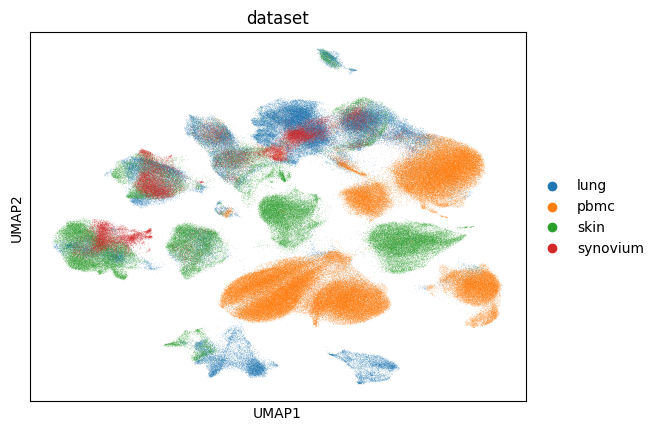

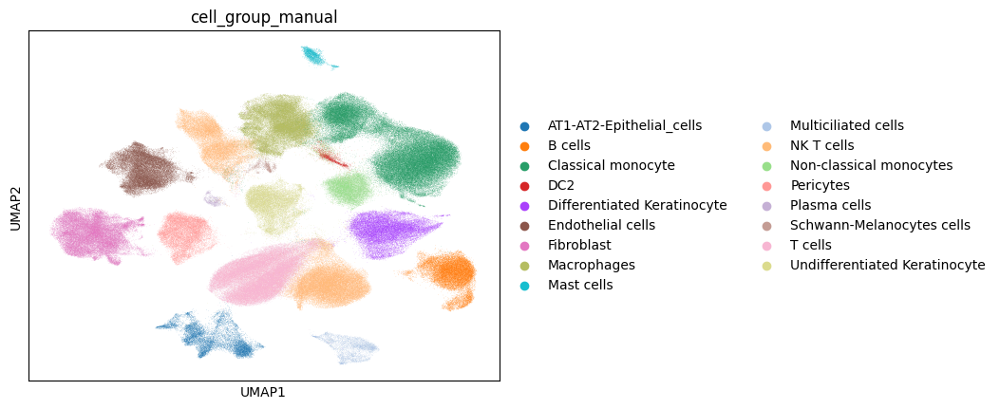

In [3]:
sc.pl.umap(adata_all, color=['dataset'])
sc.pl.umap(adata_all, color=['cell_group_manual'])


In [4]:
adata_all.obs

,sample,Condition,cell_group_manual,leiden_global,Organism,University,Age,Sex,Sequencer,chemistry,...,geo_accession,seurat_clusters,cell_type_celltypist,orig_index,tissue,dataset,apoptosis_score,stress_score,cell_group_lineage,decontX_contamination
GSE128169_SC109SSCUP_SC109SSCUP_1,SC109SSCUP,SSC,Classical monocyte,0,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Classical monocytes,NaN,lung,lung,-0.140000,6.134343,Myeloid cells,0.012835
GSE128169_SC109SSCUP_SC109SSCUP_2,SC109SSCUP,SSC,Macrophages,2,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Classical monocytes,NaN,lung,lung,0.975556,11.032323,Myeloid cells,0.007324
GSE128169_SC109SSCUP_SC109SSCUP_3,SC109SSCUP,SSC,AT1-AT2-Epithelial_cells,6,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,AT2,NaN,lung,lung,-0.128889,0.228283,Epithelial cells,0.005595
GSE128169_SC109SSCUP_SC109SSCUP_4,SC109SSCUP,SSC,Multiciliated cells,7,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Multiciliated,NaN,lung,lung,0.024444,-0.080808,Epithelial cells,0.049414
GSE128169_SC109SSCUP_SC109SSCUP_5,SC109SSCUP,SSC,Macrophages,2,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Classical monocytes,NaN,lung,lung,0.502222,-0.670707,Myeloid cells,0.082853
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSE00000_SB-095_SB-095_SB-095_TTTGGTTAGCACTCTA-1-GSE00000,SB-095,SSC,Macrophages,2,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,2.0,M1: MERTK+ SELENOP+ macrophages,SB-095_TTTGGTTAGCACTCTA-1-GSE00000,synovium,synovium,0.264444,7.011111,Myeloid cells,0.135197
GSE00000_SB-095_SB-095_SB-095_TTTGGTTGTCGTGATT-1-GSE00000,SB-095,SSC,Endothelial cells,11,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,0.0,E1: ICAM1+ venous,SB-095_TTTGGTTGTCGTGATT-1-GSE00000,synovium,synovium,-0.682222,0.909091,Endothelial cells,0.030557
GSE00000_SB-095_SB-095_SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,SB-095,SSC,Macrophages,2,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,0.0,M0: MERTK+ TIMD4+ macrophages,SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,synovium,synovium,1.300000,6.116162,Myeloid cells,0.123813
GSE00000_SB-095_SB-095_SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,SB-095,SSC,Macrophages,2,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,1.0,M1: MERTK+ SELENOP+ macrophages,SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,synovium,synovium,0.333333,2.260606,Myeloid cells,0.242589


In [5]:
print(adata_all)

AnnData object with n_obs × n_vars = 401902 × 22446
    obs: 'sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'Condition_colors', 'cell_group_colors', 'cell_group_leiden_colors', 'cell_group_manual_colors', 'cell_type_colors', 'dataset_colors', 'excluded_colors', 'hvg', 'leiden_global_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 

In [6]:
# Define the categories you want to keep
fibroblast_labels = ['Fibroblast']

# Subset the AnnData object
#adata_query = adata_query[adata_query.obs['leiden_r0.1'].isin(fibroblast_labels)].copy()
adata_all = adata_all[adata_all.obs['cell_group_manual'].isin(fibroblast_labels)].copy()

NORMALIZATION COMPARABILITY CHECK

[1/6] Loading dataset...
✓ Loaded: 33,468 cells × 22,446 genes
  Batches: ['GSE00000', 'GSE128169', 'GSE138669', 'GSE209635', 'GSE212109']

[3/6] Comparing value distributions across batches...
  (Using ALL cells - no subsampling)
  Processing GSE00000: 8,360 cells...
  Processing GSE128169: 2,801 cells...
  Processing GSE138669: 12,812 cells...
  Processing GSE209635: 6,042 cells...
  Processing GSE212109: 3,453 cells...
     (Distributions should look similar if normalization worked)


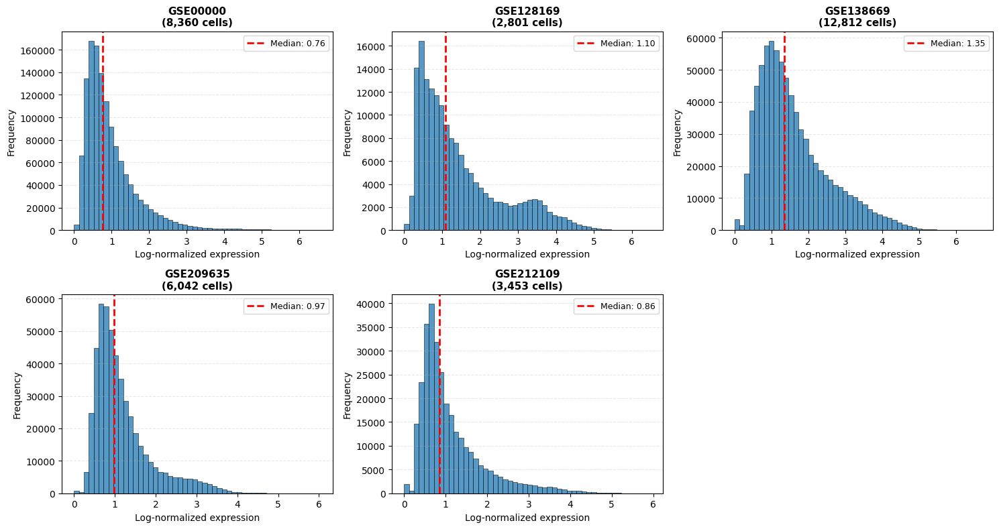

In [7]:

import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations


# ═══════════════════════════════════════════════════════════
# CONFIGURAZIONE
# ═══════════════════════════════════════════════════════════
BATCH_KEY = "batch"
CELLTYPE_KEY = "cell_group"

print("="*70)
print("NORMALIZATION COMPARABILITY CHECK")
print("="*70)

# ═══════════════════════════════════════════════════════════
# 1. CARICA DATI
# ═══════════════════════════════════════════════════════════

print("\n[1/6] Loading dataset...")
# Assume adata_all already loaded
print(f"✓ Loaded: {adata_all.n_obs:,} cells × {adata_all.n_vars:,} genes")

batches = sorted(adata_all.obs[BATCH_KEY].unique())
print(f"  Batches: {batches}")



print("\n[3/6] Comparing value distributions across batches...")
print("  (Using ALL cells - no subsampling)")

# Calculate grid layout
n_batches = len(batches)
n_cols = min(3, n_batches)
n_rows = int(np.ceil(n_batches / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
if n_batches == 1:
    axes = np.array([axes])
axes = axes.flatten()

for idx, batch in enumerate(batches):
    mask = adata_all.obs[BATCH_KEY] == batch
    batch_data = adata_all[mask]
    
    print(f"  Processing {batch}: {batch_data.n_obs:,} cells...")
    
    # Extract ALL values (no subsampling)
    if hasattr(batch_data.X, 'toarray'):
        # Sparse matrix - sample genes to avoid memory issues
        # Take all cells but sample 1000 random genes
        n_genes_sample = min(1000, batch_data.n_vars)
        gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
        values = batch_data.X[:, gene_idx].toarray().flatten()
    else:
        # Dense matrix - can handle all
        if batch_data.n_obs * batch_data.n_vars > 10_000_000:
            # Too big - sample
            n_genes_sample = min(1000, batch_data.n_vars)
            gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
            values = batch_data.X[:, gene_idx].flatten()
        else:
            values = np.array(batch_data.X).flatten()
    
    # Remove zeros for clearer visualization
    values_nonzero = values[values > 0]
    
    # Plot histogram
    axes[idx].hist(values_nonzero, bins=50, alpha=0.75, edgecolor='black', linewidth=0.5)
    axes[idx].axvline(np.median(values_nonzero), color='red', linestyle='--', 
                      linewidth=2, label=f'Median: {np.median(values_nonzero):.2f}')
    
    axes[idx].set_title(f"{batch}\n({batch_data.n_obs:,} cells)", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Log-normalized expression", fontsize=10)
    axes[idx].set_ylabel("Frequency", fontsize=10)
    axes[idx].legend(fontsize=9)
    axes[idx].grid(axis='y', alpha=0.3, linestyle='--')

# Hide empty subplots
for idx in range(n_batches, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
print("     (Distributions should look similar if normalization worked)")
#plt.close()

In [8]:
import pandas as pd

obs = adata_all.obs

# Number of unique patients per batch
patients_per_batch = obs.groupby("batch")["sample"].nunique()

# Number of unique patients per batch *and condition*
patients_condition = (
    obs.groupby(["batch", "Condition"])["sample"]
       .nunique()
       .unstack(fill_value=0)
)
# Rinomina le colonne per chiarezza
patients_condition.columns = [f"n_patients_{col}" for col in patients_condition.columns]

# Number of cells per batch
cells_per_batch = obs["batch"].value_counts().sort_index()

# Tissues represented in each batch
tissues_per_batch = obs.groupby("batch")["tissue"].unique()

# List of patient IDs per batch
patients_list = obs.groupby("batch")["sample"].unique()

# Combine everything into a single summary table
summary = pd.DataFrame({
    "n_patients_total": patients_per_batch,
    "n_cells": cells_per_batch,
    "tissues": tissues_per_batch,
    "patient_ids": patients_list
})

# Aggiungi per-condition patient counts
summary = pd.concat([summary, patients_condition], axis=1)

print(summary)

           n_patients_total  n_cells  \
batch                                  
GSE00000                  9     8360   
GSE128169                13     2801   
GSE138669                22    12812   
GSE209635                15     6042   
GSE212109                 9     3453   

                                                     tissues  \
batch                                                          
GSE00000   ['synovium']
Categories (3, object): ['lung', ...   
GSE128169  ['lung']
Categories (3, object): ['lung', 'ski...   
GSE138669  ['skin']
Categories (3, object): ['lung', 'ski...   
GSE209635  ['skin']
Categories (3, object): ['lung', 'ski...   
GSE212109  ['lung']
Categories (3, object): ['lung', 'ski...   

                                                 patient_ids  n_patients_CTRL  \
batch                                                                           
GSE00000   ['SB-089', 'SB-059', 'SB-116', 'TRA-021', 'SB-...                3   
GSE128169  ['SC109SSCUP', '

/tmp/ipykernel_1185785/196286925.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patients_per_batch = obs.groupby("batch")["sample"].nunique()
/tmp/ipykernel_1185785/196286925.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs.groupby(["batch", "Condition"])["sample"]
/tmp/ipykernel_1185785/196286925.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tissues_per_batch = obs.groupby("batch")["tissue"].unique()

In [9]:
adata_all

AnnData object with n_obs × n_vars = 33468 × 22446
    obs: 'sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'Condition_colors', 'cell_group_colors', 'cell_group_leiden_colors', 'cell_group_manual_colors', 'cell_type_colors', 'dataset_colors', 'excluded_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'


In [10]:
adata_all.obs["cell_group_manual"].unique()

['Fibroblast']
Categories (1, object): ['Fibroblast']

In [11]:
# --- 4) Highly Variable Genes ---
sc.pp.highly_variable_genes(adata_all, flavor="seurat", n_top_genes=1000)

# DO NOT subset the object
# adata_all = adata_all[:, adata_all.var["highly_variable"]].copy()   

# --- 5) PCA using only HVGs ---
sc.tl.pca(adata_all, use_highly_variable=True, svd_solver="arpack")

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


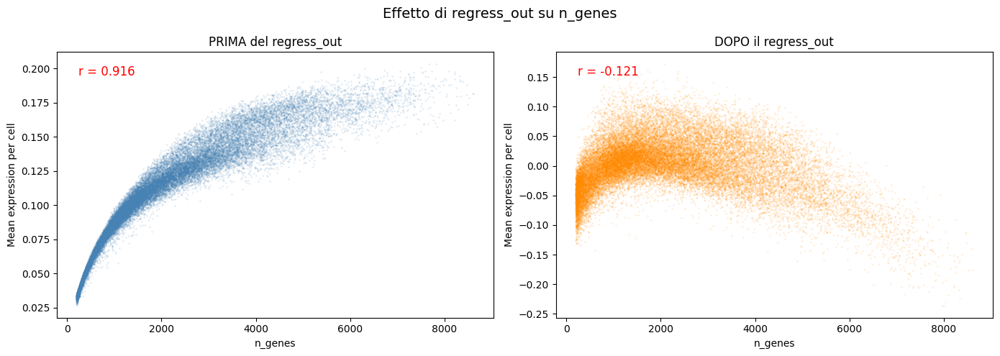

n_genes — Correlazione PRIMA: 0.9158 | DOPO: -0.1208


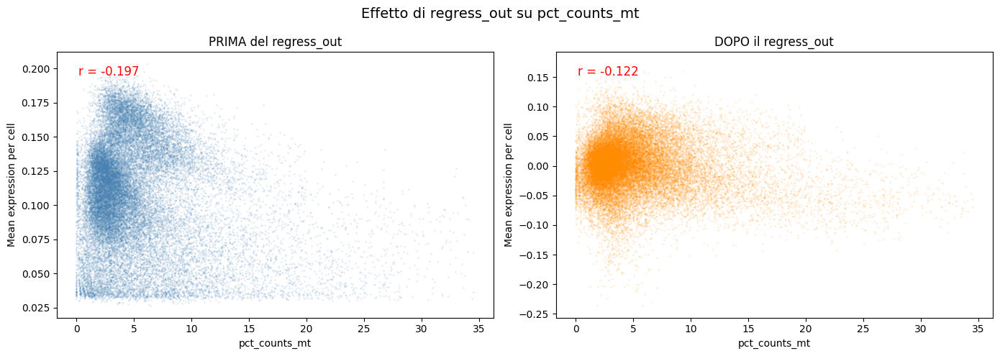

pct_counts_mt — Correlazione PRIMA: -0.1970 | DOPO: -0.1216


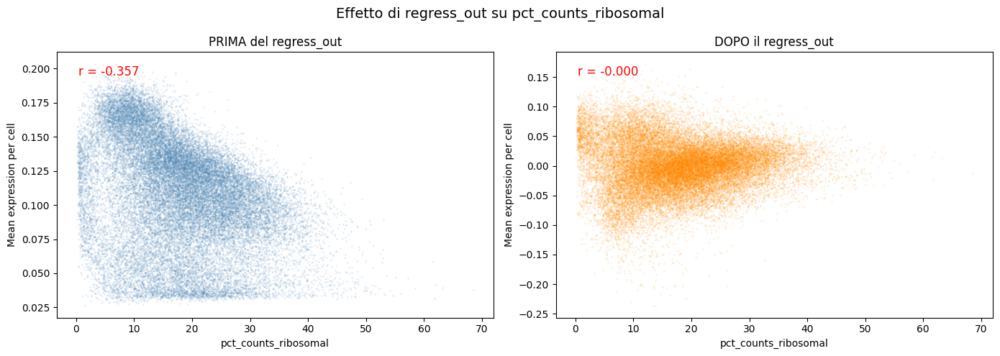

pct_counts_ribosomal — Correlazione PRIMA: -0.3568 | DOPO: -0.0000

Correlazione n_genes vs PC1: -0.0720 | PC2: -0.0644

Correlazione pct_counts_mt vs PC1: -0.1057 | PC2: -0.0559

Correlazione pct_counts_ribosomal vs PC1: -0.0000 | PC2: 0.0000


2026-09-28 08:10:53,410 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-09-28 08:11:00,430 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-09-28 08:11:01,018 - harmonypy - INFO - Iteration 1 of 25
2026-09-28 08:12:12,507 - harmonypy - INFO - Iteration 2 of 25
2026-09-28 08:13:21,521 - harmonypy - INFO - Iteration 3 of 25
2026-09-28 08:14:30,811 - harmonypy - INFO - Iteration 4 of 25
2026-09-28 08:15:39,921 - harmonypy - INFO - Iteration 5 of 25
2026-09-28 08:16:48,837 - harmonypy - INFO - Converged after 5 iterations
/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [12]:
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
import numpy as np

# ── SUBSET HVG ───────────────────────────────────────────────────────────────
adata_all_hvg = adata_all[:, adata_all.var["highly_variable"]].copy()

# ── REGRESS OUT ───────────────────────────────────────────────────────────────
sc.pp.regress_out(adata_all_hvg, ["n_genes"])
sc.pp.regress_out(adata_all_hvg, ["pct_counts_mt"])
sc.pp.regress_out(adata_all_hvg, ["pct_counts_ribosomal"])

# ── VALORI PRE/POST ───────────────────────────────────────────────────────────
mean_expr_before = np.array(adata_all.X.mean(axis=1)).flatten()
mean_expr_after  = np.array(adata_all_hvg.X.mean(axis=1)).flatten()

n_genes          = adata_all_hvg.obs["n_genes"].values
pct_counts_mt    = adata_all_hvg.obs["pct_counts_mt"].values
pct_counts_rb    = adata_all_hvg.obs["pct_counts_ribosomal"].values

# ── FUNZIONE HELPER ───────────────────────────────────────────────────────────
def plot_regress_validation(var_values, var_name, before, after):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # nuova figura ogni volta

    corr_before = np.corrcoef(var_values, before)[0, 1]
    corr_after  = np.corrcoef(var_values, after)[0, 1]

    axes[0].scatter(var_values, before, alpha=0.1, s=1, color="steelblue")
    axes[0].set_xlabel(var_name)
    axes[0].set_ylabel("Mean expression per cell")
    axes[0].set_title("PRIMA del regress_out")
    axes[0].text(0.05, 0.95, f"r = {corr_before:.3f}", transform=axes[0].transAxes,
                 fontsize=12, color="red", va="top")

    axes[1].scatter(var_values, after, alpha=0.1, s=1, color="darkorange")
    axes[1].set_xlabel(var_name)
    axes[1].set_ylabel("Mean expression per cell")
    axes[1].set_title("DOPO il regress_out")
    axes[1].text(0.05, 0.95, f"r = {corr_after:.3f}", transform=axes[1].transAxes,
                 fontsize=12, color="red", va="top")

    plt.suptitle(f"Effetto di regress_out su {var_name}", fontsize=14)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    print(f"{var_name} — Correlazione PRIMA: {corr_before:.4f} | DOPO: {corr_after:.4f}")

# ── PLOT ──────────────────────────────────────────────────────────────────────
plot_regress_validation(n_genes,       "n_genes",            mean_expr_before, mean_expr_after)
plot_regress_validation(pct_counts_mt, "pct_counts_mt",      mean_expr_before, mean_expr_after)
plot_regress_validation(pct_counts_rb, "pct_counts_ribosomal", mean_expr_before, mean_expr_after)

# ── PCA ───────────────────────────────────────────────────────────────────────
sc.tl.pca(adata_all_hvg, svd_solver="arpack")

for var_values, var_name in [
    (n_genes,       "n_genes"),
    (pct_counts_mt, "pct_counts_mt"),
    (pct_counts_rb, "pct_counts_ribosomal"),
]:
    corr_pc1 = np.corrcoef(var_values, adata_all_hvg.obsm["X_pca"][:, 0])[0, 1]
    corr_pc2 = np.corrcoef(var_values, adata_all_hvg.obsm["X_pca"][:, 1])[0, 1]
    print(f"\nCorrelazione {var_name} vs PC1: {corr_pc1:.4f} | PC2: {corr_pc2:.4f}")

# ── HARMONY + UMAP ───────────────────────────────────────────────────────────
sce.pp.harmony_integrate(adata_all_hvg, "sample", max_iter_harmony=25)
sc.pp.neighbors(adata_all_hvg, use_rep="X_pca_harmony", n_neighbors=15)
sc.tl.umap(adata_all_hvg)

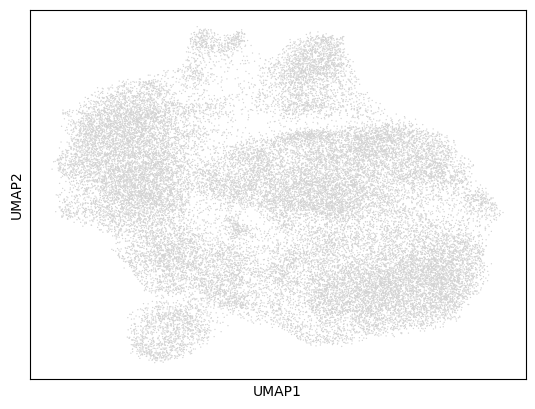

✅ Harmony integration completed and UMAP computed!


In [13]:
# --- 7) Recompute neighbors + UMAP using Harmony embedding ---
#sc.pp.neighbors(adata_all, use_rep="X_pca_harmony", n_neighbors=15, n_pcs=50)
#sc.tl.umap(adata_all)
sc.pl.umap(adata_all_hvg)
# --- 8) Save the integrated object ---
#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Integrated_SSC_Harmony.h5ad")

print("✅ Harmony integration completed and UMAP computed!")

In [14]:
sc.tl.leiden(
    adata_all_hvg,
    resolution=1.5,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="fibroblast_subpopulation" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

In [15]:
# Trasferisci l'UMAP da fib_hvg a fib
adata_all.obsm["X_umap"] = adata_all_hvg.obsm["X_umap"]
adata_all.obsm["X_pca_harmony"] = adata_all_hvg.obsm["X_pca_harmony"]

['0', '1', '7', '6', '3', ..., '17', '15', '20', '16', '21']
Length: 22
Categories (22, object): ['0', '1', '2', '3', ..., '18', '19', '20', '21']


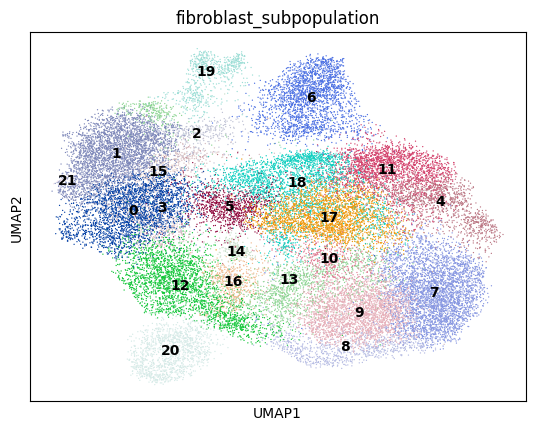

In [34]:
print(adata_all_hvg.obs['fibroblast_subpopulation'].unique())
sc.pl.umap(adata_all_hvg, color='fibroblast_subpopulation', legend_loc='on data')
adata_all.obs["fibroblast_subpopulation"] = adata_all_hvg.obs["fibroblast_subpopulation"]

In [35]:
# Salva l'assegnazione cluster con l'indice (cell barcode) per riuso futuro
# senza dover rifare l'intero pipeline di integrazione/clustering
fibroblast_subpop_export = adata_all.obs[['fibroblast_subpopulation']].copy()
fibroblast_subpop_export.index.name = 'cell_id'
fibroblast_subpop_export.to_csv('fibroblast_subpopulation_assignment.csv')

In [36]:
#TRANSFER ANNOTATION ONLY SKIN


import pandas as pd

# Mapping numero cluster -> annotazione
cluster_annotation = {
    0:  "F2_Universal/Progenitor_C5(PI16, CD34, MFAP5)",
    1:  "F2_Universal/Progenitor_C5(PI16, CD34, MFAP5)",
    2:  "F2_Universal/Myofibroblast",
    3:  "F1_superficial_papillary",
    4:  "F1_superficial_papillary",
    5:  "FOSB+_population",
    6:  "F4_Dermal_sheath_population",
    7:  "F4_hair_follicle(TNN+COCH+)",
    8:  "F2-3_perivascular",
    9:  "F3_Fibroblastic_reticular_cell-like_fibroblasts_1",
    10: "F3_Fibroblastic_reticular_cell-like_fibroblasts_2",
    11: "F5_Schwann-like_fibroblasts",
    12: "F5_Schwann-like_fibroblasts_(EBF2, NGFR+)",
}

# 1. Carica il file con cell_id e fibroblast_subpopulation (numerico)
#    aggiorna il path/formato in base a come l'hai salvato (csv, tsv, xlsx...)
cluster_df = pd.read_csv("fibroblast_subpopulation_assignment_SKIN.csv")  # oppure pd.read_excel(...)

# Controllo rapido
print(cluster_df.head())
print(cluster_df["fibroblast_subpopulation"].unique())

# 2. Applica il mapping
cluster_df["fibroblast_skin_annotation"] = cluster_df["fibroblast_subpopulation"].map(cluster_annotation)

# Verifica che non ci siano numeri non mappati (NaN)
n_missing = cluster_df["fibroblast_skin_annotation"].isna().sum()
if n_missing > 0:
    print(f"Attenzione: {n_missing} righe con cluster non mappato:")
    print(cluster_df.loc[cluster_df["fibroblast_skin_annotation"].isna(), "fibroblast_subpopulation"].unique())

# 3. Imposta cell_id come indice per allinearlo facilmente ad adata_all
cluster_df = cluster_df.set_index("cell_id")

# 4. Aggiungi la colonna ad adata_all.obs, allineando per cell_id (index)
#    Assumendo che adata_all.obs_names corrisponda a cell_id
adata_all.obs["fibroblast_skin_annotation"] = cluster_df["fibroblast_skin_annotation"].reindex(adata_all.obs_names)

# Controllo: quante cellule di adata_all hanno ricevuto un'annotazione
print(adata_all.obs["fibroblast_skin_annotation"].value_counts(dropna=False))

                    cell_id  fibroblast_subpopulation
0   GSE138669_SC124_SC124_5                         0
1  GSE138669_SC124_SC124_10                         5
2  GSE138669_SC124_SC124_17                         6
3  GSE138669_SC124_SC124_23                         8
4  GSE138669_SC124_SC124_29                         4
[ 0  5  6  8  4  7  2  3  9  1 11 10 12]
fibroblast_skin_annotation
NaN                                                  14614
F1_superficial_papillary                              3766
F2_Universal/Progenitor_C5(PI16, CD34, MFAP5)         3596
F2-3_perivascular                                     2825
F3_Fibroblastic_reticular_cell-like_fibroblasts_1     2454
F4_Dermal_sheath_population                           1672
F4_hair_follicle(TNN+COCH+)                           1603
F3_Fibroblastic_reticular_cell-like_fibroblasts_2      963
F2_Universal/Myofibroblast                             643
FOSB+_population                                       629
F5_Schwann-like_fi

['lung', 'skin', 'synovium']
Categories (3, object): ['lung', 'skin', 'synovium']
N. cellule skin: 18854
True


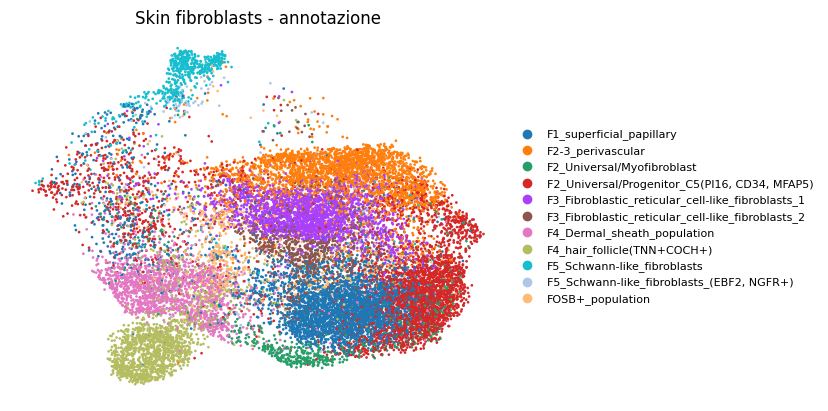

In [37]:
import scanpy as sc
import matplotlib.pyplot as plt

# 1. Controlla i valori unici della colonna tissue (per essere sicuri della stringa esatta)
print(adata_all.obs["tissue"].unique())

# 2. Subset solo skin
adata_skin = adata_all[adata_all.obs["tissue"] == "skin"].copy()
print(f"N. cellule skin: {adata_skin.n_obs}")

# 3. Controlla che l'UMAP sia già calcolato su adata_all (embedding condiviso)
#    Se X_umap è già in adata_all.obsm, il subset lo mantiene automaticamente
print("X_umap" in adata_skin.obsm)

# 4. Plot UMAP colorato per annotazione fibroblastica
sc.pl.umap(
    adata_skin,
    color="fibroblast_skin_annotation",
    legend_loc="right margin",
    legend_fontsize=8,
    size=15,
    frameon=False,
    title="Skin fibroblasts - annotazione",
    show=True,
)

In [38]:
#OLD ANNOTATION MORE FINE GRAINED.


import pandas as pd

# Mapping numero cluster -> annotazione finale (chiavi numeriche, senza prefisso "S")
cluster_annotation = {
    "0":  "Synov_Lining",
    "21": "Synov_Lining",

    "1":  "Pan_Intermediate_PRG4pos",
    "3":  "Pan_Intermediate_PRG4pos",
    "15": "Pan_Intermediate_PRG4pos",      # vedi nota 2

    "2":  "Lung_Alveolar_ADH1B",
    "6":  "Lung_Alveolar_ADH1B",

    "7":  "Pan_Progenitor_like_PB_MFAP5",  # vedi nota 1
    "4":  "Pan_Progenitor_like_PB_MFAP5",

    "8":  "Pan_Myofibroblast_COMP_ACTA2",

    "9":  "Skin_Superficial_papillary",

    "10": "Mixed",
    "13": "Mixed",
    "14": "Mixed",

    "5":  "Pan_F2_3_Like_perivascular",
    "11": "Pan_F2_3_Like_perivascular",
    "18": "Pan_F2_3_Like_perivascular",
    "17": "Pan_F2_3_Like_perivascular",                 # vedi nota 3

    "12": "Skin_F4_Dermal_sheath_FB",
    "16": "Skin_F4_Dermal_sheath_FB",
    "20": "Skin_F4_Dermal_sheath_FB",

    "19": "F5_Schwann_like_fibroblast",    # vedi nota 4
}
# 1. Verifica PRIMA di sovrascrivere: quali valori originali non sono nel mapping
orig = adata_all.obs["fibroblast_subpopulation"].astype(str)
unmapped = sorted(set(orig.unique()) - set(cluster_annotation.keys()))
if unmapped:
    print(f"Attenzione: {len(unmapped)} cluster originali non presenti nel mapping:")
    print(unmapped)
else:
    print("Tutti i cluster originali sono coperti dal mapping.")

# 2. Applica il mapping
adata_all.obs["fibroblast_subpopulation"] = orig.map(cluster_annotation)

# 3. Controllo NaN residui dopo il mapping
n_missing = adata_all.obs["fibroblast_subpopulation"].isna().sum()
if n_missing > 0:
    print(f"Attenzione: {n_missing} cellule con annotazione mancante dopo il mapping.")

# 4. Riepilogo finale
print(adata_all.obs["fibroblast_subpopulation"].value_counts())

Tutti i cluster originali sono coperti dal mapping.
fibroblast_subpopulation
Pan_F2_3_Like_perivascular      8195
Pan_Progenitor_like_PB_MFAP5    4807
Skin_F4_Dermal_sheath_FB        4350
Pan_Intermediate_PRG4pos        4345
Lung_Alveolar_ADH1B             2645
Skin_Superficial_papillary      2623
Synov_Lining                    2620
Mixed                           2258
Pan_Myofibroblast_COMP_ACTA2     909
F5_Schwann_like_fibroblast       716
Name: count, dtype: int64


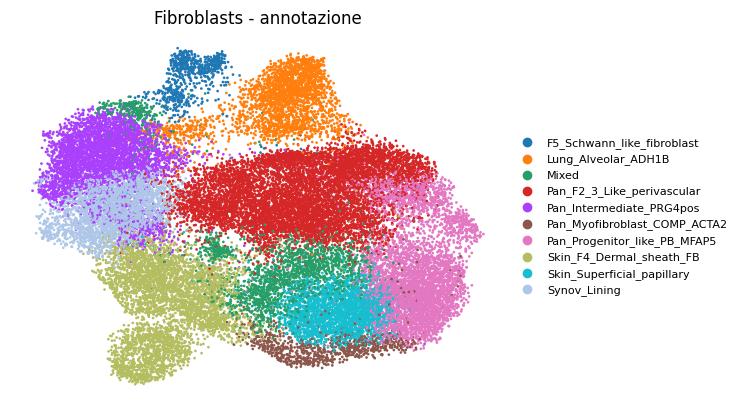

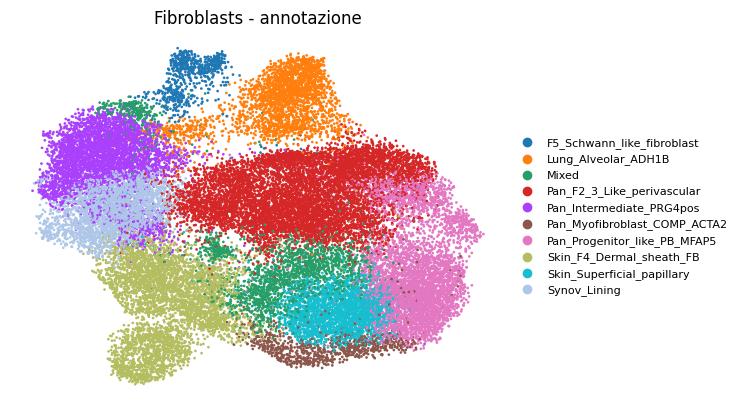

In [50]:
sc.pl.umap(
    adata_all,
    color="fibroblast_subpopulation",
    legend_loc="right margin",
    legend_fontsize=8,
    size=15,
    frameon=False,
    title="Fibroblasts - annotazione",
    show=True,
)

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import random


np.random.seed(0)
random.seed(0)


#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Fibroblast.h5ad")
adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Fibroblast.h5ad")

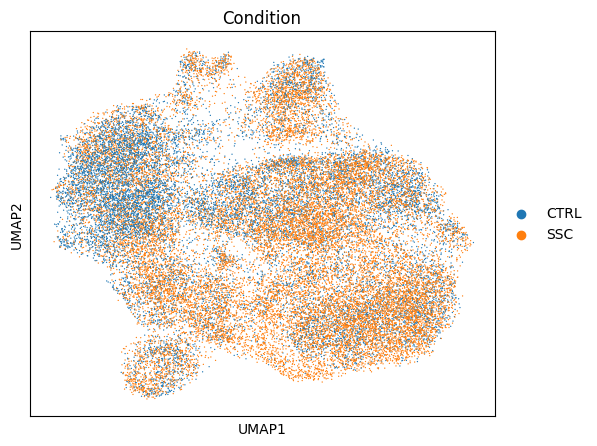

In [51]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 5)  # larghezza, altezza in pollici
sc.pl.umap(adata_all, color=['Condition'])

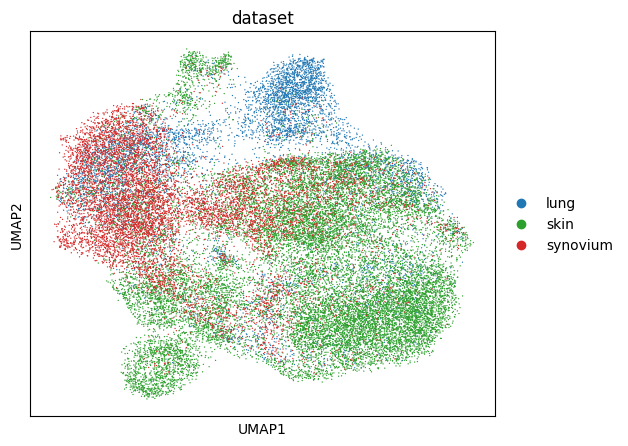

In [52]:
sc.pl.umap(adata_all, color=['dataset'])

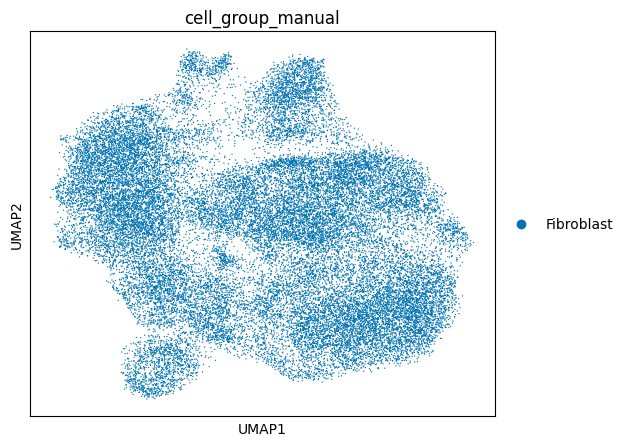

In [53]:
custom_colors = ["#0072B2", "#E69F00", "#009E73"]  # blu / arancio / verde

sc.pl.umap(
    adata_all,
    color=['cell_group_manual'],
    palette=custom_colors,
    show=False,
)
plt.show()

In [54]:
adata_all

AnnData object with n_obs × n_vars = 33468 × 22446
    obs: 'sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination', 'fibroblast_subpopulation', 'fibroblast_skin_annotation'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'Condition_colors', 'cell_group_colors', 'cell_group_leiden_colors', 'cell_group_manual_colors', 'cell_type_colors', 'dataset_colors', 'excluded_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap', 'f

/tmp/ipykernel_1185785/979999835.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['sample', 'fibroblast_subpopulation']).size().reset_index(name='count')


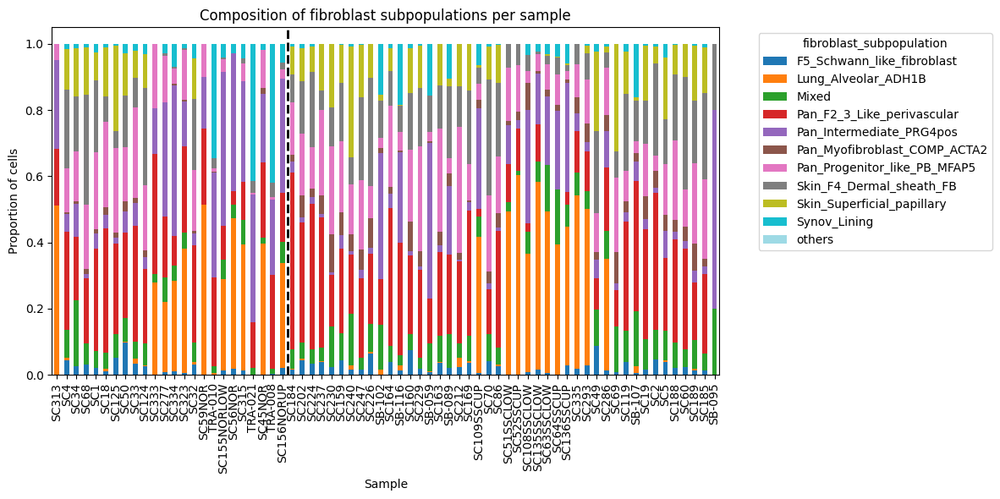

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

df = adata_all.obs[['sample', 'fibroblast_subpopulation', 'Condition']].copy()
df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].astype('category')
df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].cat.add_categories('others')
df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].fillna('others')

counts = df.groupby(['sample', 'fibroblast_subpopulation']).size().reset_index(name='count')
counts_pivot = counts.pivot(index='sample', columns='fibroblast_subpopulation', values='count').fillna(0)
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)

# --- Unica aggiunta: ordina per condizione ---
sample_condition = df[['sample', 'Condition']].drop_duplicates().set_index('sample')
counts_prop = counts_prop.loc[sample_condition.sort_values('Condition').index]

# Plot
ax = counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    colormap='tab20'
)

# --- Linea verticale per separare le condizioni ---
condition_sizes = sample_condition.sort_values('Condition')['Condition'].value_counts(sort=False)
split = condition_sizes.iloc[0]  # numero di campioni della prima condizione
ax.axvline(x=split - 0.5, color='black', linewidth=2, linestyle='--')

plt.ylabel('Proportion of cells')
plt.xlabel('Sample')
plt.title('Composition of fibroblast subpopulations per sample')
plt.legend(title='fibroblast_subpopulation', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1185785/3308774664.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['Condition', 'fibroblast_subpopulation']).size().reset_index(name='count')


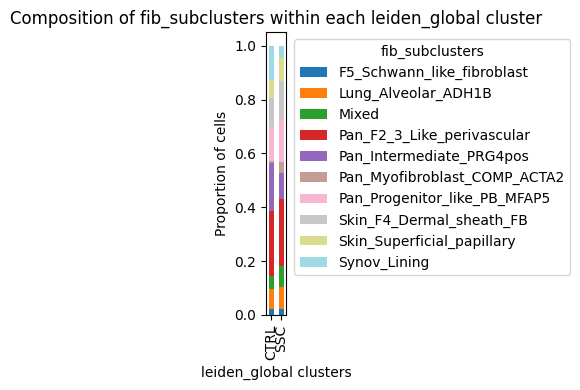

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Copy relevant columns
df = adata_all.obs[['Condition', 'fibroblast_subpopulation']].copy()
# Ensure 'fib_subclusters' is categorical
df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].astype('category')
# Add 'others' to the categories
#df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].cat.add_categories('others')
# Fill missing values with 'others'
#df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].fillna('others')
# Compute counts per cluster
counts = df.groupby(['Condition', 'fibroblast_subpopulation']).size().reset_index(name='count')
# Pivot for stacked bar plot
counts_pivot = counts.pivot(index='Condition', columns='fibroblast_subpopulation', values='count').fillna(0)
# Optional: convert to proportions
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)
# Plot
counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(4,4),
    colormap='tab20'
)
plt.ylabel('Proportion of cells')
plt.xlabel('leiden_global clusters')
plt.title('Composition of fib_subclusters within each leiden_global cluster')
plt.legend(title='fib_subclusters', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

Geni trovati in raw: ['POSTN', 'COMP', 'OAS1', 'CD20', 'KRT2', 'KRT17', 'KRT6A', 'KRT1', 'KAZN', 'PKP1', 'KRT31']
      gene      fibroblast_subpopulation  mean_expr   pct_expr  n_cells
0     CD20    F5_Schwann_like_fibroblast   0.000000   0.000000      716
1     CD20           Lung_Alveolar_ADH1B   0.000000   0.000000     2645
2     CD20                         Mixed   0.000000   0.000000     2258
3     CD20    Pan_F2_3_Like_perivascular   0.000000   0.000000     8195
4     CD20      Pan_Intermediate_PRG4pos   0.000000   0.000000     4345
..     ...                           ...        ...        ...      ...
105  POSTN  Pan_Myofibroblast_COMP_ACTA2   2.530602  79.757976      909
106  POSTN  Pan_Progenitor_like_PB_MFAP5   1.211131  48.533389     4807
107  POSTN      Skin_F4_Dermal_sheath_FB   1.534475  52.735632     4350
108  POSTN    Skin_Superficial_papillary   1.094228  45.406024     2623
109  POSTN                  Synov_Lining   0.090029   6.183206     2620

[110 rows x 5 columns

/tmp/ipykernel_1185785/2033937250.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_long.groupby(["gene", CLUSTER_COL])["expr"]


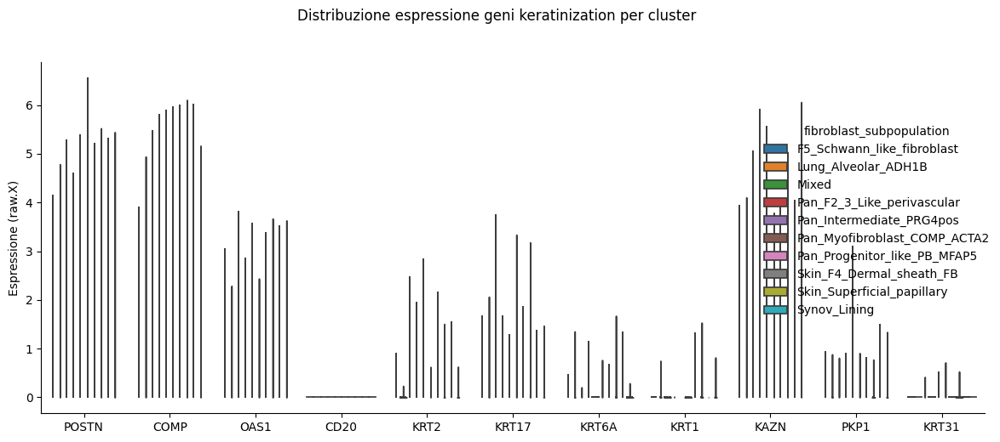

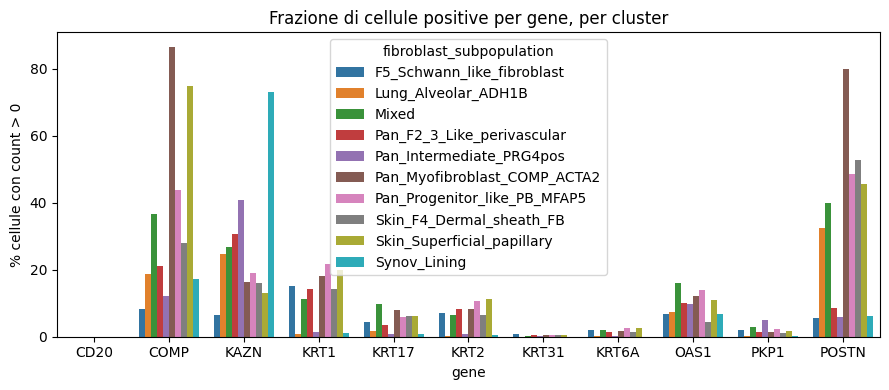

In [57]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Adatta questa riga: rimuovi/sostituisci se adata_all è già in memoria ---
# adata_all = sc.read_h5ad("path/al/tuo/file.h5ad")

CLUSTER_COL = "fibroblast_subpopulation"  # <-- cambia se il nome della colonna cluster è diverso

#genes = ["KRT6A", "KRT1", "KAZN", "PKP1", "KRT31", "KRT2", "KRT17"]
genes = ["POSTN", "COMP", "IF44", "OAS1", "CD20", "KRT2", "KRT17", "KRT6A", "KRT1", "KAZN", "PKP1", "KRT31"]

genes = [g for g in genes if g in adata_all.var_names]
print("Geni trovati in raw:", genes)

# --- 2. Estrai da raw.X ---
X = adata_all[:, genes].X
X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)

# --- 3. Dataframe long-form, stratificato solo per cluster ---
df = pd.DataFrame(X, columns=genes, index=adata_all.obs_names)
df[CLUSTER_COL] = adata_all.obs[CLUSTER_COL].values

df_long = df.melt(id_vars=[CLUSTER_COL], value_vars=genes,
                   var_name="gene", value_name="expr")

# --- 4. Riepilogo: media + % cellule positive per cluster ---
summary = (
    df_long.groupby(["gene", CLUSTER_COL])["expr"]
    .agg(mean_expr="mean", pct_expr=lambda x: 100 * (x > 0).mean(), n_cells="size")
    .reset_index()
)
print(summary)

# --- 5. Plot: violin per gene, colorato per cluster ---
g = sns.catplot(
    data=df_long, x="gene", y="expr", hue=CLUSTER_COL,
    kind="violin", inner="quartile", height=5, aspect=1.8, cut=0,
)
g.set_axis_labels("", "Espressione (raw.X)")
g.fig.suptitle("Distribuzione espressione geni keratinization per cluster", y=1.03)
plt.tight_layout()

# --- 6. Barplot % cellule positive per cluster (chiave per capire se è ambient RNA) ---
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=summary, x="gene", y="pct_expr", hue=CLUSTER_COL, ax=ax)
ax.set_ylabel("% cellule con count > 0")
ax.set_title("Frazione di cellule positive per gene, per cluster")
plt.tight_layout()

Saved: Figures/fibroblast_composition_by_organ.svg


/tmp/ipykernel_1185785/234345013.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_1185785/234345013.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_1185785/234345013.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts =

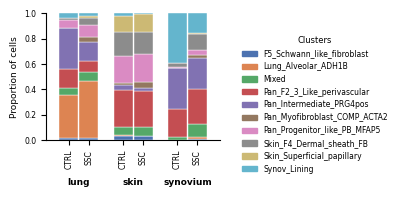

In [58]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Unified palette & order — reuse for Lymphoid, Myeloid, Endothelial, Epithelial ──
SUBPOP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2",
    "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD",
]
TISSUE_ORDER    = ["lung", "skin", "synovium", "pbmc"]
CONDITION_ORDER = ["CTRL", "SSC"]


def plot_condition_composition_by_organ(
    obs_df, subpop_col, tissue_col="Tissue", condition_col="Condition",
    tissue_order=TISSUE_ORDER, condition_order=CONDITION_ORDER,
    palette=SUBPOP_PALETTE,
    fig_width=4.0, fig_height=2.2,     # <-- modifica qui la dimensione della figura
    bar_width=0.35, group_gap=0.25,    # larghezza barre e spazio tra gruppi tessuto
    title=None,
    save_path=None                    # <-- percorso completo del file da salvare (es. "Figures/fig.svg")
):
    df = obs_df[[condition_col, tissue_col, subpop_col]].copy()
    df[subpop_col] = df[subpop_col].astype("category")
    categories = list(df[subpop_col].cat.categories)
    color_map = {c: palette[i % len(palette)] for i, c in enumerate(categories)}

    tissues = [t for t in tissue_order if t in df[tissue_col].unique()]
    n_cond = len(condition_order)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    group_centers = np.arange(len(tissues))
    offsets = (np.arange(n_cond) - (n_cond - 1) / 2) * (bar_width + 0.02)

    for tissue_idx, tissue in enumerate(tissues):
        sub = df[df[tissue_col] == tissue]
        counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
        counts = counts.reindex(index=[c for c in condition_order if c in counts.index])
        props = counts.div(counts.sum(axis=1), axis=0)

        for cond_idx, cond in enumerate(props.index):
            x = group_centers[tissue_idx] + offsets[cond_idx]
            bottom = 0.0
            for cat in categories:
                if cat not in props.columns:
                    continue
                val = props.loc[cond, cat]
                ax.bar(x, val, bottom=bottom, width=bar_width,
                       color=color_map[cat], edgecolor="white", linewidth=0.3)
                bottom += val

    xtick_pos, xtick_labels = [], []
    for tissue_idx, tissue in enumerate(tissues):
        for cond_idx, cond in enumerate(condition_order):
            xtick_pos.append(group_centers[tissue_idx] + offsets[cond_idx])
            xtick_labels.append(cond)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(xtick_labels, fontsize=5.5, rotation=90)

    for tissue_idx, tissue in enumerate(tissues):
        ax.text(group_centers[tissue_idx], -0.30, tissue,
                ha="center", va="top", fontsize=6.5, fontweight="bold",
                transform=ax.get_xaxis_transform())

    ax.set_ylim(0, 1)
    ax.set_ylabel("Proportion of cells", fontsize=6.5)
    ax.tick_params(axis="y", labelsize=5.5)
    ax.set_xlim(group_centers[0] - 0.6, group_centers[-1] + 0.6)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[c]) for c in categories]
    fig.legend(handles, categories, title="Clusters", fontsize=5.5, title_fontsize=6,
               bbox_to_anchor=(1.0, 0.5), loc="center left", frameon=False)

    if title:
        fig.suptitle(title, fontsize=7, y=1.05)

    plt.tight_layout()

    if save_path is not None:
        out_dir = os.path.dirname(save_path)
        if out_dir:
            os.makedirs(out_dir, exist_ok=True)
        fig.savefig(save_path, format="svg", bbox_inches="tight")
        print(f"Saved: {save_path}")

    return fig, ax, color_map


# ── Usage ──────────────────────────────────────────────────────────────────
fig, ax, color_map = plot_condition_composition_by_organ(
    adata_all.obs, subpop_col="fibroblast_subpopulation",
    tissue_col="tissue", condition_col="Condition",
    fig_width=2.4, fig_height=2.2,
    save_path="Figures/fibroblast_composition_by_organ.svg"
)
plt.show()

/tmp/ipykernel_1185785/3877230538.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['tissue', 'fibroblast_subpopulation']).size().reset_index(name='count')


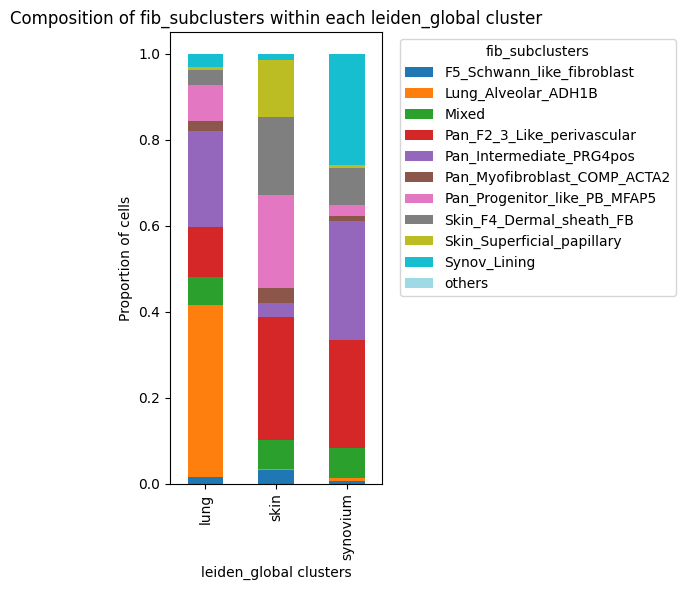

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Copy relevant columns
df = adata_all.obs[['tissue', 'fibroblast_subpopulation']].copy()
# Ensure 'fib_subclusters' is categorical
df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].astype('category')
# Add 'others' to the categories
df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].cat.add_categories('others')
# Fill missing values with 'others'
df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].fillna('others')
# Compute counts per cluster
counts = df.groupby(['tissue', 'fibroblast_subpopulation']).size().reset_index(name='count')
# Pivot for stacked bar plot
counts_pivot = counts.pivot(index='tissue', columns='fibroblast_subpopulation', values='count').fillna(0)
# Optional: convert to proportions
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)
# Plot
counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(6,6),
    colormap='tab20'
)
plt.ylabel('Proportion of cells')
plt.xlabel('leiden_global clusters')
plt.title('Composition of fib_subclusters within each leiden_global cluster')
plt.legend(title='fib_subclusters', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1185785/736997347.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['fibroblast_subpopulation', 'tissue']).size().reset_index(name='count')


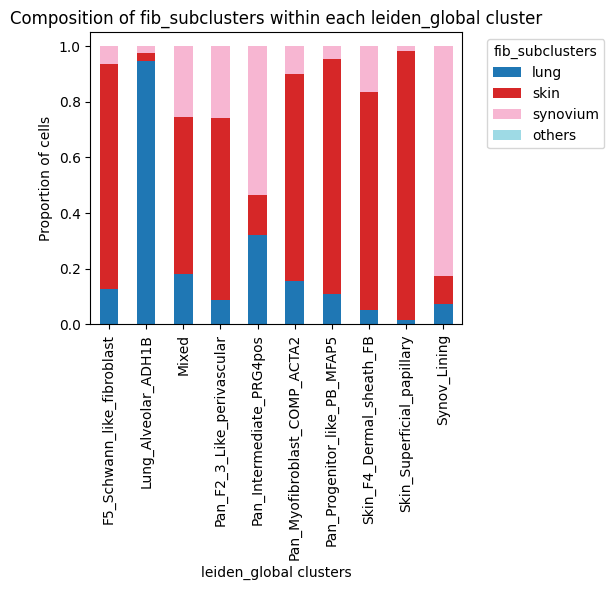

In [60]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Copy relevant columns
df = adata_all.obs[['fibroblast_subpopulation', 'tissue']].copy()
# Ensure 'fib_subclusters' is categorical
df['tissue'] = df['tissue'].astype('category')
# Add 'others' to the categories
df['tissue'] = df['tissue'].cat.add_categories('others')
# Fill missing values with 'others'
df['tissue'] = df['tissue'].fillna('others')
# Compute counts per cluster
counts = df.groupby(['fibroblast_subpopulation', 'tissue']).size().reset_index(name='count')
# Pivot for stacked bar plot
counts_pivot = counts.pivot(index='fibroblast_subpopulation', columns='tissue', values='count').fillna(0)
# Optional: convert to proportions
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)
# Plot
counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(6,6),
    colormap='tab20'
)
plt.ylabel('Proportion of cells')
plt.xlabel('leiden_global clusters')
plt.title('Composition of fib_subclusters within each leiden_global cluster')
plt.legend(title='fib_subclusters', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

Ambient genes trovati: 13/13


<Axes: title={'center': 'Ambient RNA score'}, xlabel='UMAP1', ylabel='UMAP2'>

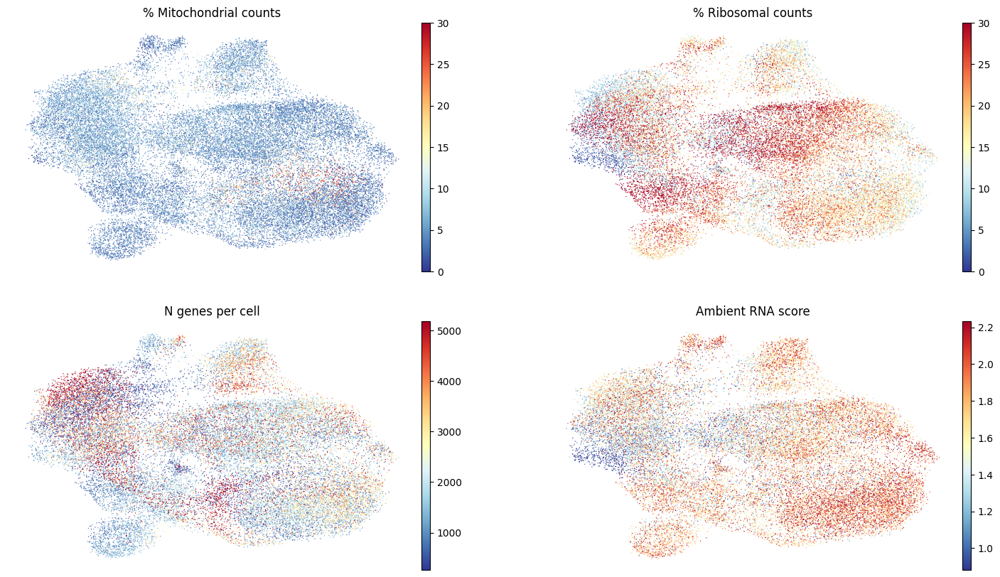

In [61]:
import matplotlib.pyplot as plt
import numpy as np


# ── GENE SIGNATURES ──────────────────────────────────────────────────────────
# Ambient RNA / housekeeping genes — highly expressed in empty droplets
ambient_genes = [
    "MALAT1", "NEAT1",                          # lncRNA ubiqui nell'ambient RNA
    "ACTB", "ACTG1",                            # actina
    "GAPDH", "LDHA",                            # glicolisi
    "B2M",                                      # MHC I ubiquo
    "FTL", "FTH1",                              # ferritina — molto abbondante
    "TMSB4X", "TMSB10",                         # thymosine — ambient marker
    "S100A4", "VIM",                            # proteine strutturali ubique
]

ambient_present = [g for g in ambient_genes if g in adata_all.var_names]
missing = [g for g in ambient_genes if g not in adata_all.var_names]
print(f"Ambient genes trovati: {len(ambient_present)}/{len(ambient_genes)}")
if missing:
    print(f"Mancanti: {missing}")

sc.tl.score_genes(adata_all, ambient_present, score_name="ambient_score")


fig, axes = plt.subplots(2, 2, figsize=(18, 10))


# ── PLOT 2: UMAP % mitocondriale ─────────────────────────────────────────────
sc.pl.umap(
    adata_all,
    color="pct_counts_mt",
    ax=axes[0, 0],
    show=False,
    frameon=False,
    title="% Mitochondrial counts",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=30,
)

# ── PLOT 3: UMAP % ribosomiale ───────────────────────────────────────────────
sc.pl.umap(
    adata_all,
    color="pct_counts_ribosomal",
    ax=axes[0, 1],
    show=False,
    frameon=False,
    title="% Ribosomal counts",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=30,
)

# ── UMAP: n_genes ─────────────────────────────────────────────────────────────
sc.pl.umap(adata_all, color="n_genes",
           ax=axes[1, 0], show=False, frameon=False,
           title="N genes per cell",
           cmap="RdYlBu_r",
           vmin=adata_all.obs["n_genes"].quantile(0.05),
           vmax=adata_all.obs["n_genes"].quantile(0.95))

# ── UMAP: ambient score ───────────────────────────────────────────────────────
sc.pl.umap(adata_all, color="ambient_score",
           ax=axes[1, 1], show=False, frameon=False,
           title="Ambient RNA score",
           cmap="RdYlBu_r",
           vmin=adata_all.obs["ambient_score"].quantile(0.05),
           vmax=adata_all.obs["ambient_score"].quantile(0.95))


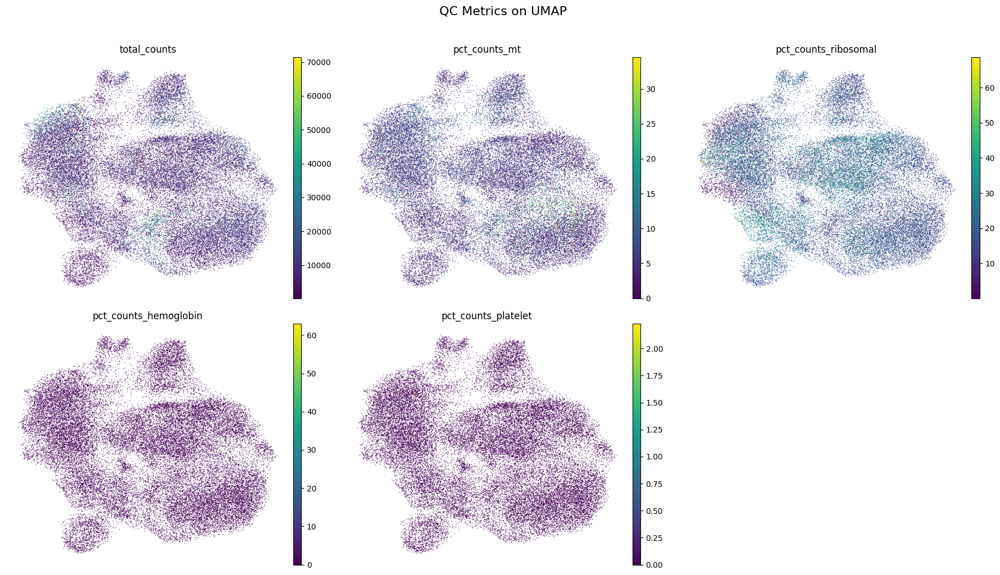

In [62]:
import matplotlib.pyplot as plt
import scanpy as sc

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

variables = ["total_counts", "pct_counts_mt", "pct_counts_ribosomal", 
             "pct_counts_hemoglobin", "pct_counts_platelet"]

for i, var in enumerate(variables):
    sc.pl.umap(
        adata_all,
        color=var,
        ax=axes[i],
        show=False,
        frameon=False,
        title=var
    )

# Rimuovi l'ultimo subplot vuoto
axes[-1].set_visible(False)

plt.suptitle("QC Metrics on UMAP", fontsize=16, y=1.02)
plt.tight_layout()

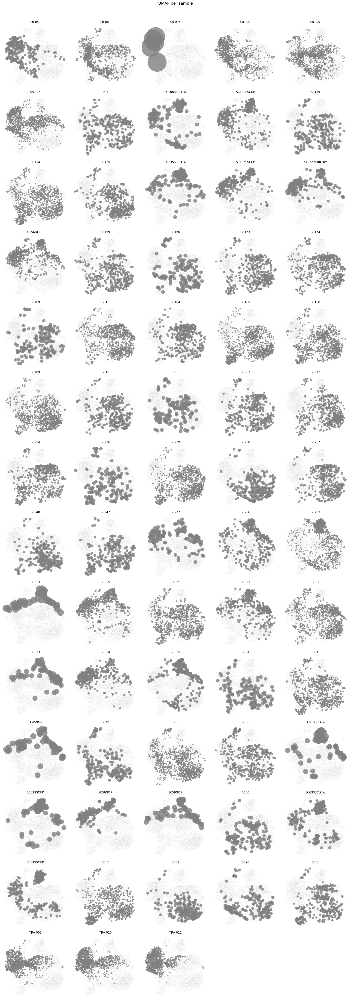

In [63]:
import matplotlib.pyplot as plt
import math

# Rimuovi NaN e converti in stringa
cell_types = sorted(adata_all.obs['sample'].dropna().astype(str).unique())
n = len(cell_types)

# Calcola griglia
ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, batch in enumerate(cell_types):
    adata_batch = adata_all[adata_all.obs['sample'] == batch]
    
    sc.pl.umap(
        adata_all,          # sfondo grigio con tutte le cellule
        color='sample',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        na_color="lightgrey",
        alpha=0.1           # tutte le cellule in grigio trasparente
    )
    # Sovrapponi le cellule del batch in evidenza
    sc.pl.umap(
        adata_batch,
        color='sample',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        alpha=0.8
    )

# Nascondi i subplot vuoti
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("UMAP per sample", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

In [64]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 2000
groupby = "fibroblast_subpopulation"

# Usa indici numerici invece dei nomi dei barcodes
subsampled_idx = []

for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():
    # Converti i nomi in posizioni numeriche
    positions = np.where(adata_all.obs.index.isin(indices))[0]
    n_cells = len(positions)
    
    if n_cells <= min_keep:
        chosen = positions
    else:
        chosen = np.random.choice(positions, size=min_keep, replace=False)
    
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Usa iloc-style indexing con indici numerici
adata_sub = adata_all[np.array(subsampled_idx), :].copy()

print(f"\nTotal cells before: {adata_all.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")

/tmp/ipykernel_1185785/1979956008.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():


F5_Schwann_like_fibroblast → kept 716 / 716 cells
Lung_Alveolar_ADH1B  → kept 2000 / 2645 cells
Mixed                → kept 2000 / 2258 cells
Pan_F2_3_Like_perivascular → kept 2000 / 8195 cells
Pan_Intermediate_PRG4pos → kept 2000 / 4345 cells
Pan_Myofibroblast_COMP_ACTA2 → kept 909 / 909 cells
Pan_Progenitor_like_PB_MFAP5 → kept 2000 / 4807 cells
Skin_F4_Dermal_sheath_FB → kept 2000 / 4350 cells
Skin_Superficial_papillary → kept 2000 / 2623 cells
Synov_Lining         → kept 2000 / 2620 cells

Total cells before: 33468
Total cells after subsampling: 17625


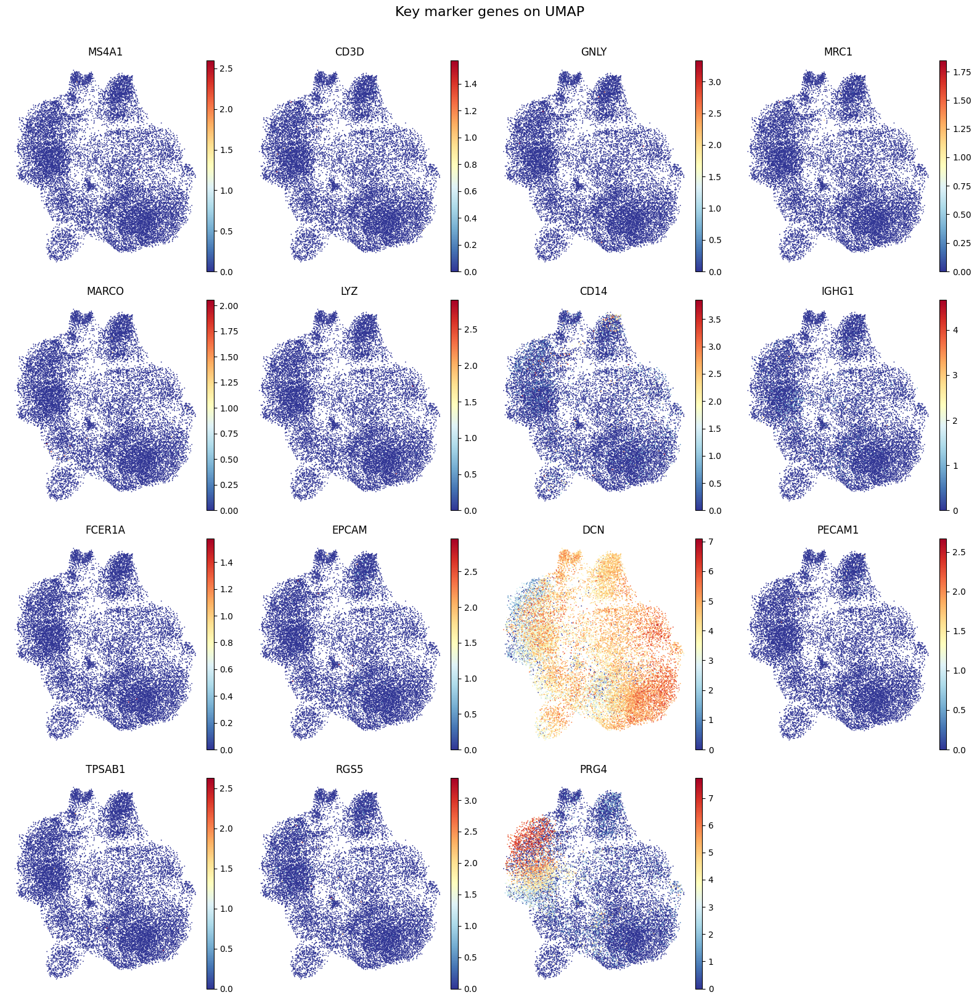

In [65]:
import matplotlib.pyplot as plt
import math

markers = {
    "B cells":       ["MS4A1"],           # CD20 — canonico e universale
    "T cells":       ["CD3D"],            # CD3 — pan-T
    "NK cells":      ["GNLY"],            # granulisina — pan-NK
    "Macrophages":   ["MRC1", "MARCO"],   # CD206 — pan-macrofagi
    "Monocytes":     ["LYZ", "CD14"],     # pan-monociti
    "Plasma cells":  ["IGHG1"],           # immunoglobulina — plasma cells
    "DC":            ["FCER1A"],          # recettore IgE — DC2/pan-DC
    "Epithelial":    ["EPCAM"],           # pan-epiteliale
    "Fibroblasts":   ["DCN"],             # decorina — pan-fibroblasti
    "Endothelial":   ["PECAM1"],          # CD31 — pan-endoteliale
    "Mast cells":    ["TPSAB1"],          # triptasi — pan-mast
    "Pericytes":     ["RGS5"],            # pan-periciti
    "Synovial lining":     ["PRG4"],            # pan-periciti
}

# Flatten tutti i geni
all_markers = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"⚠️ Marker mancanti: {missing}")

# Plot
n = len(all_markers)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, gene in enumerate(all_markers):
    sc.pl.umap(
        adata_sub,
        color=gene,
        ax=axes[i],
        show=False,
        frameon=False,
        title=gene,
        cmap="RdYlBu_r",
        vmin=0,
        vmax=adata_sub[:, gene].X.max() if hasattr(adata_sub[:, gene].X, 'max') else None,
    )

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Key marker genes on UMAP", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

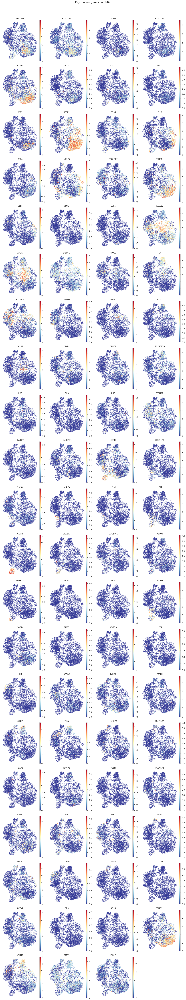

In [86]:
import matplotlib.pyplot as plt
import math

markers = {
    "F1":               ["APCDD1", "COL18A1", "COL23A1", "COL13A1", "COMP",
                         "NKD2", "RSPO1", "AXIN2", "WIF1", "SFRP2"],
    "F2":               ["CD34", "PI16", "DPP4", "MFAP5", "PCOLCE2",
                         "CTHRC1", "SLPI", "CD70", "LGR5"],
    "F2/3":             ["CXCL12", "APOE", "EFEMP1", "APOC1", "C7",
                         "PLA2G2A", "PPARG", "MYOC", "GDF10"],
    "F3":               ["CCL19", "CD74", "CH25H", "TNFSF13B", "IL33",
                         "IRF8", "IL15", "VCAM1", "HLA-DRA", "HLA-DRB1"],
    "F4 (all)":         ["ASPN", "COL11A1"],
    "F4: DS":           ["MEF2C", "DPEP1", "MYL4"],
    "F4: TNN+COCH+":    ["TNN", "COCH", "CRABP1", "COL24A1", "RSPO4",
                         "SLITRK6", "NRG3", "MKX", "TNMD"],
    "F4: DP_HHIP+":     ["CORIN", "BMP7", "WNT5A", "LEF1", "HHIP",
                         "RSPO3", "INHBA", "PTCH1"],
    "F5 (all)":         ["SCN7A", "FMO2", "FGFBP2", "OLFML2A", "PEAR1"],
    "F5: RAMP1+":       ["RAMP1", "RELN", "PLEKHA6", "IGFBP2", "SFRP1"],
    "F5: NGFR+":        ["EBF2", "NGFR", "SFRP4", "ITGA6", "CDH19", "CLDN1"],
    "ADDITIONAL":        ["ACTA2", "DES", "RGS5", "CTHRC1","ADH1B", "STAT3","ISG15"],
}

# Flatten tutti i geni
all_markers = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"⚠️ Marker mancanti: {missing}")

# Plot
n = len(all_markers)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, gene in enumerate(all_markers):
    sc.pl.umap(
        adata_sub,
        color=gene,
        ax=axes[i],
        show=False,
        frameon=False,
        title=gene,
        cmap="RdYlBu_r",
        vmin=0,
        vmax=adata_sub[:, gene].X.max() if hasattr(adata_sub[:, gene].X, 'max') else None,
    )

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Key marker genes on UMAP", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

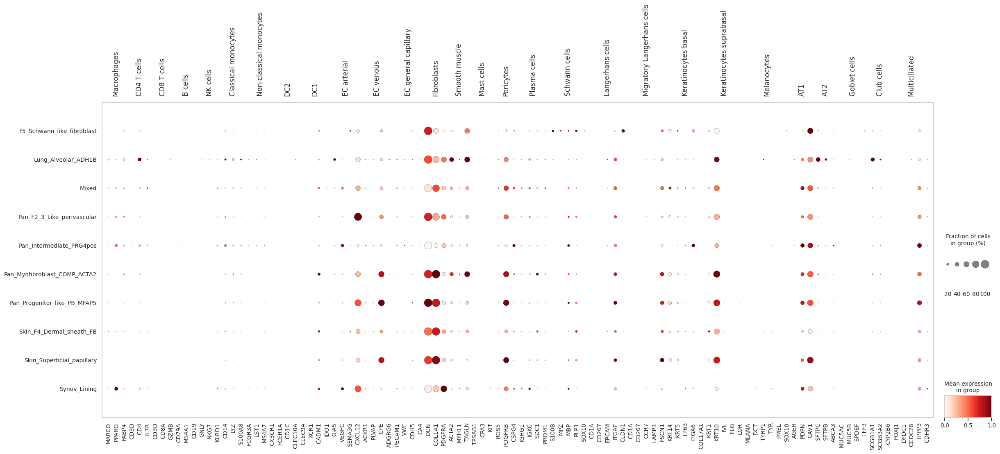

In [87]:
markers = {
    "Macrophages":     ["MARCO", "PPARG", "FABP4"],
    "CD4 T cells":              ["CD3D", "CD4", "IL7R"],
    "CD8 T cells":              ["CD3D", "CD8A", "GZMB"],
    "B cells":                  ["CD79A", "MS4A1", "CD19"],
    "NK cells":                 ["GNLY", "NKG7", "KLRD1"],
    "Classical monocytes":      ["CD14", "LYZ", "S100A8"],
    "Non-classical monocytes":  ["FCGR3A", "LST1", "MS4A7", "CX3CR1"],
    "DC2":                      ["FCER1A", "CD1C", "CLEC10A"],
    "DC1":                      ["CLEC9A", "XCR1", "CADM1", "IDO1"],
    "EC arterial":              ["GJA5", "VEGFC", "SEMA3G", "CXCL12"],   # ← aggiunto
    "EC venous":                ["ACKR1", "PLVAP", "CPE", "ADGRG6"],     # ← aggiunto
    "EC general capillary":     ["PECAM1", "VWF", "CDH5", "CA4"],        # ← aggiunto CA4
    "Fibroblasts":              ["DCN", "COL1A1", "PDGFRA"],
    "Smooth muscle":            ["ACTA2", "MYH11", "TAGLN"],
    "Mast cells":               ["TPSAB1", "CPA3", "KIT"],
    "Pericytes":                ["RGS5", "PDGFRB", "CSPG4"],
    "Plasma cells":             ["IGHG1", "IGKC", "SDC1", "PRDM1"],
    "Schwann cells":            ["S100B", "MPZ", "MBP", "PLP1", "SOX10"],
    "Langerhans cells":         ["CD1A", "CD207", "EPCAM", "ITGAE", "CLDN1"],
    "Migratory Langerhans cells": ["CD1A", "CD207", "CCR7", "LAMP3", "FSCN1"],
    "Keratinocytes basal":      ["KRT14", "KRT5", "TP63", "ITGA6", "COL17A1"],
    "Keratinocytes suprabasal": ["KRT1", "KRT10", "IVL", "FLG", "LOR"],
    "Melanocytes":              ["MLANA", "DCT", "TYRP1", "TYR", "PMEL", "SOX10"],
    "AT1":                      ["AGER", "PDPN", "CAV1"],
    "AT2":                      ["SFTPC", "SFTPB", "ABCA3"],
    "Goblet cells":             ["MUC5AC", "MUC5B", "SPDEF", "TFF3"],
    "Club cells":               ["SCGB1A1", "SCGB3A2", "CYP2B6"],
    "Multiciliated":            ["FOXJ1", "DYDC1", "CCDC78", "TPPP3", "CDHR3"],
}

# Filtra i marker presenti nel dataset
all_markers_flat = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

# Verifica quali marker mancano
missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

sc.pl.dotplot(
    adata_sub,
    var_names=markers,
    groupby="fibroblast_subpopulation",
    standard_scale="var",
    figsize=(28, 10),
)

In [88]:
marker_genes_dict = {'SF1': ['PRG4'],
                     'SF2': 'CHI3L2',
                     'SF3': ['APOE'],
                     'SF4': ['POSTN'],
                     'SF5': ['FKBP5'],
                     'SF6': ['FOSB'],
                     'SF7': ['CXCL14'],
                     'SF8': ['MFAP5']}

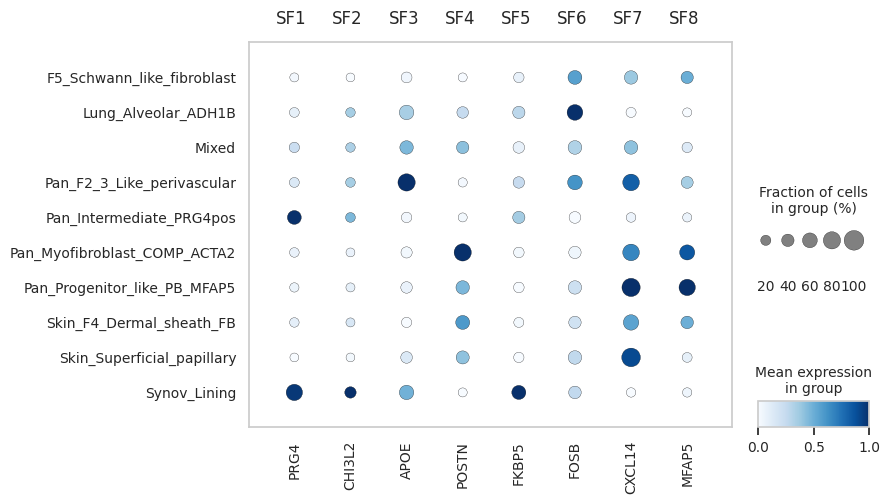

In [89]:
ax = sc.pl.dotplot(adata_all, marker_genes_dict, groupby='fibroblast_subpopulation', dendrogram=False,
                   standard_scale='var', smallest_dot=40, color_map='Blues', figsize=(8,5))

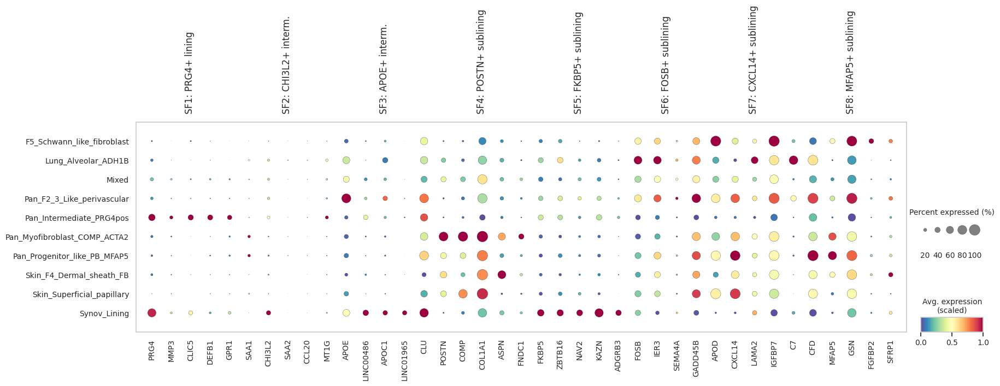

In [90]:
import scanpy as sc
import matplotlib.pyplot as plt

# Marker dei fibroblasti sinoviali (trascritti dall'immagine)
sf_markers = {
    "SF1: PRG4+ lining":        ["PRG4", "MMP3", "CLIC5", "DEFB1", "GPR1"],
    "SF2: CHI3L2+ interm.":     ["SAA1", "CHI3L2", "SAA2", "CCL20", "MT1G"],
    "SF3: APOE+ interm.":       ["APOE", "LINC00486", "APOC1", "LINC01965", "CLU"],
    "SF4: POSTN+ sublining":    ["POSTN", "COMP", "COL1A1", "ASPN", "FNDC1"],
    "SF5: FKBP5+ sublining":    ["FKBP5", "ZBTB16", "NAV2", "KAZN", "ADGRB3"],
    "SF6: FOSB+ sublining":     ["FOSB", "IER3", "SEMA4A", "GADD45B"],
    "SF7: CXCL14+ sublining":   ["APOD", "CXCL14", "LAMA2", "IGFBP7", "C7"],
    "SF8: MFAP5+ sublining":    ["CFD", "MFAP5", "GSN", "FGFBP2", "SFRP1"],
}

# Tieni solo i geni presenti nel dataset e scarta i gruppi vuoti
present = set(adata_sub.var_names)
missing = [g for gs in sf_markers.values() for g in gs if g not in present]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

sf_markers = {k: [g for g in v if g in present] for k, v in sf_markers.items()}
sf_markers = {k: v for k, v in sf_markers.items() if v}

sc.pl.dotplot(
    adata_sub,
    var_names=sf_markers,
    groupby="fibroblast_subpopulation",
    standard_scale="var",
    cmap="Spectral_r",             # palette simile a quella dell'immagine
    var_group_rotation=90,         # etichette dei gruppi lunghe: ruotale
    colorbar_title="Avg. expression\n(scaled)",
    size_title="Percent expressed (%)",
    figsize=(20, 5),
    show=True,
)

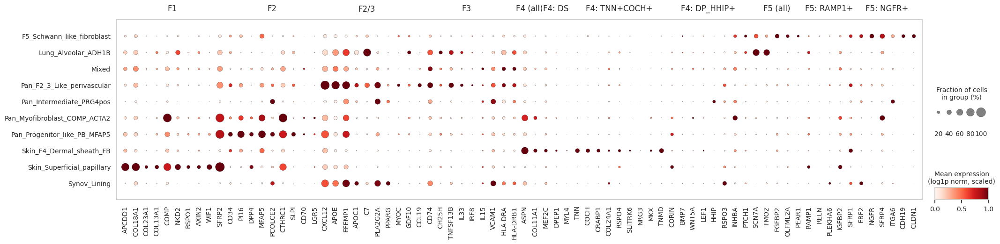

In [91]:
import scanpy as sc

# Marker di riferimento dei sottotipi di fibroblasti (trascritti dall'immagine)
fib_markers = {
    "F1":               ["APCDD1", "COL18A1", "COL23A1", "COL13A1", "COMP",
                         "NKD2", "RSPO1", "AXIN2", "WIF1", "SFRP2"],
    "F2":               ["CD34", "PI16", "DPP4", "MFAP5", "PCOLCE2",
                         "CTHRC1", "SLPI", "CD70", "LGR5"],
    "F2/3":             ["CXCL12", "APOE", "EFEMP1", "APOC1", "C7",
                         "PLA2G2A", "PPARG", "MYOC", "GDF10"],
    "F3":               ["CCL19", "CD74", "CH25H", "TNFSF13B", "IL33",
                         "IRF8", "IL15", "VCAM1", "HLA-DRA", "HLA-DRB1"],
    "F4 (all)":         ["ASPN", "COL11A1"],
    "F4: DS":           ["MEF2C", "DPEP1", "MYL4"],
    "F4: TNN+COCH+":    ["TNN", "COCH", "CRABP1", "COL24A1", "RSPO4",
                         "SLITRK6", "NRG3", "MKX", "TNMD"],
    "F4: DP_HHIP+":     ["CORIN", "BMP7", "WNT5A", "LEF1", "HHIP",
                         "RSPO3", "INHBA", "PTCH1"],
    "F5 (all)":         ["SCN7A", "FMO2", "FGFBP2", "OLFML2A", "PEAR1"],
    "F5: RAMP1+":       ["RAMP1", "RELN", "PLEKHA6", "IGFBP2", "SFRP1"],
    "F5: NGFR+":        ["EBF2", "NGFR", "SFRP4", "ITGA6", "CDH19", "CLDN1"],
}

# Tieni solo i geni presenti nel dataset, mantenendo l'ordine e scartando i gruppi vuoti
present = set(adata_sub.var_names)
missing = [g for gs in fib_markers.values() for g in gs if g not in present]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

fib_markers = {k: [g for g in v if g in present] for k, v in fib_markers.items()}
fib_markers = {k: v for k, v in fib_markers.items() if v}

sc.pl.dotplot(
    adata_sub,
    var_names=fib_markers,
    groupby="fibroblast_subpopulation",
    standard_scale="var",          # 0-1 per gene, come nella scala dell'immagine
    cmap="Reds",
    dot_max=1.0,                   # oppure lascia None
    var_group_rotation=0,
    colorbar_title="Mean expression\n(log1p norm, scaled)",
    size_title="Fraction of cells\nin group (%)",
    figsize=(24, 5),
    show=True,
)

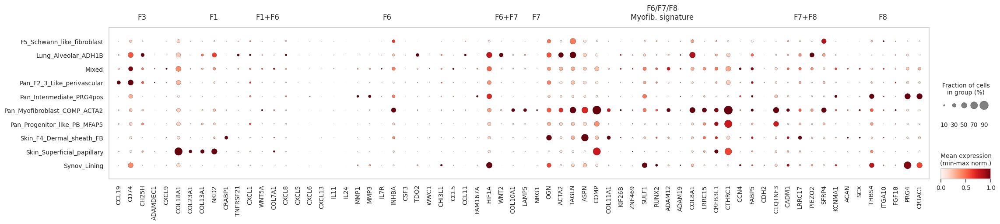

In [92]:
import scanpy as sc
import matplotlib.pyplot as plt

# Marker trascritti dall'immagine (pannello c)
myo_markers = {
    "F3":                          ["CCL19", "CD74", "CH25H", "ADAMDEC1", "CXCL9"],
    "F1":                          ["COL18A1", "COL23A1", "COL13A1", "NKD2",
                                    "CRABP1", "TNFRSF21", "CXCL1"],
    "F1+F6":                       ["WNT5A", "COL7A1"],
    "F6":                          ["CXCL8", "CXCL5", "CXCL6", "CXCL13", "IL11",
                                    "IL24", "MMP1", "MMP3", "IL7R", "INHBA",
                                    "CSF3", "TDO2", "WWC1", "CHI3L1", "CCL5",
                                    "CCL11", "FAM167A", "HIF1A"],
    "F6+F7":                       ["WNT2", "COL10A1"],
    "F7":                          ["LAMP5", "NRG1", "OGN"],
    "F6/F7/F8\nMyofib. signature": ["ACTA2", "TAGLN", "ASPN", "COMP", "COL11A1",
                                    "KIF26B", "ZNF469", "SULF1", "RUNX2",
                                    "ADAM12", "ADAM19", "COL8A1", "LRRC15",
                                    "CREB3L1", "CTHRC1", "CCN4", "FABP5", "CDH2"],
    "F7+F8":                       ["C1QTNF3", "CADM1", "LRRC17", "PIEZO2",
                                    "SFRP4", "KCNMA1"],
    "F8":                          ["ACAN", "SCX", "THBS4", "ITGA10", "FGF18",
                                    "PRG4", "CRTAC1"],
}

# Tieni solo i geni presenti e scarta i gruppi vuoti
present = set(adata_sub.var_names)
missing = [g for gs in myo_markers.values() for g in gs if g not in present]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

myo_markers = {k: [g for g in v if g in present] for k, v in myo_markers.items()}
myo_markers = {k: v for k, v in myo_markers.items() if v}

sc.pl.dotplot(
    adata_sub,
    var_names=myo_markers,
    groupby="fibroblast_subpopulation",
    standard_scale="var",              # min-max per gene, come nell'immagine
    cmap="Reds",
    var_group_rotation=0,
    colorbar_title="Mean expression\n(min-max norm.)",
    size_title="Fraction of cells\nin group (%)",
    figsize=(26, 4.5),
    show=True,
)

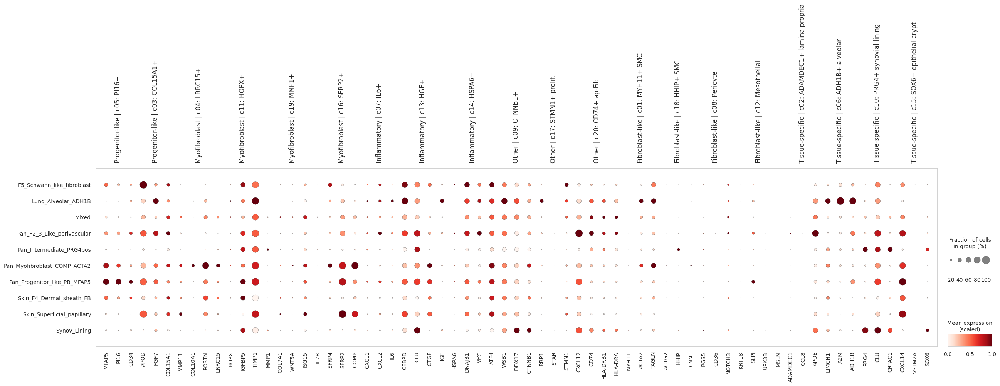

In [93]:
import scanpy as sc
import matplotlib.pyplot as plt

# Marker per cluster, con macro-categoria inclusa nel nome del gruppo
fib_clusters = {
    # Progenitor-like fibroblasts
    "Progenitor-like | c05: PI16+":            ["MFAP5", "PI16", "CD34"],
    "Progenitor-like | c03: COL15A1+":         ["APOD", "FGF7", "COL15A1"],

    # Myofibroblasts
    "Myofibroblast | c04: LRRC15+":            ["MMP11", "COL10A1", "POSTN", "LRRC15"],
    "Myofibroblast | c11: HOPX+":              ["HOPX", "IGFBP5", "TIMP1"],
    "Myofibroblast | c19: MMP1+":              ["MMP1", "COL7A1", "WNT5A", "ISG15", "IL7R"],
    "Myofibroblast | c16: SFRP2+":             ["SFRP4", "SFRP2", "COMP"],

    # Inflammatory fibroblasts
    "Inflammatory | c07: IL6+":                ["CXCL1", "CXCL2", "IL6"],
    "Inflammatory | c13: HGF+":                ["CEBPD", "CLU", "CTGF", "HGF"],
    "Inflammatory | c14: HSPA6+":              ["HSPA6", "DNAJB1", "MYC", "ATF4"],

    # Other fibroblasts
    "Other | c09: CTNNB1+":                    ["WSB1", "DDX17", "CTNNB1"],
    "Other | c17: STMN1+ prolif.":             ["RBP1", "STAR", "STMN1"],
    "Other | c20: CD74+ ap-Fib":               ["CXCL12", "CD74", "HLA-DRB1", "HLA-DRA"],

    # Fibroblast-like cells
    "Fibroblast-like | c01: MYH11+ SMC":       ["MYH11", "ACTA2", "TAGLN"],
    "Fibroblast-like | c18: HHIP+ SMC":        ["ACTG2", "HHIP", "CNN1"],
    "Fibroblast-like | c08: Pericyte":         ["RGS5", "CD36", "NOTCH3"],
    "Fibroblast-like | c12: Mesothelial":      ["KRT18", "SLPI", "UPK3B", "MSLN"],

    # Tissue-specific fibroblasts
    "Tissue-specific | c02: ADAMDEC1+ lamina propria": ["ADAMDEC1", "CCL8", "APOE"],
    "Tissue-specific | c06: ADH1B+ alveolar":          ["LIMCH1", "A2M", "ADH1B"],
    "Tissue-specific | c10: PRG4+ synovial lining":    ["PRG4", "CLU", "CRTAC1"],
    "Tissue-specific | c15: SOX6+ epithelial crypt":   ["CXCL14", "VSTM2A", "SOX6"],
}

# Tieni solo i geni presenti e scarta i gruppi vuoti
present = set(adata_sub.var_names)
missing = [g for gs in fib_clusters.values() for g in gs if g not in present]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

fib_clusters = {k: [g for g in v if g in present] for k, v in fib_clusters.items()}
fib_clusters = {k: v for k, v in fib_clusters.items() if v}

sc.pl.dotplot(
    adata_sub,
    var_names=fib_clusters,
    groupby="fibroblast_subpopulation",
    standard_scale="var",
    cmap="Reds",
    var_group_rotation=90,
    colorbar_title="Mean expression\n(scaled)",
    size_title="Fraction of cells\nin group (%)",
    figsize=(30, 6),
    show=True,
)

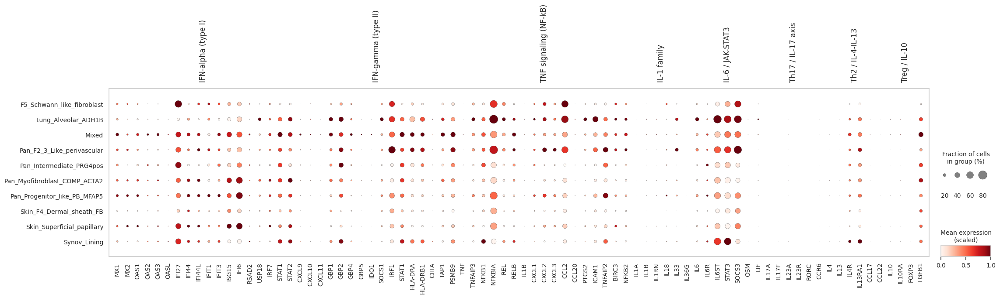

In [94]:
signatures = {
    "IFN-alpha (type I)": [
        "MX1", "MX2", "OAS1", "OAS2", "OAS3", "OASL", "IFI27", "IFI44",
        "IFI44L", "IFIT1", "IFIT3", "ISG15", "IFI6", "RSAD2", "USP18",
        "IRF7", "STAT1", "STAT2",
    ],
    "IFN-gamma (type II)": [
        "CXCL9", "CXCL10", "CXCL11", "GBP1", "GBP2", "GBP4", "GBP5",
        "IDO1", "SOCS1", "IRF1", "STAT1", "HLA-DRA", "HLA-DRB1",
        "CIITA", "TAP1", "PSMB9",
    ],
    "TNF signaling (NF-kB)": [
        "TNF", "TNFAIP3", "NFKB1", "NFKBIA", "REL", "RELB", "IL1B",
        "CXCL1", "CXCL2", "CXCL3", "CCL2", "CCL20", "PTGS2", "ICAM1",
        "TNFAIP2", "BIRC3", "NFKB2",
    ],
    "IL-1 family":          ["IL1A", "IL1B", "IL1RN", "IL18", "IL33", "IL36G"],
    "IL-6 / JAK-STAT3":     ["IL6", "IL6R", "IL6ST", "STAT3", "SOCS3", "OSM", "LIF"],
    "Th17 / IL-17 axis":    ["IL17A", "IL17F", "IL23A", "IL23R", "RORC", "CCR6"],
    "Th2 / IL-4-IL-13":     ["IL4", "IL13", "IL4R", "IL13RA1", "CCL17", "CCL22"],
    "Treg / IL-10":         ["IL10", "IL10RA", "FOXP3", "TGFB1"],
}

# Filtra i geni presenti
present = set(adata_sub.var_names)
missing = {k: [g for g in v if g not in present] for k, v in signatures.items()}
missing = {k: v for k, v in missing.items() if v}
if missing:
    print("Marker non trovati:", missing)

signatures = {k: [g for g in v if g in present] for k, v in signatures.items()}

sc.pl.dotplot(
    adata_sub,
    var_names=signatures,
    groupby="fibroblast_subpopulation",   # o il tuo cluster di interesse
    standard_scale="var",
    cmap="Reds",
    var_group_rotation=90,
    figsize=(26, 5),
    colorbar_title="Mean expression\n(scaled)",
    size_title="Fraction of cells\nin group (%)",
)

In [95]:
%matplotlib inline

In [96]:
IFN_ALPHA_genes = [
  "ADAR","B2M","BATF2","BST2","C1S","CASP1","CASP8","CCRL2","CD47","CD74",
  "CMPK2","CMTR1","CNP","CSF1","CXCL10","CXCL11","DDX60","DHX58","EIF2AK2",
  "ELF1","EPSTI1","GBP2","GBP4","GMPR","HELZ2","HERC6","HLA-C","IFI27","IFI30",
  "IFI35","IFI44","IFI44L","IFIH1","IFIT2","IFIT3","IFITM1","IFITM2","IFITM3",
  "IL15","IL4R","IL7R","IRF1","IRF2","IRF7","IRF9","ISG15","ISG20","LAMP3",
  "LAP3","LGALS3BP","LPAR6","LY6E","MOV10","MVB12A","MX1","NCOA7","NMI","NUB1",
  "OAS1","OASL","OGFR","PARP12","PARP14","PARP9","PLSCR1","PNPT1","PROCR","PSMA3",
  "PSMB8","PSMB9","PSME1","PSME2","RIPK2","RNF31","RSAD2","RTP4","SAMD9","SAMD9L",
  "SELL","SLC25A28","SP110","STAT2","TAP1","TDRD7","TENT5A","TMEM140","TRAFD1",
  "TRIM14","TRIM21","TRIM25","TRIM26","TRIM5","TXNIP","UBA7","UBE2L6","USP18","WARS1"
]

IFN_GAMMA_genes = ["ADAR","APOL6","ARID5B","ARL4A","AUTS2","B2M","BANK1","BATF2","BPGM","BST2",
    "BTG1","C1R","C1S","CASP1","CASP3","CASP4","CASP7","CASP8","CCL2","CCL5","CCL7",
    "CD274","CD38","CD40","CD69","CD74","CD86","CDKN1A","CFB","CFH","CIITA","CMKLR1",
    "CMPK2","CSF2RB","CXCL10","CXCL11","CXCL9","RIGI","DDX60","DHX58","EIF2AK2","EIF4E3",
    "EPSTI1","FAS","FCGR1A","FGL2","FPR1","CMTR1","GBP4","GBP6","GCH1","GPR18","GZMA",
    "HERC6","HIF1A","HLA-A","HLA-B","HLA-DMA","HLA-DQA1","HLA-DRB1","HLA-G","ICAM1",
    "IDO1","IFI27","IFI30","IFI35","IFI44","IFI44L","IFIH1","IFIT1","IFIT2","IFIT3",
    "IFITM2","IFITM3","IFNAR2","IL10RA","IL15","IL15RA","IL18BP","IL2RB","IL4R","IL6",
    "IL7","IRF1","IRF2","IRF4","IRF5","IRF7","IRF8","IRF9","ISG15","ISG20","ISOC1",
    "ITGB7","JAK2","KLRK1","LAP3","LATS2","LCP2","LGALS3BP","LY6E","LYSMD2","MARCHF1",
    "TMT1B","MT2A","MTHFD2","MVP","MX1","MX2","MYD88","NAMPT","NCOA3","NFKB1","NFKBIA",
    "NLRC5","NMI","NOD1","NUP93","OAS2","OAS3","OASL","OGFR","P2RY14","PARP12","PARP14",
    "PDE4B","PELI1","PFKP","PIM1","PLA2G4A","PLSCR1","PML","PNP","PNPT1","HELZ2",
    "PSMA2","PSMA3","PSMB10","PSMB2","PSMB8","PSMB9","PSME1","PSME2","PTGS2","PTPN1",
    "PTPN2","PTPN6","RAPGEF6","RBCK1","RIPK1","RIPK2","RNF213","RNF31","RSAD2","RTP4",
    "SAMD9L","SAMHD1","SECTM1","SELP","SERPING1","SLAMF7","SLC25A28","SOCS1","SOCS3",
    "SOD2","SP110","SPPL2A","SRI","SSPN","ST3GAL5","ST8SIA4","STAT1","STAT2","STAT3",
    "STAT4","TAP1","TAPBP","TDRD7","TNFAIP2","TNFAIP3","TNFAIP6","TNFSF10","TOR1B",
    "TRAFD1","TRIM14","TRIM21","TRIM25","TRIM26","TXNIP","UBE2L6","UPP1","USP18","VAMP5",
    "VAMP8","VCAM1","WARS1","XAF1","XCL1","ZBP1","ZNFX1"
]

COMP_CLASS_genes = [
    "C1QA","C1QB","C1QBP","C1QC","C1R","C1RL","C1S","C2","C4A","C4B","SERPING1","C4BPA","C4BPB","CSMD1"
]

COMP_ALT_genes = [
    "CFB","CFD","CFP","CFH","C3"
]

COMP_ALL_genes = [
    "C3","C5","C6","C7","C8A","C8B","C9","CFI","CR1","CD46","CD55","CD59","VTN","CLU","SVEP1","SUSD4","THBD"
]

sc.tl.score_genes(adata_all, gene_list=IFN_ALPHA_genes, score_name="IFN_ALPHA_genes")
sc.tl.score_genes(adata_all, gene_list=IFN_GAMMA_genes, score_name="IFN_GAMMA_genes")
sc.tl.score_genes(adata_all, gene_list=COMP_CLASS_genes, score_name="COMP_CLASS_genes")
sc.tl.score_genes(adata_all, gene_list=COMP_ALT_genes, score_name="COMP_ALT_genes")
sc.tl.score_genes(adata_all, gene_list=COMP_ALL_genes, score_name="COMP_ALL_genes")


Plotting IFN_ALPHA_genes ...


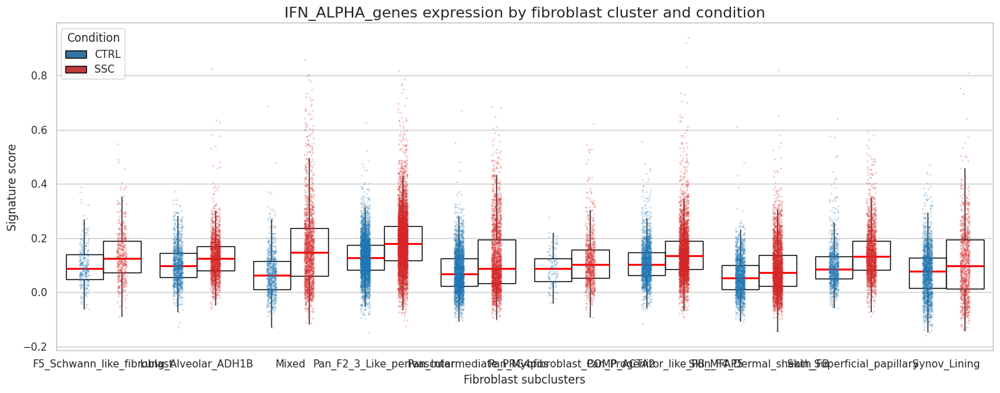

Plotting IFN_GAMMA_genes ...


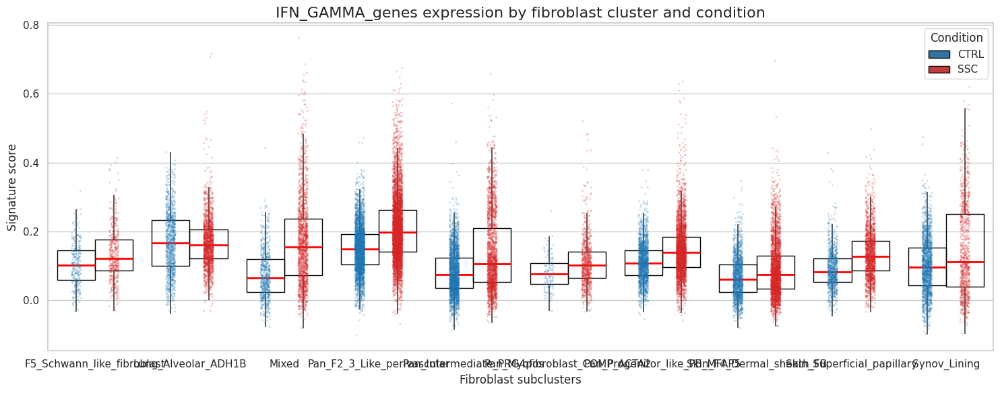

Plotting COMP_CLASS_genes ...


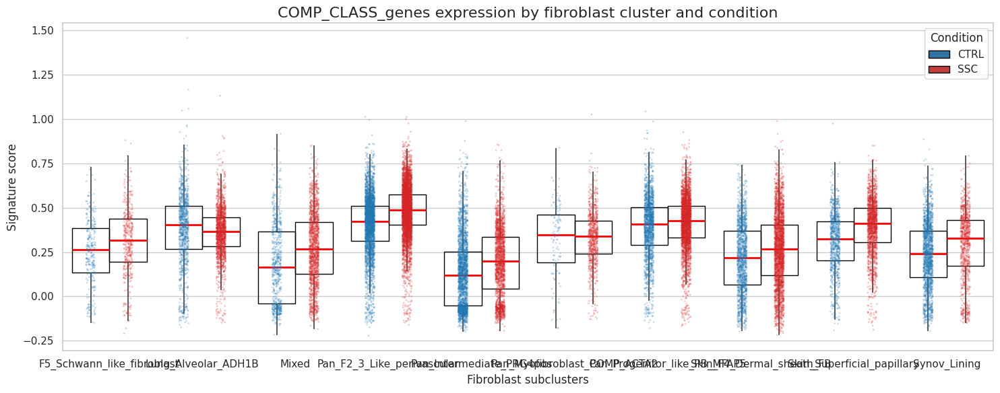

Plotting COMP_ALT_genes ...


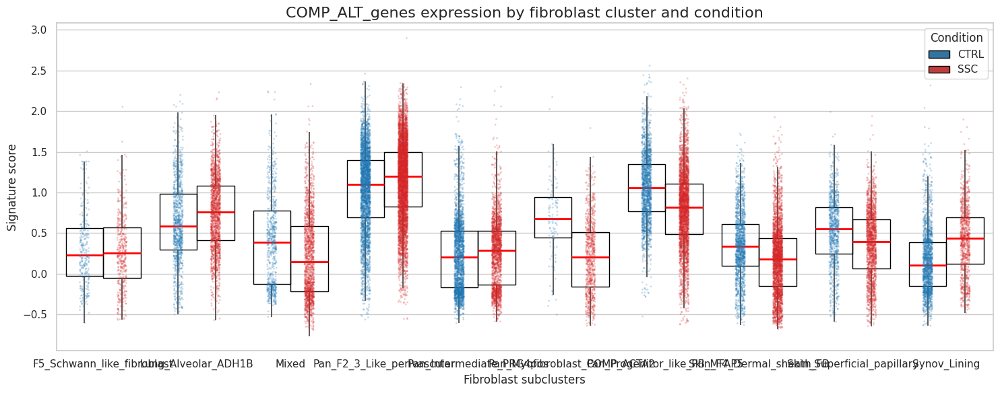

Plotting COMP_ALL_genes ...


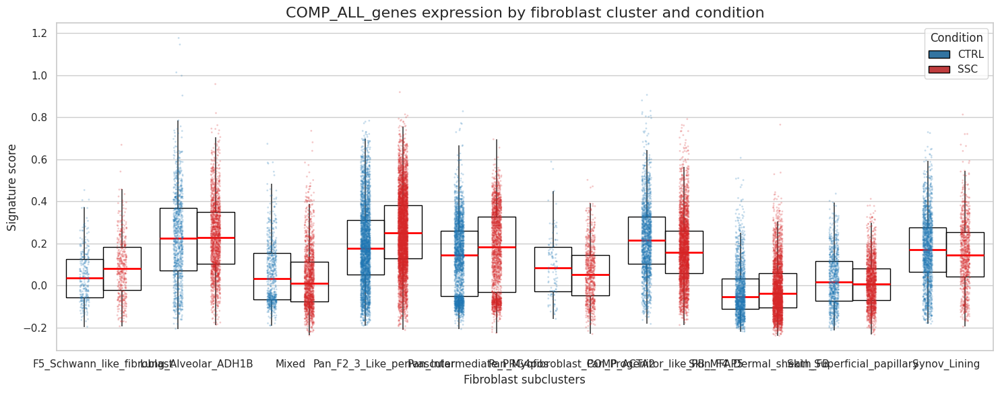

In [97]:
import seaborn as sns
import matplotlib.pyplot as plt

scores = [
    'IFN_ALPHA_genes',
    'IFN_GAMMA_genes',
    'COMP_CLASS_genes',
    'COMP_ALT_genes',
    'COMP_ALL_genes'
]

# Custom colors for the conditions
cond_palette = {
    "CTRL": "#1f77b4",   # blue
    "SSC":  "#d62728"    # red
}

# Ensure categories
adata_all.obs["fibroblast_subpopulation"] = adata_all.obs["fibroblast_subpopulation"].astype("category")
adata_all.obs["Condition"] = adata_all.obs["Condition"].astype("category")

for score in scores:
    print(f"Plotting {score} ...")

    df = adata_all.obs[[score, "Condition", "fibroblast_subpopulation"]].copy()

    # Drop rows where score is missing
    df = df.dropna(subset=[score])

    plt.figure(figsize=(15, 6))

    # --- BEAUTIFUL BOXPLOT WITH CUSTOM COLORS ---
    ax = sns.boxplot(
        data=df,
        x="fibroblast_subpopulation",
        y=score,
        hue='Condition',
        palette=cond_palette,
        showcaps=False,
        boxprops={'facecolor':'None', 'edgecolor':'black'},
        whiskerprops={'linewidth':1.2},
        medianprops={'color':'red', 'linewidth':2},
        showfliers=False
    )

    # --- DOTS WITH SAME COLORS ---
    sns.stripplot(
        data=df,
        x="fibroblast_subpopulation",
        y=score,
        hue='Condition',
        palette=cond_palette,
        dodge=True,
        jitter=True,
        alpha=0.25,
        size=2,
        linewidth=0
    )

    # Remove double legends (boxplot + stripplot)
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles[:2], labels[:2], title="Condition")

    plt.title(f"{score} expression by fibroblast cluster and condition", fontsize=16)
    plt.xlabel("Fibroblast subclusters", fontsize=12)
    plt.ylabel("Signature score", fontsize=12)

    plt.tight_layout()
    plt.show()


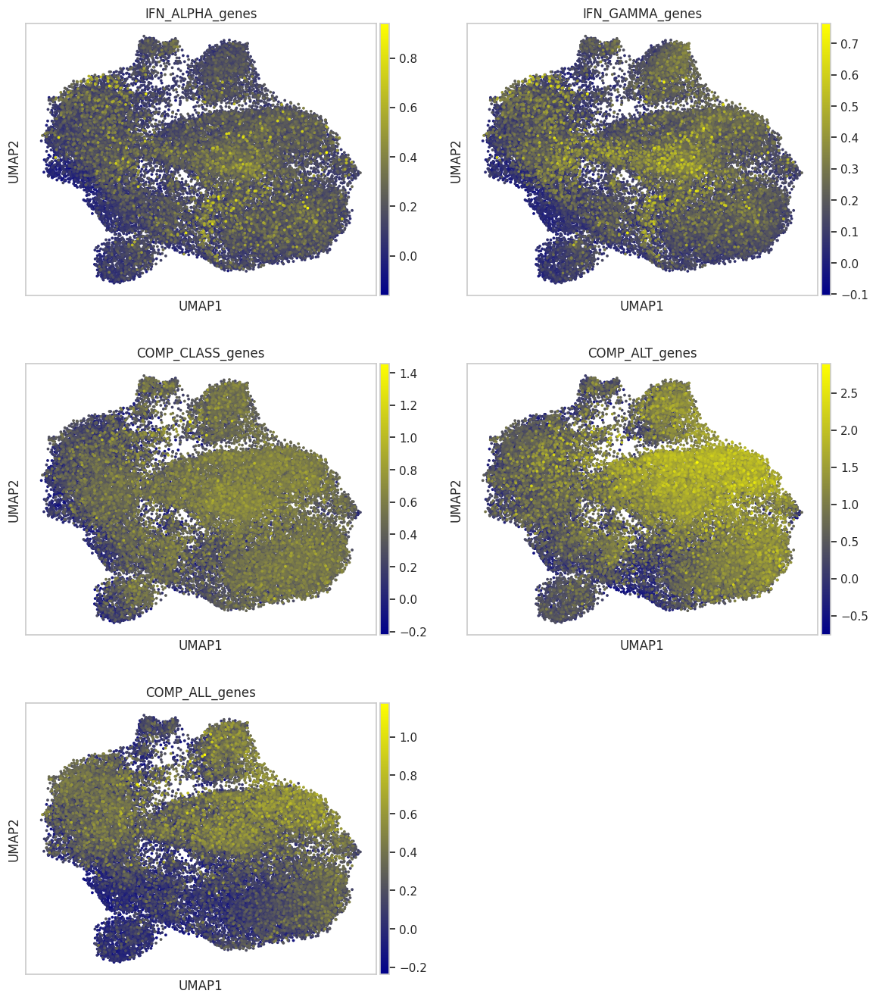

In [98]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Define a green-to-dark-red colormap
green_red = LinearSegmentedColormap.from_list("yellow_red", ["darkblue", "yellow"])

# List of scores to plot
scores = [
    "IFN_ALPHA_genes",
    "IFN_GAMMA_genes",
    "COMP_CLASS_genes",
    "COMP_ALT_genes",
    "COMP_ALL_genes"
]

# Plot UMAP for all scores
sc.pl.umap(
    adata_all,
    color=scores,
    ncols=2,          # number of columns in the plot grid
    size=30,          # adjust dot size
    cmap=green_red,   # custom green-to-dark-red gradient
    show=True
)


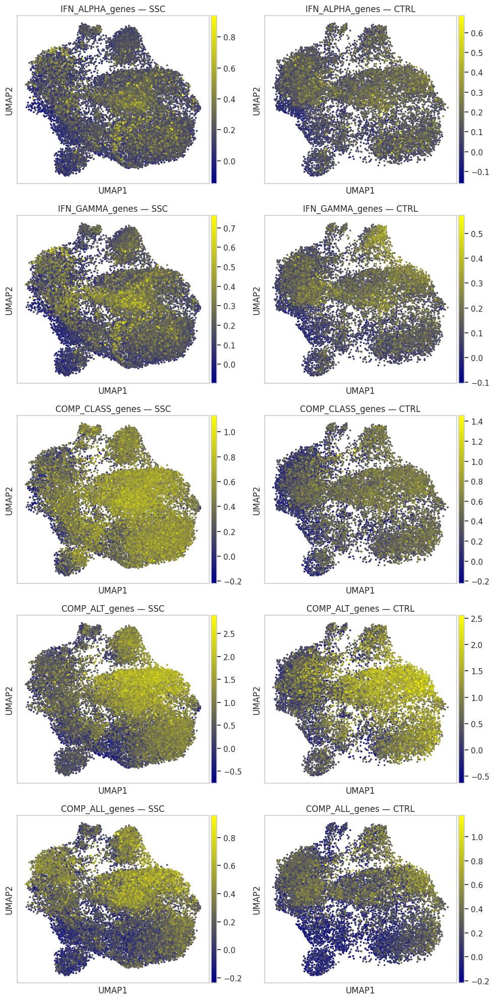

In [99]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Define a green-to-dark-red colormap
green_red = LinearSegmentedColormap.from_list("yellow_red", ["darkblue", "yellow"])

scores = [
    "IFN_ALPHA_genes",
    "IFN_GAMMA_genes",
    "COMP_CLASS_genes",
    "COMP_ALT_genes",
    "COMP_ALL_genes"
]

conditions = adata_all.obs["Condition"].unique().tolist()  # es. ['SSC', 'CTRL']

# Griglia: righe = score, colonne = condizioni
fig, axes = plt.subplots(
    nrows=len(scores), ncols=len(conditions),
    figsize=(5 * len(conditions), 4 * len(scores))
)

for i, score in enumerate(scores):
    for j, cond in enumerate(conditions):
        ax = axes[i, j] if len(scores) > 1 else axes[j]
        subset = adata_all[adata_all.obs["Condition"] == cond]
        sc.pl.umap(
            subset,
            color=score,
            size=30,
            cmap=green_red,
            ax=ax,
            show=False,
            title=f"{score} — {cond}"
        )

plt.tight_layout()
plt.show()

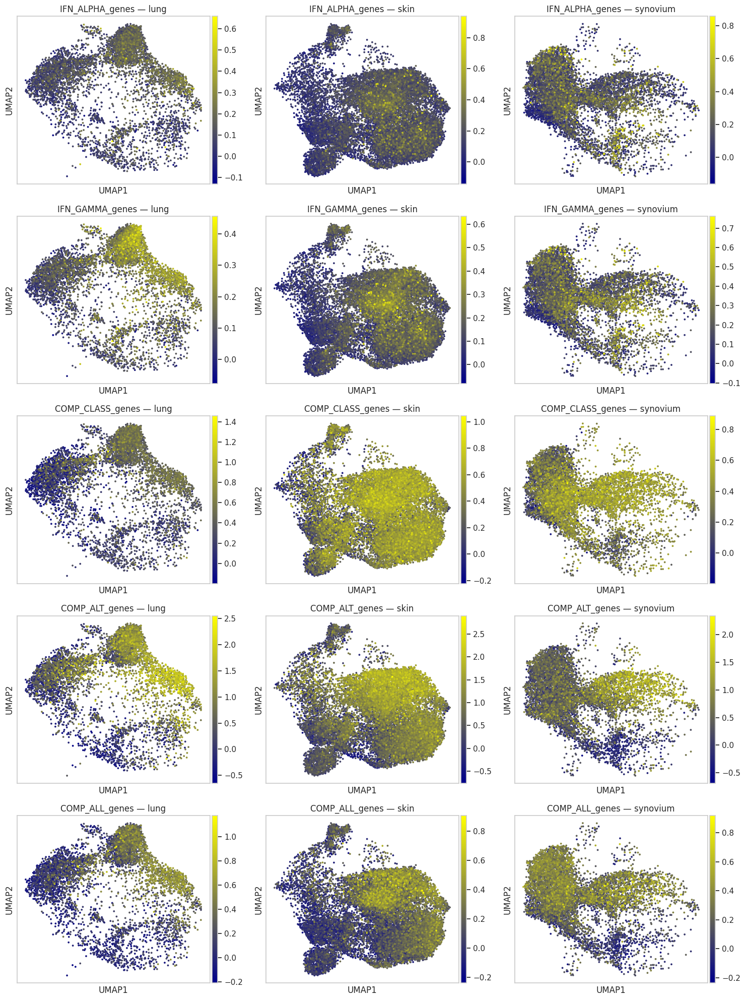

In [100]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Define a green-to-dark-red colormap
green_red = LinearSegmentedColormap.from_list("yellow_red", ["darkblue", "yellow"])

scores = [
    "IFN_ALPHA_genes",
    "IFN_GAMMA_genes",
    "COMP_CLASS_genes",
    "COMP_ALT_genes",
    "COMP_ALL_genes"
]

conditions = adata_all.obs["tissue"].unique().tolist()  # es. ['SSC', 'CTRL']

# Griglia: righe = score, colonne = condizioni
fig, axes = plt.subplots(
    nrows=len(scores), ncols=len(conditions),
    figsize=(5 * len(conditions), 4 * len(scores))
)

for i, score in enumerate(scores):
    for j, cond in enumerate(conditions):
        ax = axes[i, j] if len(scores) > 1 else axes[j]
        subset = adata_all[adata_all.obs["tissue"] == cond]
        sc.pl.umap(
            subset,
            color=score,
            size=30,
            cmap=green_red,
            ax=ax,
            show=False,
            title=f"{score} — {cond}"
        )

plt.tight_layout()
plt.show()

In [101]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

scores = [
    'IFN_ALPHA_genes',
    'IFN_GAMMA_genes',
    'COMP_CLASS_genes',
    'COMP_ALT_genes',
    'COMP_ALL_genes'
]

adata_all.obs["fibroblast_subpopulation"] = adata_all.obs["fibroblast_subpopulation"].astype("category")

all_results = {}   # store results for each score

for score in scores:
    print(f"\n🔎 Running statistics for: {score}")

    df = adata_all.obs[[score, "Condition", "fibroblast_subpopulation"]].copy()
    df = df.dropna(subset=[score])

    results = []

    for cl in df["fibroblast_subpopulation"].cat.categories:
        subset = df[df["fibroblast_subpopulation"] == cl]

        ssc = subset[subset["Condition"] == "SSC"][score]
        ctrl = subset[subset["Condition"] == "CTRL"][score]

        if len(ssc) > 3 and len(ctrl) > 3:
            stat, p = mannwhitneyu(ssc, ctrl, alternative="two-sided")
        else:
            p = np.nan

        results.append({
            "cluster": cl,
            "n_SSC": len(ssc),
            "n_CTRL": len(ctrl),
            "p_value": p
        })

    stats_table = pd.DataFrame(results)

    # FDR correction (Benjamini–Hochberg)
    valid_mask = stats_table["p_value"].notna()
    _, fdr_corrected, _, _ = multipletests(
        stats_table.loc[valid_mask, "p_value"],
        method="fdr_bh"
    )
    stats_table.loc[valid_mask, "FDR"] = fdr_corrected

    all_results[score] = stats_table
    print(stats_table)



🔎 Running statistics for: IFN_ALPHA_genes
                        cluster  n_SSC  n_CTRL        p_value            FDR
0    F5_Schwann_like_fibroblast    433     283   1.150775e-08   1.278639e-08
1           Lung_Alveolar_ADH1B   1665     980   4.832776e-19   6.903966e-19
2                         Mixed   1587     671   5.332459e-58   2.666230e-57
3    Pan_F2_3_Like_perivascular   4974    3221  2.364305e-147  2.364305e-146
4      Pan_Intermediate_PRG4pos   1989    2356   8.763874e-25   1.752775e-24
5  Pan_Myofibroblast_COMP_ACTA2    790     119   3.559681e-03   3.559681e-03
6  Pan_Progenitor_like_PB_MFAP5   3137    1670   3.003186e-39   7.507966e-39
7      Skin_F4_Dermal_sheath_FB   2888    1462   3.699096e-19   6.165160e-19
8    Skin_Superficial_papillary   1732     891   3.188601e-45   1.062867e-44
9                  Synov_Lining    925    1695   1.945415e-09   2.431769e-09

🔎 Running statistics for: IFN_GAMMA_genes
                        cluster  n_SSC  n_CTRL        p_value      

In [102]:
#Calculating the markers for each subpopulation:
import scanpy as sc
import pandas as pd

# Make sure cell type column is categorical
adata_all.obs['fibroblast_subpopulation'] = adata_all.obs['fibroblast_subpopulation'].astype('category')

# 1️⃣ Compute one-vs-all markers
sc.tl.rank_genes_groups(
    adata_all,
    groupby='fibroblast_subpopulation',    # column with cell type labels
    method='wilcoxon',      # equivalent to Seurat default
    n_genes=adata_all.shape[1],  
    pts=True                 # include fraction of cells expressing the gene
)

# 2️⃣ Extract results into a tidy DataFrame
markers = adata_all.uns['rank_genes_groups']
cell_types = markers['names'].dtype.names

marker_list = []
for ct in cell_types:
    n_genes = len(markers['names'][ct])
    for i in range(n_genes):
        # Fraction of cells expressing gene in the cluster
        pct = markers['pts'][ct][i]
        if pct >= 0.1:  # min.pct = 0.1
            marker_list.append({
                'fibroblast_subpopulation': ct,
                'gene': markers['names'][ct][i],
                'logfoldchange': markers['logfoldchanges'][ct][i],
                'pval': markers['pvals'][ct][i],
                'pval_adj': markers['pvals_adj'][ct][i],
                'pct_in_group': markers['pts'][ct][i],
                'pct_rest': markers['pts_rest'][ct][i]
            })

marker_df = pd.DataFrame(marker_list)

# 3️⃣ Sort by cell type and log fold change (optional)
marker_df = marker_df.sort_values(['fibroblast_subpopulation', 'logfoldchange'], ascending=[True, False])

# Show top markers
marker_df.head(10)


,fibroblast_subpopulation,gene,logfoldchange,pval,pval_adj,pct_in_group,pct_rest
509,F5_Schwann_like_fibroblast,LINC00052,21.012386,8.980973e-01,1.000000e+00,0.136872,0.151411
508,F5_Schwann_like_fibroblast,SOX1,21.006300,8.980973e-01,1.000000e+00,0.202514,0.196080
10,F5_Schwann_like_fibroblast,CDH19,8.048454,2.101755e-31,4.174866e-29,0.194134,0.110375
586,F5_Schwann_like_fibroblast,HTR1D,7.633617,9.500573e-01,1.000000e+00,0.201117,0.216872
172,F5_Schwann_like_fibroblast,PRAP1,7.124276,1.841182e-01,5.534641e-01,0.189944,0.300653
77,F5_Schwann_like_fibroblast,NKAIN4,6.640680,1.629865e-03,1.175954e-02,0.198324,0.256656
93,F5_Schwann_like_fibroblast,FOXD3-AS1,6.593587,9.028273e-03,4.953303e-02,0.127095,0.314729
208,F5_Schwann_like_fibroblast,ZNF280A,6.508969,2.831505e-01,7.546423e-01,0.252793,0.381900
440,F5_Schwann_like_fibroblast,B3GAT1,6.319527,8.000124e-01,1.000000e+00,0.533520,0.591628
321,F5_Schwann_like_fibroblast,SH3TC2-DT,6.228843,6.114182e-01,1.000000e+00,0.417598,0.498809


In [103]:
import os
# Set as working directory
os.chdir("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Fibroblast_subpop/")


In [104]:
import os

# Create the output folder if it doesn't exist
output_dir = "markers_subfibroblast"
os.makedirs(output_dir, exist_ok=True)

# Save markers for each cell type separately
for ct in marker_df['fibroblast_subpopulation'].unique():
    df_ct = marker_df[marker_df['fibroblast_subpopulation'] == ct].copy()
    # Optional: sort by log fold change descending
    df_ct = df_ct.sort_values('logfoldchange', ascending=False)
    # Save to CSV
    filename = os.path.join(output_dir, f"{ct.replace('/', '_').replace(' ', '_')}_markers.csv")
    df_ct.to_csv(filename, index=False)

print(f"✅ Marker files saved in folder '{output_dir}'")


✅ Marker files saved in folder 'markers_subfibroblast'


In [105]:
#!/usr/bin/env python3
# =============================================================================
# subpopulation_marker_dotplot.py
#
# PURPOSE:
#   Reads all per-subpopulation marker CSVs from a folder (one CSV per
#   subpopulation/cluster, e.g. "6_markers.csv", produced by
#   scanpy's rank_genes_groups-style output) and builds a compact dotplot:
#     - Rows (y-axis)    = subpopulations
#     - Columns (x-axis) = top N marker genes PER subpopulation (union
#                          across all subpopulations, grouped by the
#                          population that "owns" each marker)
#     - Colour           = log fold-change of that gene in that subpopulation
#     - Size             = pct_in_group (fraction of cells in that
#                          subpopulation expressing the gene)
#
#   For each (subpopulation, gene) pair, the dot uses that subpopulation's
#   OWN logFC/pct_in_group for that gene (not just the owning population),
#   so you can see at a glance whether a "marker" is actually specific to
#   one subpopulation or shared across several.
#
# INPUT:
#   A folder containing one CSV per subpopulation, each with columns:
#     <subpop_col>, gene, logfoldchange, pval, pval_adj, pct_in_group, pct_rest
#   (column names configurable below)
#
# OUTPUT:
#   Figure_Subpopulation_Marker_Dotplot.pdf/.png/.svg
#
# USAGE:
#   python subpopulation_marker_dotplot.py
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_DIR  = "markers_subfibroblast"   # folder with one CSV per subpopulation
OUTPUT_DIR = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Subpopulation_Marker_Dotplot")

SUBPOP_COL   = "fibroblast_subpopulation"
GENE_COL     = "gene"
LOGFC_COL    = "logfoldchange"
PVAL_ADJ_COL = "pval_adj"
PCT_IN_COL   = "pct_in_group"
PCT_REST_COL = "pct_rest"

TOP_N_PER_SUBPOP = 3     # markers to select per subpopulation
PVAL_ADJ_THRESHOLD = 0.05
MIN_PCT_IN_GROUP   = 0.10   # ignore markers expressed in <10% of the group
MIN_LOGFC           = 0.25  # only consider genes at least mildly upregulated

# Figure sizing — tune these directly to control final size
FIG_WIDTH_PER_GENE   = 0.30   # inches added per gene column
FIG_HEIGHT_PER_SUBPOP = 0.32  # inches added per subpopulation row
FIG_MIN_WIDTH  = 4.0
FIG_MIN_HEIGHT = 2.5

DOT_SIZE_RANGE = (6, 90)   # min/max marker area (points^2) for pct_in_group 0-100%
FONT_SIZE = 6.5

# Optional: force a specific display order for subpopulations (else sorted
# numerically/alphabetically from the file names found)
SUBPOP_ORDER = None   # e.g. ["0", "1", "2", "3", "4", "5", "6"]

# ── LOAD ALL SUBPOPULATION MARKER FILES ───────────────────────────────────────
print("[1/4] Loading subpopulation marker files...")

csv_paths = sorted(glob.glob(os.path.join(INPUT_DIR, "*.csv")))
if len(csv_paths) == 0:
    raise FileNotFoundError(f"No CSV files found in '{INPUT_DIR}'")

all_tables = {}
for path in csv_paths:
    df = pd.read_csv(path)
    subpop_ids = df[SUBPOP_COL].astype(str).unique()
    if len(subpop_ids) != 1:
        print(f"  WARNING: {path} contains multiple subpopulation IDs "
              f"({subpop_ids}) — using the file as-is")
    subpop_id = subpop_ids[0]
    all_tables[subpop_id] = df
    print(f"  Loaded {path} -> subpopulation '{subpop_id}' ({len(df)} genes)")

if SUBPOP_ORDER is not None:
    subpops = [s for s in SUBPOP_ORDER if s in all_tables]
    missing = [s for s in SUBPOP_ORDER if s not in all_tables]
    if missing:
        print(f"  NOTE: SUBPOP_ORDER entries not found in loaded files: {missing}")
else:
    try:
        subpops = sorted(all_tables.keys(), key=lambda x: float(x))
    except ValueError:
        subpops = sorted(all_tables.keys())

print(f"\n  Subpopulations found ({len(subpops)}): {subpops}")

# ── SELECT TOP N MARKERS PER SUBPOPULATION ────────────────────────────────────
print(f"\n[2/4] Selecting top {TOP_N_PER_SUBPOP} markers per subpopulation...")

full_data = pd.concat(all_tables.values(), ignore_index=True)
full_data[SUBPOP_COL] = full_data[SUBPOP_COL].astype(str)

marker_gene_owner = {}   # gene -> owning subpopulation (first claim wins)
gene_order = []          # final column order, grouped by owning subpopulation
selection_report = {}

for sp in subpops:
    df = all_tables[sp].copy()
    df[SUBPOP_COL] = df[SUBPOP_COL].astype(str)

    candidates = df[
        (df[PVAL_ADJ_COL] < PVAL_ADJ_THRESHOLD) &
        (df[PCT_IN_COL] >= MIN_PCT_IN_GROUP) &
        (df[LOGFC_COL] >= MIN_LOGFC) &
        (~df[GENE_COL].isin(marker_gene_owner.keys()))
    ].sort_values(LOGFC_COL, ascending=False)

    chosen = candidates.head(TOP_N_PER_SUBPOP)
    selection_report[sp] = chosen[[GENE_COL, LOGFC_COL, PCT_IN_COL, PVAL_ADJ_COL]]

    print(f"  Subpopulation {sp:>4s}: {len(chosen)} marker(s) selected "
          f"({len(candidates)} candidates passed filters)")
    for _, row in chosen.iterrows():
        print(f"      {row[GENE_COL]:<12s} logFC={row[LOGFC_COL]:.2f}  "
              f"pct_in_group={row[PCT_IN_COL]:.2f}  pval_adj={row[PVAL_ADJ_COL]:.2e}")
        marker_gene_owner[row[GENE_COL]] = sp
        gene_order.append(row[GENE_COL])

    if len(chosen) < TOP_N_PER_SUBPOP:
        print(f"    NOTE: fewer than {TOP_N_PER_SUBPOP} genes passed the filters "
              f"for subpopulation {sp} (or were already claimed by another "
              f"subpopulation)")

n_genes = len(gene_order)
print(f"\n  Total marker genes across all subpopulations: {n_genes}")

# ── BUILD THE DOTPLOT MATRICES (logFC, pct_in_group) FOR EVERY GENE x SUBPOP ──
print("\n[3/4] Building dotplot matrices...")

logfc_matrix = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)
pct_matrix   = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)

for sp in subpops:
    df = all_tables[sp].set_index(GENE_COL)
    for gene in gene_order:
        if gene in df.index:
            row = df.loc[gene]
            if isinstance(row, pd.DataFrame):   # duplicate gene rows safety
                row = row.iloc[0]
            logfc_matrix.loc[sp, gene] = row[LOGFC_COL]
            pct_matrix.loc[sp, gene]   = row[PCT_IN_COL]
        # else: gene wasn't tested/reported for this subpopulation -> NaN (no dot)

vmax = np.nanmax(np.abs(logfc_matrix.values))
vmax = min(vmax, 6)   # cap colour scale for readability, same convention as other figures

# ── PLOT ───────────────────────────────────────────────────────────────────────
print("[4/4] Plotting...")

fig_w = 3.4
fig_h = 2

fig, ax = plt.subplots(figsize=(fig_w, fig_h))

cmap = plt.get_cmap('RdBu_r')

def scale_size(pct):
    """Map pct_in_group (0-1) to marker area within DOT_SIZE_RANGE."""
    lo, hi = DOT_SIZE_RANGE
    return lo + (hi - lo) * np.clip(pct, 0, 1)

for i, sp in enumerate(subpops):
    for j, gene in enumerate(gene_order):
        logfc = logfc_matrix.loc[sp, gene]
        pct   = pct_matrix.loc[sp, gene]
        if pd.isna(logfc):
            continue
        color = cmap((logfc + vmax) / (2 * vmax))
        ax.scatter(j, i, s=scale_size(pct), color=color,
                   edgecolor='#333333', linewidth=0.3, zorder=3)

# Faint background grid for readability
for j in range(n_genes):
    ax.axvline(j, color='#EEEEEE', linewidth=0.5, zorder=1)
for i in range(len(subpops)):
    ax.axhline(i, color='#EEEEEE', linewidth=0.5, zorder=1)

ax.set_xlim(-0.5, n_genes - 0.5)
ax.set_ylim(-0.5, len(subpops) - 0.5)
ax.invert_yaxis()

ax.set_xticks(range(n_genes))
ax.set_xticklabels(gene_order, rotation=90, fontsize=FONT_SIZE, style='italic')
ax.set_yticks(range(len(subpops)))
ax.set_yticklabels(subpops, fontsize=FONT_SIZE)

ax.set_xlabel("")
ax.set_ylabel("Subpopulation", fontsize=FONT_SIZE + 1)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.tick_params(length=2)

# Colour legend (logFC)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-vmax, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.02, aspect=15)
cbar.set_label("log fold-change", fontsize=FONT_SIZE)
cbar.ax.tick_params(labelsize=FONT_SIZE - 0.5)

# Size legend (pct_in_group)
legend_pcts = [0.25, 0.5, 0.75, 1.0]
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#888888', markeredgecolor='#333333',
           markersize=np.sqrt(scale_size(p)), label=f"{int(p*100)}%")
    for p in legend_pcts
]
ax.legend(handles=legend_handles, title="% cells\nexpressing",
          fontsize=FONT_SIZE - 0.5, title_fontsize=FONT_SIZE - 0.5,
          loc='upper left', bbox_to_anchor=(1.02, 1.0),
          frameon=False, labelspacing=1.2, borderaxespad=0)

plt.tight_layout()

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[1/4] Loading subpopulation marker files...
  Loaded markers_subfibroblast/ADH1Bpos_alveolar_lung_markers.csv -> subpopulation 'ADH1Bpos_alveolar_lung' (6899 genes)
  Loaded markers_subfibroblast/F2_3_perivascular_markers.csv -> subpopulation 'F2_3_perivascular' (6602 genes)
  Loaded markers_subfibroblast/F3_FRC_like_fibroblast_CCL19pos_CD74pos_HLADRApos_markers.csv -> subpopulation 'F3_FRC_like_fibroblast_CCL19pos_CD74pos_HLADRApos' (6309 genes)
  Loaded markers_subfibroblast/F4_Dermal_sheath_population_skin_only_markers.csv -> subpopulation 'F4_Dermal_sheath_population_skin_only' (6182 genes)
  Loaded markers_subfibroblast/F4_hair_follicle_ASPNpos_COL11A1pos_markers.csv -> subpopulation 'F4_hair_follicle_ASPNpos_COL11A1pos' (9148 genes)
  Loaded markers_subfibroblast/F4_hair_follicle_TNNpos_COCHpos_markers.csv -> subpopulation 'F4_hair_follicle_TNNpos_COCHpos' (3645 genes)
  Loaded markers_subfibroblast/F5_Schwann_like_fibroblast_markers.csv -> subpopulation 'F5_Schwann_like_fibrobla

In [107]:
#!/usr/bin/env python3
# =============================================================================
# subpopulation_marker_dotplot.py
#
# PURPOSE:
#   Dotplot of curated marker genes across fibroblast subpopulations.
#   logFC (colour) and pct_in_group (size) are computed DIRECTLY from the
#   expression matrix (adata_all.X) for exactly the genes in MANUAL_MARKERS,
#   so no gene is missing because of a top-N rank cutoff.
#
#   Rows    = subpopulations, with a coloured bar on the y axis showing the
#             tissue specificity of each subpopulation (skin / lung /
#             synovium / pan / mixed).
#   Columns = marker genes (each gene appears once, under the first
#             subpopulation in SUBPOP_ORDER that claims it).
#
#   Exploratory/visual only: no statistical test.
#
# INPUT:
#   adata_all (AnnData) already in memory, log1p-normalised, with SUBPOP_COL
#   in .obs holding the final subpopulation labels.
#
# OUTPUT:
#   Figures/Figure_Subpopulation_Marker_Dotplot.pdf/.png/.svg
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
OUTPUT_DIR    = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Subpopulation_Marker_Dotplot")

SUBPOP_COL = "fibroblast_subpopulation"

MANUAL_MARKERS = {
    # Skin
    "Skin_Superficial_papillary":   ["APCDD1", "COL23A1", "WIF1"],
    "Skin_F4_Dermal_sheath_FB":     ["COL11A1", "ASPN", "COCH"],
    # Lung
    "Lung_Alveolar_ADH1B":          ["ADH1B", "LIMCH1", "A2M"],
    # Synovium
    "Synov_Lining":                 ["PRG4", "CLIC5", "HAS1"],
    # Pan-tissue
    "Pan_Intermediate_PRG4pos":     ["CHI3L2", "SAA1", "CLU"],
    "Pan_Progenitor_like_PB_MFAP5": ["PI16", "CD34", "MFAP5"],
    "Pan_F2_3_Like_perivascular":   ["CXCL12", "APOE", "EFEMP1"],
    "Pan_F2_3_Like":                ["CCL19", "CD74", "HLA-DRA"],
    "Pan_Myofibroblast_COMP_ACTA2": ["ACTA2", "POSTN", "COMP"],
    "F5_Schwann_like_fibroblast":   ["EBF2", "NGFR", "SOX10"],
    # Mixed
    "Mixed_F1_F2":                  ["APCDD1", "PI16"],
}

# Row order = tissue order (skin > lung > synovium > pan > mixed)
SUBPOP_ORDER = [
    "Skin_Superficial_papillary",
    "Skin_F4_Dermal_sheath_FB",
    "Lung_Alveolar_ADH1B",
    "Synov_Lining",
    "Pan_Intermediate_PRG4pos",
    "Pan_Progenitor_like_PB_MFAP5",
    "Pan_F2_3_Like_perivascular",
    "Pan_F2_3_Like",
    "Pan_Myofibroblast_COMP_ACTA2",
    "F5_Schwann_like_fibroblast",
    "Mixed_F1_F2",
]

SUBPOP_TISSUE = {
    "Skin_Superficial_papillary":   "skin",
    "Skin_F4_Dermal_sheath_FB":     "skin",
    "Lung_Alveolar_ADH1B":          "lung",
    "Synov_Lining":                 "synovium",
    "Pan_Intermediate_PRG4pos":     "pan",
    "Pan_Progenitor_like_PB_MFAP5": "pan",
    "Pan_F2_3_Like_perivascular":   "pan",
    "Pan_F2_3_Like":                "pan",
    "Pan_Myofibroblast_COMP_ACTA2": "pan",
    "F5_Schwann_like_fibroblast":   "pan",
    "Mixed_F1_F2":                  "mixed",
}

TISSUE_COLORS = {
    "skin":     "#44aa00ff",
    "lung":     "#d4aa00ff",
    "synovium": "#5f8dd3ff",
    "pan":      "#CCCCCC",
}


# Figure / style
FIG_W, FIG_H   = 6.5, 2.2
DOT_SIZE_RANGE = (10, 150)     # marker area (points^2) for pct 0-100%
FONT_SIZE      = 7.5
VMAX_CAP       = 3.5           # saturate colour scale at +/- this logFC

# ── STEP 1: CHECK SUBPOPULATIONS PRESENT IN adata_all ────────────────────────
print("[1/4] Checking subpopulations in adata_all...")

present_subpops = set(adata_all.obs[SUBPOP_COL].astype(str).unique())
subpops = [s for s in SUBPOP_ORDER if s in present_subpops]
missing_subpops = [s for s in SUBPOP_ORDER if s not in present_subpops]
if missing_subpops:
    print(f"  NOTE: not found in adata_all.obs['{SUBPOP_COL}']: {missing_subpops}")
extra = sorted(present_subpops - set(SUBPOP_ORDER))
if extra:
    print(f"  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): {extra}")
print(f"  Subpopulations to plot ({len(subpops)}): {subpops}")

# ── STEP 2: GENE ORDER (each gene claimed once, by first subpop in order) ────
print("\n[2/4] Building marker gene list from MANUAL_MARKERS...")

marker_gene_owner = {}
gene_order = []

for sp in subpops:
    for gene in MANUAL_MARKERS.get(sp, []):
        if gene in marker_gene_owner:
            print(f"  NOTE: '{gene}' already assigned to {marker_gene_owner[gene]} "
                  f"- column not duplicated for {sp} (its dot is still shown)")
            continue
        marker_gene_owner[gene] = sp
        gene_order.append(gene)

all_genes_needed = sorted({g for sp in subpops for g in MANUAL_MARKERS.get(sp, [])})
genes_in_data = [g for g in all_genes_needed if g in adata_all.var_names]
genes_missing = [g for g in all_genes_needed if g not in adata_all.var_names]
if genes_missing:
    print(f"  WARNING: genes not in adata_all.var_names (will be blank): {genes_missing}")

n_genes = len(gene_order)
print(f"\n  Total marker gene columns: {n_genes}")

# ── STEP 3: logFC / pct_in_group FROM THE EXPRESSION MATRIX ──────────────────
print("\n[3/4] Computing logFC and pct_in_group from adata_all.X...")

def compute_marker_stats(adata, groupby, genes):
    """pct_in_group = fraction of cells in the group with expression > 0.
    logfoldchange = log2 ratio of mean un-logged expression, group vs rest.
    Assumes adata.X is log1p-normalised."""
    X = adata[:, genes].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)

    df_expr = pd.DataFrame(X, columns=genes, index=adata.obs_names)
    groups = adata.obs[groupby].astype(str).values

    rows = []
    for grp in pd.unique(groups):
        in_mask = groups == grp
        for gene in genes:
            expr_in   = df_expr.loc[in_mask, gene]
            expr_rest = df_expr.loc[~in_mask, gene]
            mean_in   = float(np.expm1(expr_in).mean())
            mean_rest = float(np.expm1(expr_rest).mean())
            rows.append({
                "group": grp,
                "gene": gene,
                "logfoldchange": float(np.log2((mean_in + 1e-9) / (mean_rest + 1e-9))),
                "pct_in_group": float((expr_in > 0).mean()),
            })
    return pd.DataFrame(rows)

stats_long = compute_marker_stats(adata_all, SUBPOP_COL, genes_in_data)

logfc_matrix = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)
pct_matrix   = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)

for sp in subpops:
    sub = stats_long[stats_long["group"] == sp].set_index("gene")
    for gene in gene_order:
        if gene in sub.index:
            logfc_matrix.loc[sp, gene] = sub.loc[gene, "logfoldchange"]
            pct_matrix.loc[sp, gene]   = sub.loc[gene, "pct_in_group"]

vmax = np.nanmax(np.abs(logfc_matrix.values))
vmax = min(vmax, VMAX_CAP)

# ── STEP 4: PLOT ─────────────────────────────────────────────────────────────
print("\n[4/4] Plotting...")

fig = plt.figure(figsize=(FIG_W, FIG_H))
# 3 columns: tissue bar | dotplot | dedicated side panel for colourbar + legends
gs  = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 0.34], wspace=0.05)
ax_tissue = fig.add_subplot(gs[0])
ax        = fig.add_subplot(gs[1], sharey=ax_tissue)   # shared y axis
ax_side   = fig.add_subplot(gs[2])
ax_side.axis('off')
cmap = plt.get_cmap('RdBu_r')

def scale_size(pct):
    lo, hi = DOT_SIZE_RANGE
    return lo + (hi - lo) * np.clip(pct, 0, 1)

# Background grid and separators between gene blocks
for j in range(n_genes):
    ax.axvline(j, color='#EEEEEE', linewidth=0.5, zorder=1)
for i in range(len(subpops)):
    ax.axhline(i, color='#EEEEEE', linewidth=0.5, zorder=1)

gene_owner_list = [marker_gene_owner[g] for g in gene_order]
for j in range(1, n_genes):
    if gene_owner_list[j] != gene_owner_list[j - 1]:
        ax.axvline(j - 0.5, color='#999999', linewidth=0.9, zorder=2)

# Dots
for i, sp in enumerate(subpops):
    for j, gene in enumerate(gene_order):
        logfc = logfc_matrix.loc[sp, gene]
        pct   = pct_matrix.loc[sp, gene]
        if pd.isna(logfc):
            continue
        color = cmap((logfc + vmax) / (2 * vmax))
        ax.scatter(j, i, s=scale_size(pct), color=color,
                   edgecolor='#222222', linewidth=0.4, zorder=3)

# Tissue bar on the y axis (one coloured cell per subpopulation)
for i, sp in enumerate(subpops):
    tissue = SUBPOP_TISSUE.get(sp, "pan")
    ax_tissue.add_patch(plt.Rectangle((0, i - 0.5), 1, 1,
                                      facecolor=TISSUE_COLORS[tissue],
                                      edgecolor='white', linewidth=0.8))
ax_tissue.set_xlim(0, 1)
ax_tissue.set_xticks([])
for spine in ax_tissue.spines.values():
    spine.set_visible(False)

# Axis limits (set once; y is shared and inverted once)
ax.set_xlim(-0.5, n_genes - 0.5)
ax.set_ylim(-0.5, len(subpops) - 0.5)
ax.invert_yaxis()

# X ticks: genes
ax.set_xticks(range(n_genes))
ax.set_xticklabels(gene_order, rotation=90, fontsize=FONT_SIZE, style='italic')

# Y ticks: subpopulation names next to the tissue bar
ax_tissue.set_yticks(range(len(subpops)))
ax_tissue.set_yticklabels(subpops, fontsize=FONT_SIZE)
ax_tissue.set_ylabel("Subpopulation", fontsize=FONT_SIZE + 1)
ax_tissue.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0, labelleft=False)
ax.tick_params(axis='x', length=2)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# ── Side panel: colourbar + size legend + tissue legend, stacked, no overlap ──
# All three are placed inside ax_side (transAxes coords 0-1 in both x and y),
# so their vertical slots are reserved explicitly instead of relying on
# matplotlib's automatic placement (which is what caused the overlap before).

# 1) Colourbar (logFC) — small vertical bar in the top slot
cax = ax_side.inset_axes([0.02, 0.66, 0.18, 0.30])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-vmax, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("log2 FC\n(vs rest)", fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1.5, length=2)

# 2) Size legend (pct_in_group) — middle slot
legend_pcts = [0.25, 0.5, 0.75, 1.0]
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#888888', markeredgecolor='#333333',
           markersize=np.sqrt(scale_size(p)), label=f"{int(p * 100)}%")
    for p in legend_pcts
]
size_leg = ax_side.legend(handles=legend_handles, title="% cells\nexpressing",
                          fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
                          loc='center left', bbox_to_anchor=(0.30, 0.42),
                          bbox_transform=ax_side.transAxes,
                          frameon=False, labelspacing=0.6, borderaxespad=0,
                          handletextpad=0.8)
ax_side.add_artist(size_leg)

# 3) Tissue legend — bottom slot
TISSUE_LABELS = {"skin": "Skin", "lung": "Lung", "synovium": "Synovium",
                 "pan": "Pan-tissue", "mixed": "Mixed"}
tissue_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TISSUE_COLORS[t],
                                edgecolor='#666666', linewidth=0.4,
                                label=TISSUE_LABELS[t])
                  for t in TISSUE_COLORS]
ax_side.legend(handles=tissue_handles, title="Tissue specificity",
              loc='center left', bbox_to_anchor=(0.0, -0.02),
              bbox_transform=ax_side.transAxes,
              fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
              frameon=False, labelspacing=0.35, handlelength=1.2,
              borderaxespad=0, alignment='left')

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[1/4] Checking subpopulations in adata_all...
  NOTE: not found in adata_all.obs['fibroblast_subpopulation']: ['Pan_F2_3_Like', 'Mixed_F1_F2']
  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): ['Mixed']
  Subpopulations to plot (9): ['Skin_Superficial_papillary', 'Skin_F4_Dermal_sheath_FB', 'Lung_Alveolar_ADH1B', 'Synov_Lining', 'Pan_Intermediate_PRG4pos', 'Pan_Progenitor_like_PB_MFAP5', 'Pan_F2_3_Like_perivascular', 'Pan_Myofibroblast_COMP_ACTA2', 'F5_Schwann_like_fibroblast']

[2/4] Building marker gene list from MANUAL_MARKERS...

  Total marker gene columns: 27

[3/4] Computing logFC and pct_in_group from adata_all.X...

[4/4] Plotting...
  Saved: Figures/Figure_Subpopulation_Marker_Dotplot.pdf
  Saved: Figures/Figure_Subpopulation_Marker_Dotplot.png
  Saved: Figures/Figure_Subpopulation_Marker_Dotplot.svg

Done.


In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import random


np.random.seed(0)
random.seed(0)


#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Fibroblast.h5ad")
adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Fibroblast.h5ad")

In [2]:
#!/usr/bin/env python3
"""
merge_replicate_samples_lymphocytes.py

Applica alla sottopopolazione (adata_all, gia' in memoria) la STESSA fusione
dei campioni replicati gia' fatta sull'atlante principale - solo sui
metadati ('obs'), senza toccare X/obsm/uns e senza ricaricare o risalvare
l'oggetto.

Cosa fa, in-place su adata_all.obs:
  1. Copia 'sample' (nomi originali) in 'replicates_samples'.
  2. Sovrascrive 'sample' fondendo i gruppi in INDIVIDUAL_GROUPS sotto il
     nome del primo campione del gruppo - esattamente come nell'atlante
     principale, cosi' 'sample' resta coerente ovunque.

Assunzione: adata_all.obs ha le colonne 'batch' e 'sample' (stessi nomi
dell'atlante principale, essendo questo oggetto derivato da li'). Se sono
diversi, dimmelo e aggiorno BATCH_COL.
"""

BATCH_COL = "batch"

# Stessi gruppi usati per l'atlante principale.
INDIVIDUAL_GROUPS = {
    "GSE128169": [
        ["SC51SSCLOW", "SC52SSCUP"],     # SSc 1/2
        ["SC63SSCLOW", "SC64SSCUP"],     # SSc 3/4
        ["SC108SSCLOW", "SC109SSCUP"],   # SSc 5
        ["SC135SSCLOW", "SC136SSCUP"],   # SSc 7/8
        ["SC155NORLOW", "SC156NORUP"],   # Control 4/5
    ],
}

for col in (BATCH_COL, "sample"):
    if col not in adata_all.obs.columns:
        raise SystemExit(
            f"ERRORE: manca la colonna '{col}' in adata_all.obs. "
            f"Colonne disponibili: {list(adata_all.obs.columns)}"
        )

obs = adata_all.obs
obs["sample"] = obs["sample"].astype(object)
obs["replicates_samples"] = obs["sample"]

print("Merge di 'sample' a livello di individuo ...")
n_groups = 0
for batch, groups in INDIVIDUAL_GROUPS.items():
    for group in groups:
        mask = (obs[BATCH_COL] == batch) & (obs["replicates_samples"].isin(group))
        if mask.sum() == 0:
            print(f"  ATTENZIONE: gruppo {group} ({batch}) -> 0 cellule (non presente in "
                  f"questa sottopopolazione, normale se filtrato), saltato.")
            continue
        found = sorted(obs.loc[mask, "replicates_samples"].unique())
        missing = sorted(set(group) - set(found))
        if missing:
            print(f"  ATTENZIONE: gruppo {group} ({batch}) -> mancano: {missing}")
        obs.loc[mask, "sample"] = group[0]
        n_groups += 1
        print(f"  {batch}: {found} -> sample = '{group[0]}'")

obs["sample"] = obs["sample"].astype("category")
obs["replicates_samples"] = obs["replicates_samples"].astype("category")

n_replicates = obs[[BATCH_COL, "replicates_samples"]].drop_duplicates().shape[0]
n_samples = obs[[BATCH_COL, "sample"]].drop_duplicates().shape[0]
print(f"\nTotale: {n_replicates} replicates_samples -> {n_samples} sample ({n_groups} gruppi uniti)")

Merge di 'sample' a livello di individuo ...
  GSE128169: ['SC51SSCLOW', 'SC52SSCUP'] -> sample = 'SC51SSCLOW'
  GSE128169: ['SC63SSCLOW', 'SC64SSCUP'] -> sample = 'SC63SSCLOW'
  GSE128169: ['SC108SSCLOW', 'SC109SSCUP'] -> sample = 'SC108SSCLOW'
  GSE128169: ['SC135SSCLOW', 'SC136SSCUP'] -> sample = 'SC135SSCLOW'
  GSE128169: ['SC155NORLOW', 'SC156NORUP'] -> sample = 'SC155NORLOW'

Totale: 68 replicates_samples -> 63 sample (5 gruppi uniti)


In [4]:
import pandas as pd

ct = pd.crosstab(adata_all.obs["fibroblast_subpopulation"], adata_all.obs["tissue"])
pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)

print(pct.to_string())

tissue                        lung  skin  synovium
fibroblast_subpopulation                          
F5_Schwann_like_fibroblast    12.8  80.9       6.3
Lung_Alveolar_ADH1B           94.6   2.9       2.6
Mixed                         18.1  56.6      25.4
Pan_F2_3_Like_perivascular     8.9  65.3      25.8
Pan_Intermediate_PRG4pos      32.3  14.4      53.3
Pan_Myofibroblast_COMP_ACTA2  15.7  74.3      10.0
Pan_Progenitor_like_PB_MFAP5  10.9  84.5       4.6
Skin_F4_Dermal_sheath_FB       5.0  78.5      16.5
Skin_Superficial_papillary     1.5  96.6       1.9
Synov_Lining                   7.5   9.8      82.7


In [3]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import gseapy as gp

sns.set(style="whitegrid")


from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats


def run_pseudobulk_transform(
    adata,
    cluster_col,
    condition_col,
    cluster,
    cond1,
    cond2,
    sample_col="sample",
    outdir="PseudoBulk_matrices"
):
    """
    Run differential expression for one cluster comparing cond1 vs cond2 using PyDESeq2,
    after pseudobulking counts by sample.
    """

    outdir = Path(outdir)
    outdir.mkdir(exist_ok=True, parents=True)
    # Subset to the cluster of interest
    ad = adata[adata.obs[cluster_col] == cluster].copy()

    # Keep only desired conditions
    mask = ad.obs[condition_col].isin([cond1, cond2])
    ad = ad[mask].copy()
    if ad.n_obs == 0:
        raise ValueError(f"No cells for cluster {cluster} and conditions {cond1}/{cond2}")

    print(f"Running (pseudobulk) for cluster {cluster}: {cond1} vs {cond2}")

    # --- Convert to dense count matrix ---
    counts = ad.X.toarray() if not isinstance(ad.X, np.ndarray) else ad.X
    counts = pd.DataFrame(
        counts.astype(int),
        index=ad.obs_names,
        columns=ad.var_names
    )

    # --- Aggregate counts by sample (pseudobulk) ---
    print("Aggregating counts by sample...")
    ad.obs[sample_col] = ad.obs[sample_col].astype(str)
    ad.obs[condition_col] = ad.obs[condition_col].astype(str)

    # Sum counts per sample
    counts["sample_id"] = ad.obs[sample_col].values
    pseudo_counts = counts.groupby("sample_id").sum()

    # One metadata row per sample
    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
    )
    meta[condition_col] = meta[condition_col].astype("category")

    print(f"Pseudobulked to {pseudo_counts.shape[0]} samples × {pseudo_counts.shape[1]} genes")

    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
        .reset_index()  # sample becomes a column again
    )

    pseudo_counts = counts.groupby("sample_id").sum()
    pseudo_counts["sample"] = pseudo_counts.index
    
    cluster_dir = outdir / f"{cluster}"
    cluster_dir.mkdir(exist_ok=True, parents=True)
    pseudo_counts.to_csv(cluster_dir / f"PseudoBulk_{cluster}.tsv", sep="\t", index=False)
    meta.to_csv(cluster_dir / f"Metadata_{cluster}.tsv", sep="\t", index=False)


def run_de_for_cluster(
    adata,
    cluster_col,
    condition_col,
    cluster,
    cond1,
    cond2,
    sample_col="sample",
    method="pydeseq2",
    min_pct=0.10,
    outdir="PseudoBulk_matrices"
):
    """
    Run differential expression for one cluster comparing cond1 vs cond2 using PyDESeq2,
    after pseudobulking counts by sample.
    """
    outdir = Path(outdir)
    outdir.mkdir(exist_ok=True, parents=True)
    # Subset to the cluster of interest
    ad = adata[adata.obs[cluster_col] == cluster].copy()

    # Keep only desired conditions
    mask = ad.obs[condition_col].isin([cond1, cond2])
    ad = ad[mask].copy()
    if ad.n_obs == 0:
        raise ValueError(f"No cells for cluster {cluster} and conditions {cond1}/{cond2}")

    print(f"Running PyDESeq2 (pseudobulk) for cluster {cluster}: {cond1} vs {cond2}")

    # --- Convert to dense count matrix ---
    counts = ad.X.toarray() if not isinstance(ad.X, np.ndarray) else ad.X
    counts = pd.DataFrame(
        counts.astype(int),
        index=ad.obs_names,
        columns=ad.var_names
    )

    # --- Aggregate counts by sample (pseudobulk) ---
    print("Aggregating counts by sample...")
    ad.obs[sample_col] = ad.obs[sample_col].astype(str)
    ad.obs[condition_col] = ad.obs[condition_col].astype(str)

    # Sum counts per sample
    counts["sample_id"] = ad.obs[sample_col].values
    pseudo_counts = counts.groupby("sample_id").sum()

    # One metadata row per sample
    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
    )
    meta[condition_col] = meta[condition_col].astype("category")

    print(f"Pseudobulked to {pseudo_counts.shape[0]} samples × {pseudo_counts.shape[1]} genes")

    # --- Run PyDESeq2 ---
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats

    dds = DeseqDataSet(
        counts=pseudo_counts,
        metadata=meta,
        design_factors=condition_col
    )


    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
        .reset_index()  # sample becomes a column again
    )

    pseudo_counts = counts.groupby("sample_id").sum()
    pseudo_counts["sample"] = pseudo_counts.index
    
    cluster_dir = outdir / f"{cluster}"
    cluster_dir.mkdir(exist_ok=True, parents=True)
    pseudo_counts.to_csv(cluster_dir / f"PseudoBulk_{cluster}.tsv", sep="\t", index=False)
    meta.to_csv(cluster_dir / f"Metadata_{cluster}.tsv", sep="\t", index=False)

    print("Running DESeq2 model...")
    dds.deseq2()  # safer single-thread mode

    contrast = [condition_col, cond1, cond2]
    stats = DeseqStats(dds, contrast=contrast, independent_filter=False)
    stats.summary()
    stats.results_df.head()

    
    return stats


def volcano_plot(df, title, out_png=None, lfc_thresh=0.5, pval_thresh=0.05, top_n=15):
    """
    df must contain 'Gene', 'avg_log2FC', 'p_val' columns.
    Produces a volcano-style scatter and labels top genes.
    """
    df = df.copy()
    df['neglog10_p'] = -np.log10(df['p_val'].replace(0, 1e-50))
    # significance label
    df['Significance'] = 'Not Significant'
    df.loc[(df['p_val'] < pval_thresh) & (df['avg_log2FC'] > lfc_thresh), 'Significance'] = 'Upregulated'
    df.loc[(df['p_val'] < pval_thresh) & (df['avg_log2FC'] < -lfc_thresh), 'Significance'] = 'Downregulated'

    palette = {'Upregulated': 'red', 'Downregulated': 'blue', 'Not Significant': 'black'}
    plt.figure(figsize=(8, 6))
    ax = sns.scatterplot(data=df, x='avg_log2FC', y='neglog10_p', hue='Significance',
                         palette=palette, alpha=0.6, edgecolor=None, legend='brief')

    # vertical/horizontal lines
    ax.axvline(-lfc_thresh, color='gray', linestyle='--')
    ax.axvline(lfc_thresh, color='gray', linestyle='--')
    ax.axhline(-np.log10(pval_thresh), color='gray', linestyle='--')

    # annotate top genes (by logFC within each direction)
    up = df[df['Significance'] == 'Upregulated'].sort_values('avg_log2FC', ascending=False).head(top_n)
    down = df[df['Significance'] == 'Downregulated'].sort_values('avg_log2FC').head(top_n)
    top_genes = pd.concat([up, down])

    for _, row in top_genes.iterrows():
        ax.text(row['avg_log2FC'], row['neglog10_p'], row['Gene'], fontsize=8)

    ax.set_title(title)
    ax.set_xlabel("log fold change")
    ax.set_ylabel("-log10(p-value)")
    plt.legend(title='Significance', loc='upper right')
    plt.tight_layout()
    if out_png:
        plt.savefig(out_png, dpi=150)
        plt.close()
    else:
        plt.show()


def run_preranked_gsea(ranked_series, gmt_path, outdir, min_size=15, max_size=500, permutation_num=1000):
    """
    Run preranked GSEA (FGSEA equivalent) using gseapy.prerank.
    ranked_series: pandas.Series indexed by gene symbol with numeric ranking (e.g. logFC),
                   sorted descending (largest positive first).
    gmt_path: path to GMT file
    returns: results dataframe (gseapy output)
    """
    os.makedirs(outdir, exist_ok=True)
    # gseapy expects a file or dataframe; we pass the pd.Series as a rnk file
    rnk = ranked_series.reset_index()
    rnk.columns = ['gene_name', 'score']
    # gseapy.prerank requires a file or dataframe with two columns
    pre_res = gp.prerank(rnk=rnk,
                         gene_sets=gmt_path,
                         processes=4,
                         permutation_num=permutation_num,
                         min_size=min_size,
                         max_size=max_size,
                         outdir=outdir,
                         seed=123)
    # pre_res.res2d is a pandas DataFrame with NES, pval, fdr (FDR is padj)
    res_df = pre_res.res2d.copy()
    # unify column names
    #if 'fdr' in res_df.columns:
    #   res_df = res_df.rename(columns={'fdr': 'padj', 'es': 'ES', 'nes': 'NES', 'pval': 'pval'})
    return res_df


def run_dge_and_gsea_all_clusters(adata, cluster_col, condition_col, cond1, cond2,
                                  outdir="DGE_GSEA_results",
                                  gmt_files=None,
                                  de_method="wilcoxon",
                                  lfc_cutoff=0.5,
                                  pvalue_cutoff=0.05):
    """
    Iterate clusters in cluster_col, run DE (cond1 vs cond2), run GSEA on ranked gene list,
    save results and produce plots.
    """
    outdir = Path(outdir)
    outdir.mkdir(exist_ok=True, parents=True)
    clusters = adata.obs[cluster_col].unique().tolist()
    

    for cluster in clusters:
        print(f"Processing cluster: {cluster}")

        # --- Skip clusters with too few cells ---
        n_cells = (adata.obs[cluster_col] == cluster).sum()
        print(f"Cluster {cluster}: has {n_cells} cells.")
        if n_cells < 50:
            print(f"Skipping cluster {cluster}: only {n_cells} cells (< 50).")
            continue
        # ----------------------------------------

        # --- Check that both conditions are sufficiently represented ---
        ad_cluster = adata[adata.obs[cluster_col] == cluster]
        cond_counts = ad_cluster.obs[condition_col].value_counts()
        n_cond1 = cond_counts.get(cond1, 0)
        n_cond2 = cond_counts.get(cond2, 0)
        
        print(f"Cluster {cluster}: has {n_cond1} cells in {cond1} and {cond2} in {n_cond2}.")

        df_de = run_pseudobulk_transform(adata, cluster_col, condition_col, cluster, cond1, cond2)
        if n_cond1 < 10 or n_cond2 < 10:
            print(f"Skipping cluster {cluster}: insufficient cells per condition "
                  f"({cond1}: {n_cond1}, {cond2}: {n_cond2}).")
            continue
        # --------------------------------------------------------------

        try:
            print("TRYING")
            stats = run_de_for_cluster(adata, cluster_col, condition_col, cluster, cond1, cond2, method=de_method)
            res = stats.results_df.copy()

            df_de = (
                res.rename(
                    columns={
                        "log2FoldChange": "avg_log2FC",
                        "pvalue": "p_val",
                        "padj": "p_val_adj"
                }
            )
            .reset_index()
            .rename(columns={"index": "Gene"})
            [["Gene", "avg_log2FC", "p_val", "p_val_adj"]]
         )
            
            print("TO_RUN")
        except Exception as e:
            print(f"Skipping cluster {cluster} due to error: {e}")
            continue

        # Add significance labels
        df_de['Significance'] = "Not Significant"
        df_de.loc[(df_de['p_val'] < pvalue_cutoff) & (df_de['avg_log2FC'] > lfc_cutoff), 'Significance'] = "Upregulated"
        df_de.loc[(df_de['p_val'] < pvalue_cutoff) & (df_de['avg_log2FC'] < -lfc_cutoff), 'Significance'] = "Downregulated"
        df_de.isna().sum()

        # Volcano plot
        cluster_dir = outdir / f"{cluster}"
        cluster_dir.mkdir(exist_ok=True, parents=True)
        volcano_png = cluster_dir / f"{cluster}_volcano.png"
        volcano_plot(df_de, title=f"Volcano: {cluster} {cond1} vs {cond2}", out_png=str(volcano_png),
                     lfc_thresh=lfc_cutoff, pval_thresh=pvalue_cutoff)

        # Top up/down genes
        top_up_gene = df_de[(df_de['avg_log2FC'] > 0) & (df_de['Significance'] == 'Upregulated')].sort_values('p_val_adj')
        top_down_gene = df_de[(df_de['avg_log2FC'] < 0) & (df_de['Significance'] == 'Downregulated')].sort_values('p_val_adj')

        # Save DGE tables
        df_de.to_csv(cluster_dir / f"DGE_{cluster}.tsv", sep="\t", index=False)
        top_up_gene.to_csv(cluster_dir / f"DGE_{cluster}_UP.tsv", sep="\t", index=False)
        top_down_gene.to_csv(cluster_dir / f"DGE_{cluster}_DOWN.tsv", sep="\t", index=False)

        # Prepare ranked gene list for preranked GSEA (Log2FC, first attempt)
        #ranked = df_de[['Gene', 'avg_log2FC']].dropna()
        #ranked = ranked.groupby('Gene').agg({'avg_log2FC': 'mean'}).reset_index()
        #ranked_series = pd.Series(ranked['avg_log2FC'].values, index=ranked['Gene'].values)
        #ranked_series = ranked_series.sort_values(ascending=False)

        if 'avg_log2FC' not in df_de.columns:
            raise ValueError(f"{'avg_log2FC'} not found in df columns: {df_de.columns.tolist()}")
        ranked_series = pd.Series(df_de['avg_log2FC'].values, index=df_de["Gene"].values)
        ranked_series = ranked_series.fillna(0.0)
        ranked_series = ranked_series.sort_values(ascending=False)
        print(f"[build_ranked_series] Series length: {len(ranked_series)}; top gene: {ranked_series.index[0]}")

        # Prepare ranked gene list for preranked GSEA (p.adj, second attempt)
        #ranked = df_de[['Gene', 'p_val_adj']].dropna()
        #ranked = ranked.groupby('Gene').agg({'p_val_adj': 'mean'}).reset_index()
        #ranked_series = pd.Series(ranked['p_val_adj'].values, index=ranked['Gene'].values)
        #ranked_series = ranked_series.sort_values(ascending=False)

        # Run GSEA for each GMT
        if gmt_files:
            all_gsea = []
            for gmt in gmt_files:
                print(f" Running GSEA with {gmt}")
                try:
                    gsea_df = run_preranked_gsea(ranked_series, gmt, outdir=str(cluster_dir / Path(gmt).stem))
                    print(gsea_df)
                except Exception as e:
                    print(f"  GSEA error: {e}")
                    continue

                #if 'FDR q-val' in gsea_df.columns:
                #    gsea_df = gsea_df[~gsea_df['FDR q-val'].isna()].copy()

                if 'FDR q-val' in gsea_df.columns:
                    gsea_df['FDR q-val'] = gsea_df['FDR q-val'].fillna(1)


                if 'Lead_genes' in gsea_df.columns:
                    gsea_df['leadingEdge'] = gsea_df['Lead_genes'].apply(
                        lambda x: ";".join(x) if isinstance(x, (list, tuple)) else str(x))
                elif 'Gene' in gsea_df.columns:
                    gsea_df['leadingEdge'] = gsea_df['Gene'].apply(
                        lambda x: ";".join(x) if isinstance(x, (list, tuple)) else str(x))

                # Add direction
                gsea_df['direction'] = np.where(gsea_df['NES'] > 0, 'Upregulated', 'Downregulated')

                # Select top up/down pathways
                top_up = gsea_df[gsea_df['NES'] > 0].sort_values('FDR q-val').head(20)
                top_down = gsea_df[gsea_df['NES'] < 0].sort_values('FDR q-val').head(20)
                top_both = pd.concat([top_up, top_down])
                gsea_df = gsea_df.sort_values('FDR q-val')

                # Save results
                gsea_df.to_csv(cluster_dir / f"GSEA_{Path(gmt).stem}_{cluster}.tsv", sep="\t")
                top_both.to_csv(cluster_dir / f"GSEA_{Path(gmt).stem}_{cluster}_top.tsv", sep="\t")

                # Plot top pathways
                if not top_both.empty:
                    top_both['FDR q-val'] = pd.to_numeric(top_both['FDR q-val'], errors='coerce').replace(0, 1e-50)
                    top_both['log_padj'] = -np.log10(top_both['FDR q-val'])

                    plt.figure(figsize=(10, 8))
                    palette = {"Upregulated": "red", "Downregulated": "blue"}

                    sns.barplot(data=top_both, x='Term', y='log_padj', hue='direction', palette=palette, dodge=False)
                    plt.xticks(rotation=90, fontsize=4)
                    plt.yticks(fontsize=8)
                    plt.title(f"Top GSEA {Path(gmt).stem} - {cluster}", fontsize=12)
                    plt.axhline(-np.log10(0.05), color='red', linestyle='--', linewidth=1)
                    plt.tight_layout()
                    plt.savefig(cluster_dir / f"GSEA_{Path(gmt).stem}_{cluster}_bar.png",
                                bbox_inches="tight", dpi=300)
                    plt.close()

                all_gsea.append((gmt, gsea_df))

        print(f"Finished cluster {cluster}\n")


# Example usage (adapt paths & columns to your object)
if __name__ == "__main__":
    # Input AnnData with cell annotations

    # Parameters
    CLUSTER_COL = "fibroblast_subpopulation"  # column with cell type annotations (clusters)
    CONDITION_COL = "Condition"            # column with sample condition (e.g., "M0" vs "Sicca")
    CONDITION_1 = "SSC"                  # first condition (will be tested as group)
    CONDITION_2 = "CTRL"               # reference condition
    OUTDIR = "DGE_GSEA_results_log2FC_SubFibroblast"
    GMT_FILES = ["/home/ciperi/data/Atlas_SSC/GSEA_database/c2.cp.reactome.v2025.1.Hs.symbols.gmt", "/home/ciperi/data/Atlas_SSC/GSEA_database/c5.go.bp.v2025.1.Hs.symbols.gmt", "/home/ciperi/data/Atlas_SSC/GSEA_database/h.all.v2025.1.Hs.symbols.gmt"]  # path(s) to your GMTs

    run_dge_and_gsea_all_clusters(adata_all,
                                  cluster_col=CLUSTER_COL,
                                  condition_col=CONDITION_COL,
                                  cond1=CONDITION_1,
                                  cond2=CONDITION_2,
                                  outdir=OUTDIR,
                                  gmt_files=GMT_FILES)


Processing cluster: Synov_Lining
Cluster Synov_Lining: has 2620 cells.
Cluster Synov_Lining: has 925 cells in SSC and CTRL in 1695.
Running (pseudobulk) for cluster Synov_Lining: SSC vs CTRL
Aggregating counts by sample...
Pseudobulked to 49 samples × 22446 genes
TRYING
Running PyDESeq2 (pseudobulk) for cluster Synov_Lining: SSC vs CTRL
Aggregating counts by sample...
Pseudobulked to 49 samples × 22446 genes


/tmp/ipykernel_1516192/3555787288.py:151: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(


Running DESeq2 model...
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 2.94 seconds.

Fitting dispersion trend curve...
/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/pydeseq2/dds.py:807: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.20 seconds.

Fitting MAP dispersions...
... done in 3.87 seconds.

Fitting LFCs...
... done in 4.21 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 1126 outlier genes.

Fitting dispersions...
... done in 0.38 seconds.

Fitting MAP dispersions...
... done in 0.32 seconds.

Fitting LFCs...
... done in 0.58 seconds.

Running Wald tests...
... done in 1.07 seconds.



Log2 fold change & Wald test p-value: Condition SSC vs CTRL
             baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG         0.544276        1.353468  1.252100  1.080959  0.279716  0.925978
A1BG-AS1     0.012165        0.922883  2.544719  0.362666  0.716854  0.925978
A1CF         0.000000             NaN       NaN       NaN       NaN       NaN
A2M          2.980735       -0.446054  1.393256 -0.320152  0.748853  0.925978
A2M-AS1      0.007183        0.993398  2.633238  0.377254  0.705985  0.925978
...               ...             ...       ...       ...       ...       ...
ZYG11A       0.009476        1.297723  3.065754  0.423297  0.672079  0.925978
ZYG11B       0.593235        0.340690  0.985869  0.345573  0.729664  0.925978
ZYX          1.298035       -0.380384  0.603280 -0.630527  0.528350  0.925978
ZZEF1        0.368106       -0.003665  1.249362 -0.002934  0.997659  0.998734
hsa-mir-423  0.000000             NaN       NaN       NaN       NaN       NaN

[22

/tmp/ipykernel_1516192/3555787288.py:241: DeprecationWarning: processes is deprecated; use threads
  pre_res = gp.prerank(rnk=rnk,
2026-10-04 23:00:58,503 [WARNING] Duplicated values found in preranked stats: 33.62% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


... (91 outputs left out)

/tmp/ipykernel_1516192/3555787288.py:241: DeprecationWarning: processes is deprecated; use threads
  pre_res = gp.prerank(rnk=rnk,
2026-10-04 23:30:15,651 [WARNING] Duplicated values found in preranked stats: 46.39% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


 Running GSEA with /home/ciperi/data/Atlas_SSC/GSEA_database/c5.go.bp.v2025.1.Hs.symbols.gmt
         Name                                               Term        ES  \
0     prerank                   GOBP_REGULATION_OF_FERTILIZATION  0.804363   
1     prerank                    GOBP_RESPONSE_TO_CORTICOSTERONE  0.793652   
2     prerank  GOBP_NEGATIVE_REGULATION_OF_SMAD_PROTEIN_SIGNA...  0.729748   
3     prerank                  GOBP_DETOXIFICATION_OF_COPPER_ION  0.796137   
4     prerank           GOBP_RETINAL_GANGLION_CELL_AXON_GUIDANCE  0.718647   
...       ...                                                ...       ...   
4117  prerank                      GOBP_NOREPINEPHRINE_TRANSPORT -0.249029   
4118  prerank       GOBP_BLOOD_COAGULATION_FIBRIN_CLOT_FORMATION -0.264543   
4119  prerank                              GOBP_TELOMERE_CAPPING -0.235273   
4120  prerank     GOBP_POSITIVE_REGULATION_OF_EXOSOMAL_SECRETION -0.260093   
4121  prerank               GOBP_EPITHELIAL_CELL_

/tmp/ipykernel_1516192/3555787288.py:241: DeprecationWarning: processes is deprecated; use threads
  pre_res = gp.prerank(rnk=rnk,
2026-10-04 23:32:14,289 [WARNING] Duplicated values found in preranked stats: 46.39% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


 Running GSEA with /home/ciperi/data/Atlas_SSC/GSEA_database/h.all.v2025.1.Hs.symbols.gmt
       Name                                        Term        ES       NES  \
0   prerank  HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION   0.58707  2.230918   
1   prerank                 HALLMARK_TGF_BETA_SIGNALING  0.578141  1.784906   
2   prerank                     HALLMARK_UV_RESPONSE_DN  0.505665  1.784745   
3   prerank                HALLMARK_PANCREAS_BETA_CELLS  0.595065  1.736639   
4   prerank                        HALLMARK_COAGULATION  0.422555  1.496345   
5   prerank                        HALLMARK_E2F_TARGETS -0.473418 -1.324011   
6   prerank                     HALLMARK_MYC_TARGETS_V2 -0.527049 -1.316383   
7   prerank              HALLMARK_FATTY_ACID_METABOLISM -0.462806 -1.273131   
8   prerank                    HALLMARK_APICAL_JUNCTION  0.345627  1.252906   
9   prerank                       HALLMARK_ANGIOGENESIS  0.443703  1.251151   
10  prerank                   HALLMARK_MT

In [ ]:
# Carica il subset (che ora chiami con un nome diverso!)
#adata_sub = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V5.h5ad")
# oppure, se non lo hai salvato, riesegui il codice per crearlo

# Trasferisci la colonna usando l'indice delle cellule (cell barcodes)
#adata_sub.obs['fibroblast_subpopulation'] = (
#    adata_all.obs['fibroblast_subpopulation']
#    .reindex(adata_sub.obs.index)  # allinea sugli indici dell'oggetto completo
#)

In [17]:
import numpy as np
import pandas as pd
import scanpy as sc
import random


np.random.seed(0)
random.seed(0)


#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Fibroblast.h5ad")
#adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Fibroblast.h5ad")

In [27]:

#ALLLLLL!!!!


#!/usr/bin/env python3
# =============================================================================
# rank_pathways_fibroblast.py
#
# PURPOSE:
#   Unbiased ranking of Hallmark + Reactome pathways by how frequently they
#   are significantly enriched (FDR < FDR_THRESHOLD) across Pan-tissue
#   fibroblast subpopulations.
#
#   Only subpopulations whose folder name starts with "Pan_" are included;
#   organ-specific subpopulations (Lung_*, Skin_*, Synov_*, PBMC_*) and
#   "Mixed" are excluded.
#
# OUTPUT:
#   pathway_ranking_fibroblast.tsv   — full ranked table
#   pathway_ranking_fibroblast_top.tsv — top 20 rows, printed to console
# =============================================================================

import os
import glob
import pandas as pd

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT    = "DGE_GSEA_results_log2FC_SubFibroblast"
OUTPUT_FILE   = "pathway_ranking_fibroblast_ALL.tsv"
TOP_N         = 20
FDR_THRESHOLD = 0.05

GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# Subpopulations to always exclude
# Exclude organ-specific prefixes (anything NOT starting with Pan_)
PAN_ONLY = False   # set False to include all non-excluded subpopulations

# ── DISCOVER SUBPOPULATIONS ───────────────────────────────────────────────────
if not os.path.isdir(INPUT_ROOT):
    raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' not found. "
                            f"Run this script from the directory that contains it.")

all_folders = sorted(
    d for d in os.listdir(INPUT_ROOT)
    if os.path.isdir(os.path.join(INPUT_ROOT, d))
)

subpops = []
excluded = []
for d in all_folders:
    if PAN_ONLY and not d.startswith("Pan_"):
        excluded.append(f"{d} (organ-specific)")
        continue
    subpops.append(d)

print(f"Subpopulations included ({len(subpops)}): {subpops}")
print(f"Excluded ({len(excluded)}): {excluded}\n")

if not subpops:
    raise RuntimeError("No subpopulations remain after filtering. "
                       "Check INPUT_ROOT and PAN_ONLY settings.")

# ── LOAD GSEA RESULTS ─────────────────────────────────────────────────────────
records = []   # list of dicts: subpop, Term, source, NES, FDR

for sp in subpops:
    folder  = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))

    if not matches:
        print(f"  WARNING: no GSEA file found for '{sp}' — skipping.")
        continue

    for path in matches:
        source = "Hallmark" if "h.all" in os.path.basename(path).lower() else "Reactome"
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception as e:
            print(f"  ERROR reading {path}: {e}")
            continue

        # Normalise column names
        df.columns = df.columns.str.strip()
        term_col = next((c for c in df.columns if c == "Term"), None)
        fdr_col  = next((c for c in df.columns
                         if c.lower() in ("fdr q-val", "fdr", "fdr q val")), None)
        nes_col  = next((c for c in df.columns if c.upper() == "NES"), None)

        if term_col is None or fdr_col is None or nes_col is None:
            print(f"  WARNING: missing expected columns in {path} "
                  f"(found: {list(df.columns)}) — skipping.")
            continue

        for _, row in df.iterrows():
            records.append({
                "subpop": sp,
                "Term":   str(row[term_col]).strip(),
                "source": source,
                "NES":    pd.to_numeric(row[nes_col],  errors="coerce"),
                "FDR":    pd.to_numeric(row[fdr_col],  errors="coerce"),
            })
        print(f"  {sp}: loaded {path} ({len(df)} pathways, source={source})")

if not records:
    raise RuntimeError("No records loaded. Check GSEA_FILENAME_GLOBS and file paths.")

data = pd.DataFrame(records)
print(f"\nTotal records loaded: {len(data)}")
print(f"Unique pathways: {data['Term'].nunique()}")
print(f"Unique subpopulations: {data['subpop'].nunique()}\n")

n_subpops = len(subpops)

# ── RANK PATHWAYS ─────────────────────────────────────────────────────────────
sig = data[data["FDR"] < FDR_THRESHOLD].copy()

# Count of subpopulations in which the pathway is significant (any direction)
freq = (
    sig.groupby("Term")["subpop"]
    .nunique()
    .reset_index()
    .rename(columns={"subpop": "n_subpops_sig"})
)

# Count separately for up / down
sig["direction"] = sig["NES"].apply(lambda x: "up" if x > 0 else "down")
freq_dir = (
    sig.groupby(["Term", "direction"])["subpop"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ("up", "down"):
    if col not in freq_dir.columns:
        freq_dir[col] = 0

# Mean |NES| across significant subpopulations (robustness measure)
mean_nes = (
    sig.groupby("Term")["NES"]
    .agg(mean_abs_NES=lambda x: x.abs().mean())
    .reset_index()
)

# Source (Hallmark / Reactome)
source_map = data.drop_duplicates("Term").set_index("Term")["source"]

# Merge
ranking = (
    freq
    .merge(freq_dir[["Term", "up", "down"]], on="Term", how="left")
    .merge(mean_nes, on="Term", how="left")
)
ranking["source"]        = ranking["Term"].map(source_map)
ranking["pct_subpops"]   = (ranking["n_subpops_sig"] / n_subpops * 100).round(1)
ranking["dominant_dir"]  = ranking.apply(
    lambda r: "up" if r["up"] > r["down"] else ("down" if r["down"] > r["up"] else "mixed"),
    axis=1
)

ranking = ranking.sort_values(
    ["n_subpops_sig", "mean_abs_NES"], ascending=[False, False]
).reset_index(drop=True)
ranking.index += 1   # 1-based rank

ranking = ranking[[
    "Term", "source", "n_subpops_sig", "pct_subpops",
    "up", "down", "dominant_dir", "mean_abs_NES"
]]
ranking.columns = [
    "Pathway", "Source", "N_subpops_significant", "Pct_subpops",
    "N_up", "N_down", "Dominant_direction", "Mean_abs_NES"
]

# ── SAVE ──────────────────────────────────────────────────────────────────────
ranking.to_csv(OUTPUT_FILE, sep="\t")
print(f"Full ranking saved to: {OUTPUT_FILE}\n")

# ── PRINT TOP N ───────────────────────────────────────────────────────────────
print(f"{'─'*90}")
print(f"TOP {TOP_N} PATHWAYS — ranked by N subpopulations significant (Pan-tissue only)")
print(f"Total Pan-tissue subpopulations: {n_subpops}")
print(f"{'─'*90}")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
print(ranking.head(TOP_N).to_string())
print(f"{'─'*90}")
print(f"\nFull table saved to {OUTPUT_FILE} — review all ranks before selecting pathways for Figure 4B.")

Subpopulations included (10): ['F5_Schwann_like_fibroblast', 'Lung_Alveolar_ADH1B', 'Mixed', 'Pan_F2_3_Like_perivascular', 'Pan_Intermediate_PRG4pos', 'Pan_Myofibroblast_COMP_ACTA2', 'Pan_Progenitor_like_PB_MFAP5', 'Skin_F4_Dermal_sheath_FB', 'Skin_Superficial_papillary', 'Synov_Lining']
Excluded (0): []

  F5_Schwann_like_fibroblast: loaded DGE_GSEA_results_log2FC_SubFibroblast/F5_Schwann_like_fibroblast/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_F5_Schwann_like_fibroblast.tsv (1122 pathways, source=Reactome)
  F5_Schwann_like_fibroblast: loaded DGE_GSEA_results_log2FC_SubFibroblast/F5_Schwann_like_fibroblast/GSEA_h.all.v2025.1.Hs.symbols_F5_Schwann_like_fibroblast.tsv (50 pathways, source=Hallmark)
  Lung_Alveolar_ADH1B: loaded DGE_GSEA_results_log2FC_SubFibroblast/Lung_Alveolar_ADH1B/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Lung_Alveolar_ADH1B.tsv (1122 pathways, source=Reactome)
  Lung_Alveolar_ADH1B: loaded DGE_GSEA_results_log2FC_SubFibroblast/Lung_Alveolar_ADH1B/GSEA_h.all.v2025.1.Hs.

In [25]:



#PAN!



#!/usr/bin/env python3
# =============================================================================
# rank_pathways_fibroblast.py
#
# PURPOSE:
#   Unbiased ranking of Hallmark + Reactome pathways by how frequently they
#   are significantly enriched (FDR < FDR_THRESHOLD) across the fibroblast
#   subpopulations of interest (see SUBPOPS_OF_INTEREST below).
#
#   Only the subpopulations explicitly listed in SUBPOPS_OF_INTEREST are
#   included; everything else found under INPUT_ROOT is skipped.
#
# OUTPUT:
#   pathway_ranking_fibroblast_SHARED.tsv — full ranked table
#   (top TOP_N rows printed to console)
# =============================================================================

import os
import glob
import pandas as pd

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT    = "DGE_GSEA_results_log2FC_SubFibroblast"
OUTPUT_FILE   = "pathway_ranking_fibroblast_SHARED.tsv"
TOP_N         = 20
FDR_THRESHOLD = 0.05

GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# ── SOTTOPOPOLAZIONI DI INTERESSE (sole incluse nel ranking) ──────────────────
# Nomi ESATTI delle cartelle sotto INPUT_ROOT. Qualsiasi altra sottopopolazione
# trovata in INPUT_ROOT viene ignorata (vedi "excluded" nel log stampato).
SUBPOPS_OF_INTEREST = {
    "Pan_Intermediate_PRG4pos",
    "Pan_F2_3_Like_perivascular",
    "Pan_Myofibroblast_COMP_ACTA2",
    "Mixed",
}

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione/log) ─────────────
#
# Mappa nome originale (cartella in INPUT_ROOT / SUBPOPS_OF_INTEREST) -> nome
# da mostrare nei messaggi stampati a console. Modifica/aggiungi righe qui per
# usare nomi piu' leggibili - il resto dello script (ricerca file, calcolo
# del ranking) continua a usare il nome ORIGINALE, quindi non serve toccare
# nient'altro. Una sottopopolazione non elencata qui viene mostrata con il
# suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_Intermediate_PRG4pos":     "Intermediate PRG4⁺",
    "Pan_F2_3_Like_perivascular":   "Perivascular",
    "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
    "Mixed":                        "Mitotic",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# ── DISCOVER SUBPOPULATIONS ───────────────────────────────────────────────────
if not os.path.isdir(INPUT_ROOT):
    raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' not found. "
                            f"Run this script from the directory that contains it.")

all_folders = sorted(
    d for d in os.listdir(INPUT_ROOT)
    if os.path.isdir(os.path.join(INPUT_ROOT, d))
)

subpops = []
excluded = []
for d in all_folders:
    if d in SUBPOPS_OF_INTEREST:
        subpops.append(d)
    else:
        excluded.append(d)

missing = sorted(SUBPOPS_OF_INTEREST - set(all_folders))
if missing:
    print(f"  NOTE: subpopulations in SUBPOPS_OF_INTEREST not found under "
          f"INPUT_ROOT (skipped): {missing}")

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - SUBPOPS_OF_INTEREST)
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not in SUBPOPS_OF_INTEREST "
          f"(ignored): {unused_renames}")

print(f"Subpopulations included ({len(subpops)}): {[display_name(s) for s in subpops]}")
print(f"Excluded ({len(excluded)}): {excluded}\n")

if not subpops:
    raise RuntimeError("No subpopulations remain after filtering. "
                       "Check INPUT_ROOT and SUBPOPS_OF_INTEREST settings.")

# ── LOAD GSEA RESULTS ─────────────────────────────────────────────────────────
records = []   # list of dicts: subpop, Term, source, NES, FDR

for sp in subpops:
    folder  = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))

    if not matches:
        print(f"  WARNING: no GSEA file found for '{display_name(sp)}' — skipping.")
        continue

    for path in matches:
        source = "Hallmark" if "h.all" in os.path.basename(path).lower() else "Reactome"
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception as e:
            print(f"  ERROR reading {path}: {e}")
            continue

        # Normalise column names
        df.columns = df.columns.str.strip()
        term_col = next((c for c in df.columns if c == "Term"), None)
        fdr_col  = next((c for c in df.columns
                         if c.lower() in ("fdr q-val", "fdr", "fdr q val")), None)
        nes_col  = next((c for c in df.columns if c.upper() == "NES"), None)

        if term_col is None or fdr_col is None or nes_col is None:
            print(f"  WARNING: missing expected columns in {path} "
                  f"(found: {list(df.columns)}) — skipping.")
            continue

        for _, row in df.iterrows():
            records.append({
                "subpop": sp,
                "Term":   str(row[term_col]).strip(),
                "source": source,
                "NES":    pd.to_numeric(row[nes_col],  errors="coerce"),
                "FDR":    pd.to_numeric(row[fdr_col],  errors="coerce"),
            })
        print(f"  {display_name(sp)}: loaded {path} ({len(df)} pathways, source={source})")

if not records:
    raise RuntimeError("No records loaded. Check GSEA_FILENAME_GLOBS and file paths.")

data = pd.DataFrame(records)
print(f"\nTotal records loaded: {len(data)}")
print(f"Unique pathways: {data['Term'].nunique()}")
print(f"Unique subpopulations: {data['subpop'].nunique()}\n")

n_subpops = len(subpops)

# ── RANK PATHWAYS ─────────────────────────────────────────────────────────────
sig = data[data["FDR"] < FDR_THRESHOLD].copy()

# Count of subpopulations in which the pathway is significant (any direction)
freq = (
    sig.groupby("Term")["subpop"]
    .nunique()
    .reset_index()
    .rename(columns={"subpop": "n_subpops_sig"})
)

# Count separately for up / down
sig["direction"] = sig["NES"].apply(lambda x: "up" if x > 0 else "down")
freq_dir = (
    sig.groupby(["Term", "direction"])["subpop"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ("up", "down"):
    if col not in freq_dir.columns:
        freq_dir[col] = 0

# Mean |NES| across significant subpopulations (robustness measure)
mean_nes = (
    sig.groupby("Term")["NES"]
    .agg(mean_abs_NES=lambda x: x.abs().mean())
    .reset_index()
)

# Which subpopulations (display names) were significant for each pathway
sig_subpops = (
    sig.groupby("Term")["subpop"]
    .apply(lambda s: ", ".join(display_name(x) for x in sorted(set(s))))
    .reset_index()
    .rename(columns={"subpop": "Significant_in"})
)

# Source (Hallmark / Reactome)
source_map = data.drop_duplicates("Term").set_index("Term")["source"]

# Merge
ranking = (
    freq
    .merge(freq_dir[["Term", "up", "down"]], on="Term", how="left")
    .merge(mean_nes, on="Term", how="left")
    .merge(sig_subpops, on="Term", how="left")
)
ranking["source"]        = ranking["Term"].map(source_map)
ranking["pct_subpops"]   = (ranking["n_subpops_sig"] / n_subpops * 100).round(1)
ranking["dominant_dir"]  = ranking.apply(
    lambda r: "up" if r["up"] > r["down"] else ("down" if r["down"] > r["up"] else "mixed"),
    axis=1
)

ranking = ranking.sort_values(
    ["n_subpops_sig", "mean_abs_NES"], ascending=[False, False]
).reset_index(drop=True)
ranking.index += 1   # 1-based rank

ranking = ranking[[
    "Term", "source", "n_subpops_sig", "pct_subpops",
    "up", "down", "dominant_dir", "mean_abs_NES", "Significant_in"
]]
ranking.columns = [
    "Pathway", "Source", "N_subpops_significant", "Pct_subpops",
    "N_up", "N_down", "Dominant_direction", "Mean_abs_NES", "Significant_in"
]

# ── SAVE ──────────────────────────────────────────────────────────────────────
ranking.to_csv(OUTPUT_FILE, sep="\t")
print(f"Full ranking saved to: {OUTPUT_FILE}\n")

# ── PRINT TOP N ───────────────────────────────────────────────────────────────
print(f"{'─'*90}")
print(f"TOP {TOP_N} PATHWAYS — ranked by N subpopulations significant (selected subpopulations only)")
print(f"Total subpopulations considered: {n_subpops}")
print(f"{'─'*90}")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
print(ranking.head(TOP_N).to_string())
print(f"{'─'*90}")
print(f"\nFull table saved to {OUTPUT_FILE} — review all ranks before selecting pathways for Figure 4B.")

Subpopulations included (4): ['Mitotic', 'Perivascular', 'Intermediate PRG4⁺', 'Myofibroblast']
Excluded (6): ['F5_Schwann_like_fibroblast', 'Lung_Alveolar_ADH1B', 'Pan_Progenitor_like_PB_MFAP5', 'Skin_F4_Dermal_sheath_FB', 'Skin_Superficial_papillary', 'Synov_Lining']

  Mitotic: loaded DGE_GSEA_results_log2FC_SubFibroblast/Mixed/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Mixed.tsv (1122 pathways, source=Reactome)
  Mitotic: loaded DGE_GSEA_results_log2FC_SubFibroblast/Mixed/GSEA_h.all.v2025.1.Hs.symbols_Mixed.tsv (50 pathways, source=Hallmark)
  Perivascular: loaded DGE_GSEA_results_log2FC_SubFibroblast/Pan_F2_3_Like_perivascular/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_F2_3_Like_perivascular.tsv (1122 pathways, source=Reactome)
  Perivascular: loaded DGE_GSEA_results_log2FC_SubFibroblast/Pan_F2_3_Like_perivascular/GSEA_h.all.v2025.1.Hs.symbols_Pan_F2_3_Like_perivascular.tsv (50 pathways, source=Hallmark)
  Intermediate PRG4⁺: loaded DGE_GSEA_results_log2FC_SubFibroblast/Pan_Intermedia

In [31]:
#!/usr/bin/env python3
# =============================================================================
# pathway_highlight_heatmap_fibroblast.py
#   (replaces shared_pathway_cluster_groups_fibroblast.py)
#
# PURPOSE:
#   Simple NES/FDR heatmap: a fixed panel of pathways of interest (rows) x
#   fibroblast subpopulations of interest (columns, see SUBPOPS_OF_INTEREST
#   below). There is NO macro-classification into thematic groups
#   (Collagen/ECM, Respiratory chain, OXPHOS, Undefined) and no auto-
#   detection of which group a pathway belongs to - that layer isn't needed.
#   This is just: "how does each pathway of interest look across the
#   selected fibroblast subpopulations", full stop.
#
# WHAT CHANGED vs the old script:
#   - GROUPS / CONTROL_CLUSTERS / CLUSTER_ANNOTATION / the whole "auto-detect
#     pathway <-> group" step (old [3/4]) are gone.
#   - No group colour strip above the heatmap, no group separator lines.
#   - Cluster folders are no longer numeric ("0".."5") - they are already
#     named with the final subpopulation label on disk.
#   - Columns are now an explicit allow-list (SUBPOPS_OF_INTEREST) instead of
#     an auto-discovered "all Pan_* except Mixed" set - set it to whichever
#     subpopulations you actually want shown, in whatever order you want
#     them to appear on the x-axis.
#   - A RENAME_SUBPOPULATIONS panel (same pattern as the other fibroblast
#     scripts) lets you show cleaner display names on the x-axis without
#     touching the folder-matching logic.
#   - Two filename glob patterns are tried per folder (Reactome + Hallmark),
#     since the pathway list now mixes HALLMARK_* and REACTOME_* terms.
#     ADJUST GSEA_FILENAME_GLOBS if your actual filenames differ - the
#     Hallmark one in particular is a guess based on the Reactome pattern
#     used previously; check the printed "loaded ..." lines on first run.
#
# INPUT:
#   One or more GSEA results TSV per subpopulation folder, at:
#     {INPUT_ROOT}/{subpopulation}/<file matching one of GSEA_FILENAME_GLOBS>
#   with columns (tab-separated): <index>, Name, Term, ES, NES, NOM p-val,
#   FDR q-val, FWER p-val, Tag %, Gene %, Lead_genes, leadingEdge, direction
#
# OUTPUT:
#   Figures/Figure_Pathway_Highlight_Fibroblast_SHARED.pdf/.png/.svg
#
# USAGE:
#   python pathway_highlight_heatmap_fibroblast.py
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT = "DGE_GSEA_results_log2FC_SubFibroblast"
OUTPUT_DIR = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Pathway_Highlight_Fibroblast_SHARED")

# Tried in order for each subpopulation folder; ALL matches across ALL
# patterns are loaded and concatenated (so a Reactome file and a Hallmark
# file both contribute rows). Edit these to match your actual filenames.
GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# ── SOTTOPOPOLAZIONI DI INTERESSE (sole colonne mostrate) ────────────────────
# Nomi ESATTI delle cartelle sotto INPUT_ROOT, nell'ordine in cui compariranno
# sull'asse X. Qualsiasi altra sottopopolazione trovata in INPUT_ROOT viene
# ignorata. Set this to an explicit list to pick exactly which
# subpopulations are shown and in which order.
SUBPOPS_OF_INTEREST = [
    "Pan_Intermediate_PRG4pos",
    "Pan_F2_3_Like_perivascular",
    "Pan_Myofibroblast_COMP_ACTA2",
    "Mixed",
]

# Columns (subpopulations). None -> use SUBPOPS_OF_INTEREST, keeping only the
# ones actually found under INPUT_ROOT. Set this to an explicit list instead
# if you want to bypass SUBPOPS_OF_INTEREST entirely.
SUBPOPULATIONS = None

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (cartella in INPUT_ROOT / SUBPOPS_OF_INTEREST) -> nome
# da mostrare sull'asse X del grafico. Modifica/aggiungi righe qui per usare
# nomi piu' leggibili - il resto dello script (ricerca file, matching dei
# pathway) continua a usare il nome ORIGINALE, quindi non serve toccare
# nient'altro. Una sottopopolazione non elencata qui viene mostrata con il
# suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_Intermediate_PRG4pos":     "Intermediate PRG4⁺",
    "Pan_F2_3_Like_perivascular":   "Perivascular",
    "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
    "Mixed":                        "Mitotic",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# The pathways of interest (rows), in the order given.
# HALLMARK_MYC_TARGETS_V1 and HALLMARK_OXIDATIVE_PHOSPHORYLATION removed on request.
PATHWAYS_OF_INTEREST = [
    "REACTOME_COLLAGEN_DEGRADATION",
    "REACTOME_FORMATION_OF_ATP_BY_CHEMIOSMOTIC_COUPLING",
    "REACTOME_COLLAGEN_BIOSYNTHESIS_AND_MODIFYING_ENZYMES",
]
PATHWAYS_OF_INTEREST = list(dict.fromkeys(PATHWAYS_OF_INTEREST))

SHORT_NAME = {
    "REACTOME_COLLAGEN_DEGRADATION": "Collagen degradation",
    "REACTOME_FORMATION_OF_ATP_BY_CHEMIOSMOTIC_COUPLING": "ATP by chemiosmotic coupling",
    "REACTOME_COLLAGEN_BIOSYNTHESIS_AND_MODIFYING_ENZYMES": "Collagen biosynthesis & modifying enzymes",
}

FDR_THRESHOLD = 0.05
NES_VMAX = 3.2   # colour scale cap, tune if your NES values run higher

# ── DISCOVER SUBPOPULATION FOLDERS ────────────────────────────────────────────
if SUBPOPULATIONS is None:
    if not os.path.isdir(INPUT_ROOT):
        raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' does not exist.")
    present = set(
        d for d in os.listdir(INPUT_ROOT)
        if os.path.isdir(os.path.join(INPUT_ROOT, d))
    )
    SUBPOPULATIONS = [sp for sp in SUBPOPS_OF_INTEREST if sp in present]
    missing = [sp for sp in SUBPOPS_OF_INTEREST if sp not in present]
    if missing:
        print(f"  NOTE: subpopulations in SUBPOPS_OF_INTEREST not found under "
              f"'{INPUT_ROOT}' (skipped): {missing}")
    print(f"[0/3] Using {len(SUBPOPULATIONS)} subpopulation(s) of interest under "
          f"'{INPUT_ROOT}': {[display_name(s) for s in SUBPOPULATIONS]}")
    if len(SUBPOPULATIONS) == 0:
        raise FileNotFoundError(f"None of SUBPOPS_OF_INTEREST found under '{INPUT_ROOT}'.")
else:
    SUBPOPULATIONS = [sp for sp in SUBPOPULATIONS if sp in SUBPOPS_OF_INTEREST]

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(SUBPOPS_OF_INTEREST))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not in SUBPOPS_OF_INTEREST "
          f"(ignored): {unused_renames}")

# ── LOAD GSEA RESULTS PER SUBPOPULATION ───────────────────────────────────────
print("\n[1/3] Loading per-subpopulation GSEA results...")

subpop_tables = {}
for sp in SUBPOPULATIONS:
    folder = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))
    if len(matches) == 0:
        print(f"  WARNING: no GSEA file found for '{display_name(sp)}' in '{folder}' matching any of "
              f"{[p.format(subpop=sp) for p in GSEA_FILENAME_GLOBS]} - all its cells "
              f"will be shown as n/a. Check GSEA_FILENAME_GLOBS if this is unexpected.")
        subpop_tables[sp] = pd.DataFrame(columns=["Term", "NES", "FDR q-val"])
        continue
    parts = []
    for path in matches:
        df = pd.read_csv(path, sep="\t", index_col=0)
        parts.append(df)
        print(f"  {display_name(sp)}: loaded {path} ({len(df)} pathways)")
    subpop_tables[sp] = pd.concat(parts, ignore_index=True)

# ── EXTRACT NES / FDR FOR THE PATHWAYS OF INTEREST ────────────────────────────
print("\n[2/3] Extracting NES / FDR for the pathways of interest...")

nes = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)
fdr = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)

for sp in SUBPOPULATIONS:
    df = subpop_tables[sp]
    if df.empty or "Term" not in df.columns:
        continue
    df = df.set_index("Term")
    for p in PATHWAYS_OF_INTEREST:
        if p in df.index:
            row = df.loc[p]
            if isinstance(row, pd.DataFrame):   # duplicate Term rows (e.g. two files
                row = row.iloc[0]                # both containing it) - keep the first
            nes.loc[p, sp] = row["NES"]
            fdr.loc[p, sp] = row["FDR q-val"]
        else:
            print(f"  NOTE: '{p}' not found in '{display_name(sp)}' GSEA results (left blank/n-a)")

# ── PLOT ───────────────────────────────────────────────────────────────────────
print("\n[3/3] Plotting...")

n_rows = len(PATHWAYS_OF_INTEREST)
n_cols = len(SUBPOPULATIONS)

# ── SIZE CONTROLS ────────────────────────────────────────────────────────────
# Two independent knobs instead of a raw MANUAL_FIG_W/H override - forcing
# fig_w/fig_h directly (the old approach) broke the layout because the
# margins/label width below are fixed IN INCHES: shrinking only fig_w/fig_h
# without shrinking them too made the axes need more room than the canvas
# had, so parts got positioned off-canvas ("saved half-cut"). Scaling
# everything together here avoids that by construction - fig_w/fig_h are
# always computed FROM these scaled constants, never set independently.
#
#   FIG_SCALE  - shrinks/grows the CELL GRID (the coloured square size) -
#                this is your main "make it smaller/more compact" knob.
#                Try e.g. 0.5-0.7 for something close to the compact
#                reference example.
#   FONT_SCALE - scales ALL text AND the space reserved for text (row-label
#                column width, x-label height, colourbar margin) together.
#                Kept as a SEPARATE knob from FIG_SCALE on purpose: text
#                doesn't get smaller just because the cells do, so the
#                space around it must track the text size, not the cell
#                size - otherwise labels overflow their column and get
#                clipped at the canvas edge (this is what happened when a
#                first version of this fix scaled the label column by
#                FIG_SCALE instead of FONT_SCALE). Keep FONT_SCALE close to
#                1.0 for legible text; lower FIG_SCALE freely for a compact
#                figure - the two combined is what gives the "small but
#                still readable" look in the reference example.
FIG_SCALE = 1.0
FONT_SCALE = 1.0

# Pure cell-grid geometry - scales with FIG_SCALE only.
# CELL_W_IN and CELL_H_IN are independent knobs: with n_cols subpopulation
# columns but only n_rows pathway rows, CELL_W_IN is usually the single
# biggest driver of total figure WIDTH (n_cols * CELL_W_IN), so lower ONLY
# this coefficient to make the figure narrower without affecting its height.
CELL_W_IN = 0.42 * FIG_SCALE   # width of one column (main "narrower" knob)
CELL_H_IN = 0.42 * FIG_SCALE   # height of one row
MARGIN_IN = 0.25 * FIG_SCALE   # blank margin to the LEFT of the row-label column

# Text-holding regions - sized to fit the text they contain, so they scale
# with FONT_SCALE (how big that text actually is), NOT with FIG_SCALE.
LABEL_W_IN     = 2.4 * FONT_SCALE   # row (pathway) label column
XLABEL_H_IN    = 0.75 * FONT_SCALE  # rotated x-axis subpopulation labels
CBAR_W_IN      = 0.35 * FONT_SCALE  # colourbar itself
RIGHT_MARGIN_IN = 0.30 * FONT_SCALE  # holds the rotated "NES" colourbar label
TOP_MARGIN_IN  = 0.15 * FONT_SCALE  # headroom above the top row

CELL_FONTSIZE      = 7 * FONT_SCALE
TICK_FONTSIZE      = 7 * FONT_SCALE
YLABEL_FONTSIZE    = 7.5 * FONT_SCALE
CBAR_FONTSIZE      = 7 * FONT_SCALE
CBAR_TICK_FONTSIZE = 6.5 * FONT_SCALE
NA_FONTSIZE        = 6 * FONT_SCALE

XTICK_LABELS = [display_name(sp) for sp in SUBPOPULATIONS]

def build_axes(extra_left_in, extra_bottom_in):
    """Build the figure + heatmap/colourbar axes, with extra blank canvas
    inserted to the LEFT of the row-label column and BELOW the x-axis
    labels. Returns (fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in,
    xlabel_h_in).

    Why this is a function: at 45 degrees, a long rotated x-tick label's
    bounding box can dip below y=0 of the WHOLE FIGURE (not just below the
    axes) once its diagonal drop exceeds XLABEL_H_IN - the fixed inch
    budget reserved for it - and once that happens there is no canvas left
    to draw on, so the far end of the label (its first few characters,
    since ha='right' anchors the LAST character at the tick) is silently
    lost (e.g. "Lung_Alveolar_ADH1B" rendering as "ng_Alveolar_ADH1B").
    This is a real page-boundary cutoff, not an axes clip - clip_on=False
    and rotation_mode='anchor' alone don't fix it, only giving the label
    enough vertical room does. A symmetric left-margin shortfall is
    measured too as a safety net, since a very short, early column could
    in principle reach past the figure's left edge as well. Rather than
    guess a fixed margin that only happens to work for THESE label
    lengths, `extra_left_in`/`extra_bottom_in` are measured from the
    actual rendered text extent in a first "probe" pass and fed back in
    for the real, final build - so this keeps working regardless of label
    length, rotation, or FONT_SCALE.
    """
    left_total_in = MARGIN_IN + LABEL_W_IN + extra_left_in
    xlabel_h_in = XLABEL_H_IN + extra_bottom_in
    fig_w = left_total_in + n_cols * CELL_W_IN + CBAR_W_IN + RIGHT_MARGIN_IN
    fig_h = TOP_MARGIN_IN + n_rows * CELL_H_IN + xlabel_h_in

    fig = plt.figure(figsize=(fig_w, fig_h))
    ax_hm = fig.add_axes([
        left_total_in / fig_w, xlabel_h_in / fig_h,
        (n_cols * CELL_W_IN) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])
    ax_cbar = fig.add_axes([
        (left_total_in + n_cols * CELL_W_IN + 0.12) / fig_w, xlabel_h_in / fig_h,
        (CBAR_W_IN * 0.5) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])

    ax_hm.set_xlim(0, n_cols)
    ax_hm.set_ylim(0, n_rows)
    ax_hm.set_xticks(np.arange(n_cols) + 0.5)
    # rotation_mode='anchor': without it, matplotlib lays out each tick
    # label unrotated (per ha/va) and only THEN rotates it about the
    # centre of that unrotated box, instead of pivoting on the (ha, va)
    # anchor point (the tick position) itself - the correct way to rotate
    # tick labels so they swing cleanly from their tick mark.
    ax_hm.set_xticklabels(XTICK_LABELS, fontsize=TICK_FONTSIZE, rotation=45,
                           ha='right', rotation_mode='anchor')
    return fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in, xlabel_h_in


# ---- Pass 1: measure how far the rotated x-tick labels actually reach ----
_probe_fig, _probe_ax, _, _, _, _, _ = build_axes(extra_left_in=0.0, extra_bottom_in=0.0)
_probe_fig.canvas.draw()
_renderer = _probe_fig.canvas.get_renderer()
_bboxes_in = [
    lbl.get_window_extent(renderer=_renderer).transformed(_probe_fig.dpi_scale_trans.inverted())
    for lbl in _probe_ax.get_xticklabels()
]
_min_x0_in = min(bb.x0 for bb in _bboxes_in)
_min_y0_in = min(bb.y0 for bb in _bboxes_in)
_SAFETY_IN = 0.05
EXTRA_LEFT_IN = max(0.0, -_min_x0_in) + _SAFETY_IN
EXTRA_BOTTOM_IN = max(0.0, -_min_y0_in) + _SAFETY_IN
plt.close(_probe_fig)

# ---- Pass 2: build the real figure with that shortfall added up front ----
fig, ax_hm, ax_cbar, fig_w, fig_h, LEFT_TOTAL_IN, XLABEL_H_FINAL_IN = build_axes(
    EXTRA_LEFT_IN, EXTRA_BOTTOM_IN)

norm = TwoSlopeNorm(vmin=-NES_VMAX, vcenter=0, vmax=NES_VMAX)
cmap = plt.get_cmap('RdBu_r')

for i, p in enumerate(PATHWAYS_OF_INTEREST):
    for j, sp in enumerate(SUBPOPULATIONS):
        val = nes.loc[p, sp]
        q = fdr.loc[p, sp]
        y = n_rows - i - 1

        if pd.isna(val):
            ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor="#E0E0E0", edgecolor='white', linewidth=1))
            ax_hm.text(j + 0.5, y + 0.5, "n/a", ha='center', va='center', fontsize=NA_FONTSIZE, color="#888888")
            continue

        significant = q < FDR_THRESHOLD
        if significant:
            face = cmap(norm(val))
            txt_col = "white" if abs(val) > NES_VMAX * 0.45 else "#222222"
            fontweight = 'bold'
        else:
            face = "#F2F2F2"
            txt_col = "#BBBBBB"
            fontweight = 'normal'

        ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor=face, edgecolor='white', linewidth=1))
        ax_hm.text(j + 0.5, y + 0.5, f"{val:.1f}", ha='center', va='center',
                   fontsize=CELL_FONTSIZE, color=txt_col, fontweight=fontweight)

# (xlim/xticks/xticklabels were already set inside build_axes() above,
# using the final, correctly-margined ax_hm from Pass 2 - nothing to
# repeat here.)
ax_hm.set_yticks(np.arange(n_rows) + 0.5)
ax_hm.set_yticklabels([SHORT_NAME.get(p, p) for p in PATHWAYS_OF_INTEREST[::-1]], fontsize=YLABEL_FONTSIZE)
ax_hm.tick_params(length=0)
for spine in ax_hm.spines.values():
    spine.set_visible(False)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=ax_cbar)
cbar.set_label("NES", fontsize=CBAR_FONTSIZE)
cbar.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE)

os.makedirs(OUTPUT_DIR, exist_ok=True)
# NOTE: bbox_inches='tight' deliberately NOT used here - it recomputes the
# saved figure's size to fit its rendered content, which would silently
# override the FIG_SCALE-derived figsize above (this was why changing a
# raw manual size used to appear to have no effect). Without it, the saved
# file matches figsize=(fig_w, fig_h) exactly, and since fig_w/fig_h are
# themselves derived from the same FIG_SCALE-scaled constants used for the
# axes placement, there's no more off-canvas clipping at small FIG_SCALE.
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300)
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[0/3] Using 4 subpopulation(s) of interest under 'DGE_GSEA_results_log2FC_SubFibroblast': ['Intermediate PRG4⁺', 'Perivascular', 'Myofibroblast', 'Mitotic']

[1/3] Loading per-subpopulation GSEA results...
  Intermediate PRG4⁺: loaded DGE_GSEA_results_log2FC_SubFibroblast/Pan_Intermediate_PRG4pos/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_Intermediate_PRG4pos.tsv (1122 pathways)
  Intermediate PRG4⁺: loaded DGE_GSEA_results_log2FC_SubFibroblast/Pan_Intermediate_PRG4pos/GSEA_h.all.v2025.1.Hs.symbols_Pan_Intermediate_PRG4pos.tsv (50 pathways)
  Perivascular: loaded DGE_GSEA_results_log2FC_SubFibroblast/Pan_F2_3_Like_perivascular/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_F2_3_Like_perivascular.tsv (1122 pathways)
  Perivascular: loaded DGE_GSEA_results_log2FC_SubFibroblast/Pan_F2_3_Like_perivascular/GSEA_h.all.v2025.1.Hs.symbols_Pan_F2_3_Like_perivascular.tsv (50 pathways)
  Myofibroblast: loaded DGE_GSEA_results_log2FC_SubFibroblast/Pan_Myofibroblast_COMP_ACTA2/GSEA_c2.cp.reactome.v2025

In [28]:
#!/usr/bin/env python3
# =============================================================================
# rank_pathways_fibroblast_ALL.py
#
# PURPOSE:
#   Unbiased ranking of Hallmark + Reactome pathways by how frequently they
#   are significantly enriched (FDR < FDR_THRESHOLD) across ALL fibroblast
#   subpopulation folders found under INPUT_ROOT - no restriction to a
#   specific subset (see rank_pathways_fibroblast.py for the version
#   filtered to only the shared/pan subpopulations).
#
# OUTPUT:
#   pathway_ranking_fibroblast_ALL.tsv   — full ranked table
#   (top TOP_N rows printed to console)
# =============================================================================

import os
import glob
import pandas as pd

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT    = "DGE_GSEA_results_log2FC_SubFibroblast"
OUTPUT_FILE   = "pathway_ranking_fibroblast_ALL.tsv"
TOP_N         = 20
FDR_THRESHOLD = 0.05

GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione/log) ─────────────
#
# Mappa nome originale (cartella in INPUT_ROOT) -> nome da mostrare nei
# messaggi stampati a console e nella colonna "Significant_in". Modifica/
# aggiungi righe qui per usare nomi piu' leggibili - il resto dello script
# (ricerca file, calcolo del ranking) continua a usare il nome ORIGINALE,
# quindi non serve toccare nient'altro. Una sottopopolazione non elencata
# qui viene mostrata con il suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_Progenitor_like_PB_MFAP5": "Progenitor-like",
    "F5_Schwann_like_fibroblast":   "Schwann_like",
    "Skin_Superficial_papillary":   "Superficial (papillary)",
    "Skin_F4_Dermal_sheath_FB":     "Hair follicle-associated",
    "Lung_Alveolar_ADH1B":          "Alveolar",
    "Synov_Lining":                 "Lining",
    "Pan_Intermediate_PRG4pos":     "Intermediate PRG4⁺",
    "Pan_F2_3_Like_perivascular":   "Perivascular",
    "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
    "Mixed":                        "Mitotic",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# ── DISCOVER SUBPOPULATIONS (ALL folders under INPUT_ROOT) ────────────────────
if not os.path.isdir(INPUT_ROOT):
    raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' not found. "
                            f"Run this script from the directory that contains it.")

subpops = sorted(
    d for d in os.listdir(INPUT_ROOT)
    if os.path.isdir(os.path.join(INPUT_ROOT, d))
)

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(subpops))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not found under "
          f"'{INPUT_ROOT}' (ignored): {unused_renames}")

print(f"Subpopulations included ({len(subpops)}): {[display_name(s) for s in subpops]}")

if not subpops:
    raise RuntimeError(f"No subpopulation folders found under '{INPUT_ROOT}'.")

# ── LOAD GSEA RESULTS ─────────────────────────────────────────────────────────
records = []   # list of dicts: subpop, Term, source, NES, FDR

for sp in subpops:
    folder  = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))

    if not matches:
        print(f"  WARNING: no GSEA file found for '{display_name(sp)}' — skipping.")
        continue

    for path in matches:
        source = "Hallmark" if "h.all" in os.path.basename(path).lower() else "Reactome"
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception as e:
            print(f"  ERROR reading {path}: {e}")
            continue

        # Normalise column names
        df.columns = df.columns.str.strip()
        term_col = next((c for c in df.columns if c == "Term"), None)
        fdr_col  = next((c for c in df.columns
                         if c.lower() in ("fdr q-val", "fdr", "fdr q val")), None)
        nes_col  = next((c for c in df.columns if c.upper() == "NES"), None)

        if term_col is None or fdr_col is None or nes_col is None:
            print(f"  WARNING: missing expected columns in {path} "
                  f"(found: {list(df.columns)}) — skipping.")
            continue

        for _, row in df.iterrows():
            records.append({
                "subpop": sp,
                "Term":   str(row[term_col]).strip(),
                "source": source,
                "NES":    pd.to_numeric(row[nes_col],  errors="coerce"),
                "FDR":    pd.to_numeric(row[fdr_col],  errors="coerce"),
            })
        print(f"  {display_name(sp)}: loaded {path} ({len(df)} pathways, source={source})")

if not records:
    raise RuntimeError("No records loaded. Check GSEA_FILENAME_GLOBS and file paths.")

data = pd.DataFrame(records)
print(f"\nTotal records loaded: {len(data)}")
print(f"Unique pathways: {data['Term'].nunique()}")
print(f"Unique subpopulations: {data['subpop'].nunique()}\n")

n_subpops = len(subpops)

# ── RANK PATHWAYS ─────────────────────────────────────────────────────────────
sig = data[data["FDR"] < FDR_THRESHOLD].copy()

# Count of subpopulations in which the pathway is significant (any direction)
freq = (
    sig.groupby("Term")["subpop"]
    .nunique()
    .reset_index()
    .rename(columns={"subpop": "n_subpops_sig"})
)

# Count separately for up / down
sig["direction"] = sig["NES"].apply(lambda x: "up" if x > 0 else "down")
freq_dir = (
    sig.groupby(["Term", "direction"])["subpop"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ("up", "down"):
    if col not in freq_dir.columns:
        freq_dir[col] = 0

# Mean |NES| across significant subpopulations (robustness measure)
mean_nes = (
    sig.groupby("Term")["NES"]
    .agg(mean_abs_NES=lambda x: x.abs().mean())
    .reset_index()
)

# Which subpopulations (display names) were significant for each pathway
sig_subpops = (
    sig.groupby("Term")["subpop"]
    .apply(lambda s: ", ".join(display_name(x) for x in sorted(set(s))))
    .reset_index()
    .rename(columns={"subpop": "Significant_in"})
)

# Source (Hallmark / Reactome)
source_map = data.drop_duplicates("Term").set_index("Term")["source"]

# Merge
ranking = (
    freq
    .merge(freq_dir[["Term", "up", "down"]], on="Term", how="left")
    .merge(mean_nes, on="Term", how="left")
    .merge(sig_subpops, on="Term", how="left")
)
ranking["source"]        = ranking["Term"].map(source_map)
ranking["pct_subpops"]   = (ranking["n_subpops_sig"] / n_subpops * 100).round(1)
ranking["dominant_dir"]  = ranking.apply(
    lambda r: "up" if r["up"] > r["down"] else ("down" if r["down"] > r["up"] else "mixed"),
    axis=1
)

ranking = ranking.sort_values(
    ["n_subpops_sig", "mean_abs_NES"], ascending=[False, False]
).reset_index(drop=True)
ranking.index += 1   # 1-based rank

ranking = ranking[[
    "Term", "source", "n_subpops_sig", "pct_subpops",
    "up", "down", "dominant_dir", "mean_abs_NES", "Significant_in"
]]
ranking.columns = [
    "Pathway", "Source", "N_subpops_significant", "Pct_subpops",
    "N_up", "N_down", "Dominant_direction", "Mean_abs_NES", "Significant_in"
]

# ── SAVE ──────────────────────────────────────────────────────────────────────
ranking.to_csv(OUTPUT_FILE, sep="\t")
print(f"Full ranking saved to: {OUTPUT_FILE}\n")

# ── PRINT TOP N ───────────────────────────────────────────────────────────────
print(f"{'─'*90}")
print(f"TOP {TOP_N} PATHWAYS — ranked by N subpopulations significant (all subpopulations)")
print(f"Total subpopulations considered: {n_subpops}")
print(f"{'─'*90}")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
print(ranking.head(TOP_N).to_string())
print(f"{'─'*90}")
print(f"\nFull table saved to {OUTPUT_FILE} — review all ranks before selecting pathways for Figure 4B.")

Subpopulations included (10): ['Schwann_like', 'Alveolar', 'Mitotic', 'Perivascular', 'Intermediate PRG4⁺', 'Myofibroblast', 'Progenitor-like', 'Hair follicle-associated', 'Superficial (papillary)', 'Lining']
  Schwann_like: loaded DGE_GSEA_results_log2FC_SubFibroblast/F5_Schwann_like_fibroblast/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_F5_Schwann_like_fibroblast.tsv (1122 pathways, source=Reactome)
  Schwann_like: loaded DGE_GSEA_results_log2FC_SubFibroblast/F5_Schwann_like_fibroblast/GSEA_h.all.v2025.1.Hs.symbols_F5_Schwann_like_fibroblast.tsv (50 pathways, source=Hallmark)
  Alveolar: loaded DGE_GSEA_results_log2FC_SubFibroblast/Lung_Alveolar_ADH1B/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Lung_Alveolar_ADH1B.tsv (1122 pathways, source=Reactome)
  Alveolar: loaded DGE_GSEA_results_log2FC_SubFibroblast/Lung_Alveolar_ADH1B/GSEA_h.all.v2025.1.Hs.symbols_Lung_Alveolar_ADH1B.tsv (50 pathways, source=Hallmark)
  Mitotic: loaded DGE_GSEA_results_log2FC_SubFibroblast/Mixed/GSEA_c2.cp.reactome.v20

In [32]:
#!/usr/bin/env python3
# =============================================================================
# pathway_highlight_heatmap_fibroblast_ALL.py
#
# PURPOSE:
#   Simple NES/FDR heatmap: a fixed panel of pathways of interest (rows) x
#   ALL fibroblast subpopulation folders found under INPUT_ROOT (columns) -
#   no restriction to a specific subset (see
#   pathway_highlight_heatmap_fibroblast.py for the version filtered to only
#   the shared/pan subpopulations). There is NO macro-classification into
#   thematic groups and no auto-detection of which group a pathway belongs
#   to. This is just: "how does each pathway of interest look across every
#   fibroblast subpopulation", full stop.
#
# INPUT:
#   One or more GSEA results TSV per subpopulation folder, at:
#     {INPUT_ROOT}/{subpopulation}/<file matching one of GSEA_FILENAME_GLOBS>
#   with columns (tab-separated): <index>, Name, Term, ES, NES, NOM p-val,
#   FDR q-val, FWER p-val, Tag %, Gene %, Lead_genes, leadingEdge, direction
#
# OUTPUT:
#   Figures/Figure_Pathway_Highlight_Fibroblast_ALL.pdf/.png/.svg
#
# USAGE:
#   python pathway_highlight_heatmap_fibroblast_ALL.py
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT = "DGE_GSEA_results_log2FC_SubFibroblast"
OUTPUT_DIR = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Pathway_Highlight_Fibroblast_ALL")

# Tried in order for each subpopulation folder; ALL matches across ALL
# patterns are loaded and concatenated (so a Reactome file and a Hallmark
# file both contribute rows). Edit these to match your actual filenames.
GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# Subpopulations (columns). None -> auto-discover ALL subfolders of
# INPUT_ROOT (alphabetical). Set this to an explicit list (e.g.
# ["Synov_Lining", "Pan_Myofibroblast_COMP_ACTA2", ...]) instead if you want
# a specific/custom column order.
SUBPOPULATIONS = None

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (cartella in INPUT_ROOT) -> nome da mostrare sull'asse
# X del grafico. Modifica/aggiungi righe qui per usare nomi piu' leggibili -
# il resto dello script (ricerca file, matching dei pathway) continua a
# usare il nome ORIGINALE, quindi non serve toccare nient'altro. Una
# sottopopolazione non elencata qui viene mostrata con il suo nome
# originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_Progenitor_like_PB_MFAP5": "Progenitor-like",
    "F5_Schwann_like_fibroblast":   "Schwann_like",
    "Skin_Superficial_papillary":   "Superficial (papillary)",
    "Skin_F4_Dermal_sheath_FB":     "Hair follicle-associated",
    "Lung_Alveolar_ADH1B":          "Alveolar",
    "Synov_Lining":                 "Lining",
    "Pan_Intermediate_PRG4pos":     "Intermediate PRG4⁺",
    "Pan_F2_3_Like_perivascular":   "Perivascular",
    "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
    "Mixed":                        "Mitotic",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# The pathways of interest (rows), in the order given.
# HALLMARK_MYC_TARGETS_V1 and HALLMARK_OXIDATIVE_PHOSPHORYLATION removed on request.
PATHWAYS_OF_INTEREST = [
    "HALLMARK_TGF_BETA_SIGNALING",
    "REACTOME_FORMATION_OF_ATP_BY_CHEMIOSMOTIC_COUPLING",
    "REACTOME_COLLAGEN_CHAIN_TRIMERIZATION",
    "REACTOME_DIGESTION",
]
PATHWAYS_OF_INTEREST = list(dict.fromkeys(PATHWAYS_OF_INTEREST))

SHORT_NAME = {
    "HALLMARK_TGF_BETA_SIGNALING": "TGF-b signaling",
    "REACTOME_FORMATION_OF_ATP_BY_CHEMIOSMOTIC_COUPLING": "ATP by chemiosmotic coupling",
    "REACTOME_COLLAGEN_CHAIN_TRIMERIZATION": "Collagen trimerization",
    "REACTOME_DIGESTION": "Digestion"
}

FDR_THRESHOLD = 0.05
NES_VMAX = 3.2   # colour scale cap, tune if your NES values run higher

# ── DISCOVER SUBPOPULATION FOLDERS ────────────────────────────────────────────
if SUBPOPULATIONS is None:
    if not os.path.isdir(INPUT_ROOT):
        raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' does not exist.")
    SUBPOPULATIONS = sorted(
        d for d in os.listdir(INPUT_ROOT)
        if os.path.isdir(os.path.join(INPUT_ROOT, d))
    )
    print(f"[0/3] Auto-discovered {len(SUBPOPULATIONS)} subpopulation folders under "
          f"'{INPUT_ROOT}': {[display_name(s) for s in SUBPOPULATIONS]}")
    if len(SUBPOPULATIONS) == 0:
        raise FileNotFoundError(f"No subfolders found under '{INPUT_ROOT}'.")

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(SUBPOPULATIONS))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
          f"subpopulations (ignored): {unused_renames}")

# ── LOAD GSEA RESULTS PER SUBPOPULATION ───────────────────────────────────────
print("\n[1/3] Loading per-subpopulation GSEA results...")

subpop_tables = {}
for sp in SUBPOPULATIONS:
    folder = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))
    if len(matches) == 0:
        print(f"  WARNING: no GSEA file found for '{display_name(sp)}' in '{folder}' matching any of "
              f"{[p.format(subpop=sp) for p in GSEA_FILENAME_GLOBS]} - all its cells "
              f"will be shown as n/a. Check GSEA_FILENAME_GLOBS if this is unexpected.")
        subpop_tables[sp] = pd.DataFrame(columns=["Term", "NES", "FDR q-val"])
        continue
    parts = []
    for path in matches:
        df = pd.read_csv(path, sep="\t", index_col=0)
        parts.append(df)
        print(f"  {display_name(sp)}: loaded {path} ({len(df)} pathways)")
    subpop_tables[sp] = pd.concat(parts, ignore_index=True)

# ── EXTRACT NES / FDR FOR THE PATHWAYS OF INTEREST ────────────────────────────
print("\n[2/3] Extracting NES / FDR for the pathways of interest...")

nes = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)
fdr = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)

for sp in SUBPOPULATIONS:
    df = subpop_tables[sp]
    if df.empty or "Term" not in df.columns:
        continue
    df = df.set_index("Term")
    for p in PATHWAYS_OF_INTEREST:
        if p in df.index:
            row = df.loc[p]
            if isinstance(row, pd.DataFrame):   # duplicate Term rows (e.g. two files
                row = row.iloc[0]                # both containing it) - keep the first
            nes.loc[p, sp] = row["NES"]
            fdr.loc[p, sp] = row["FDR q-val"]
        else:
            print(f"  NOTE: '{p}' not found in '{display_name(sp)}' GSEA results (left blank/n-a)")

# ── PLOT ───────────────────────────────────────────────────────────────────────
print("\n[3/3] Plotting...")

n_rows = len(PATHWAYS_OF_INTEREST)
n_cols = len(SUBPOPULATIONS)

# ── SIZE CONTROLS ────────────────────────────────────────────────────────────
# Two independent knobs instead of a raw MANUAL_FIG_W/H override - forcing
# fig_w/fig_h directly (the old approach) broke the layout because the
# margins/label width below are fixed IN INCHES: shrinking only fig_w/fig_h
# without shrinking them too made the axes need more room than the canvas
# had, so parts got positioned off-canvas ("saved half-cut"). Scaling
# everything together here avoids that by construction - fig_w/fig_h are
# always computed FROM these scaled constants, never set independently.
#
#   FIG_SCALE  - shrinks/grows the CELL GRID (the coloured square size) -
#                this is your main "make it smaller/more compact" knob.
#                Try e.g. 0.5-0.7 for something close to the compact
#                reference example.
#   FONT_SCALE - scales ALL text AND the space reserved for text (row-label
#                column width, x-label height, colourbar margin) together.
#                Kept as a SEPARATE knob from FIG_SCALE on purpose: text
#                doesn't get smaller just because the cells do, so the
#                space around it must track the text size, not the cell
#                size - otherwise labels overflow their column and get
#                clipped at the canvas edge (this is what happened when a
#                first version of this fix scaled the label column by
#                FIG_SCALE instead of FONT_SCALE). Keep FONT_SCALE close to
#                1.0 for legible text; lower FIG_SCALE freely for a compact
#                figure - the two combined is what gives the "small but
#                still readable" look in the reference example.
FIG_SCALE = 1.0
FONT_SCALE = 1.0

# Pure cell-grid geometry - scales with FIG_SCALE only.
# CELL_W_IN and CELL_H_IN are independent knobs: with n_cols subpopulation
# columns but only n_rows pathway rows, CELL_W_IN is usually the single
# biggest driver of total figure WIDTH (n_cols * CELL_W_IN), so lower ONLY
# this coefficient to make the figure narrower without affecting its height.
CELL_W_IN = 0.22 * FIG_SCALE   # width of one column (main "narrower" knob)
CELL_H_IN = 0.42 * FIG_SCALE   # height of one row
MARGIN_IN = 0.25 * FIG_SCALE   # blank margin to the LEFT of the row-label column

# Text-holding regions - sized to fit the text they contain, so they scale
# with FONT_SCALE (how big that text actually is), NOT with FIG_SCALE.
LABEL_W_IN     = 2.4 * FONT_SCALE   # row (pathway) label column
XLABEL_H_IN    = 0.75 * FONT_SCALE  # rotated x-axis subpopulation labels
CBAR_W_IN      = 0.35 * FONT_SCALE  # colourbar itself
RIGHT_MARGIN_IN = 0.30 * FONT_SCALE  # holds the rotated "NES" colourbar label
TOP_MARGIN_IN  = 0.15 * FONT_SCALE  # headroom above the top row

CELL_FONTSIZE      = 7 * FONT_SCALE
TICK_FONTSIZE      = 7 * FONT_SCALE
YLABEL_FONTSIZE    = 7.5 * FONT_SCALE
CBAR_FONTSIZE      = 7 * FONT_SCALE
CBAR_TICK_FONTSIZE = 6.5 * FONT_SCALE
NA_FONTSIZE        = 6 * FONT_SCALE

XTICK_LABELS = [display_name(sp) for sp in SUBPOPULATIONS]

def build_axes(extra_left_in, extra_bottom_in):
    """Build the figure + heatmap/colourbar axes, with extra blank canvas
    inserted to the LEFT of the row-label column and BELOW the x-axis
    labels. Returns (fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in,
    xlabel_h_in).

    Why this is a function: at 45 degrees, a long rotated x-tick label's
    bounding box can dip below y=0 of the WHOLE FIGURE (not just below the
    axes) once its diagonal drop exceeds XLABEL_H_IN - the fixed inch
    budget reserved for it - and once that happens there is no canvas left
    to draw on, so the far end of the label (its first few characters,
    since ha='right' anchors the LAST character at the tick) is silently
    lost (e.g. "Lung_Alveolar_ADH1B" rendering as "ng_Alveolar_ADH1B").
    This is a real page-boundary cutoff, not an axes clip - clip_on=False
    and rotation_mode='anchor' alone don't fix it, only giving the label
    enough vertical room does. A symmetric left-margin shortfall is
    measured too as a safety net, since a very short, early column could
    in principle reach past the figure's left edge as well. Rather than
    guess a fixed margin that only happens to work for THESE label
    lengths, `extra_left_in`/`extra_bottom_in` are measured from the
    actual rendered text extent in a first "probe" pass and fed back in
    for the real, final build - so this keeps working regardless of label
    length, rotation, or FONT_SCALE.
    """
    left_total_in = MARGIN_IN + LABEL_W_IN + extra_left_in
    xlabel_h_in = XLABEL_H_IN + extra_bottom_in
    fig_w = left_total_in + n_cols * CELL_W_IN + CBAR_W_IN + RIGHT_MARGIN_IN
    fig_h = TOP_MARGIN_IN + n_rows * CELL_H_IN + xlabel_h_in

    fig = plt.figure(figsize=(fig_w, fig_h))
    ax_hm = fig.add_axes([
        left_total_in / fig_w, xlabel_h_in / fig_h,
        (n_cols * CELL_W_IN) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])
    ax_cbar = fig.add_axes([
        (left_total_in + n_cols * CELL_W_IN + 0.12) / fig_w, xlabel_h_in / fig_h,
        (CBAR_W_IN * 0.5) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])

    ax_hm.set_xlim(0, n_cols)
    ax_hm.set_ylim(0, n_rows)
    ax_hm.set_xticks(np.arange(n_cols) + 0.5)
    # rotation_mode='anchor': without it, matplotlib lays out each tick
    # label unrotated (per ha/va) and only THEN rotates it about the
    # centre of that unrotated box, instead of pivoting on the (ha, va)
    # anchor point (the tick position) itself - the correct way to rotate
    # tick labels so they swing cleanly from their tick mark.
    ax_hm.set_xticklabels(XTICK_LABELS, fontsize=TICK_FONTSIZE, rotation=45,
                           ha='right', rotation_mode='anchor')
    return fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in, xlabel_h_in


# ---- Pass 1: measure how far the rotated x-tick labels actually reach ----
_probe_fig, _probe_ax, _, _, _, _, _ = build_axes(extra_left_in=0.0, extra_bottom_in=0.0)
_probe_fig.canvas.draw()
_renderer = _probe_fig.canvas.get_renderer()
_bboxes_in = [
    lbl.get_window_extent(renderer=_renderer).transformed(_probe_fig.dpi_scale_trans.inverted())
    for lbl in _probe_ax.get_xticklabels()
]
_min_x0_in = min(bb.x0 for bb in _bboxes_in)
_min_y0_in = min(bb.y0 for bb in _bboxes_in)
_SAFETY_IN = 0.05
EXTRA_LEFT_IN = max(0.0, -_min_x0_in) + _SAFETY_IN
EXTRA_BOTTOM_IN = max(0.0, -_min_y0_in) + _SAFETY_IN
plt.close(_probe_fig)

# ---- Pass 2: build the real figure with that shortfall added up front ----
fig, ax_hm, ax_cbar, fig_w, fig_h, LEFT_TOTAL_IN, XLABEL_H_FINAL_IN = build_axes(
    EXTRA_LEFT_IN, EXTRA_BOTTOM_IN)

norm = TwoSlopeNorm(vmin=-NES_VMAX, vcenter=0, vmax=NES_VMAX)
cmap = plt.get_cmap('RdBu_r')

for i, p in enumerate(PATHWAYS_OF_INTEREST):
    for j, sp in enumerate(SUBPOPULATIONS):
        val = nes.loc[p, sp]
        q = fdr.loc[p, sp]
        y = n_rows - i - 1

        if pd.isna(val):
            ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor="#E0E0E0", edgecolor='white', linewidth=1))
            ax_hm.text(j + 0.5, y + 0.5, "n/a", ha='center', va='center', fontsize=NA_FONTSIZE, color="#888888")
            continue

        significant = q < FDR_THRESHOLD
        if significant:
            face = cmap(norm(val))
            txt_col = "white" if abs(val) > NES_VMAX * 0.45 else "#222222"
            fontweight = 'bold'
        else:
            face = "#F2F2F2"
            txt_col = "#BBBBBB"
            fontweight = 'normal'

        ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor=face, edgecolor='white', linewidth=1))
        ax_hm.text(j + 0.5, y + 0.5, f"{val:.1f}", ha='center', va='center',
                   fontsize=CELL_FONTSIZE, color=txt_col, fontweight=fontweight)

# (xlim/xticks/xticklabels were already set inside build_axes() above,
# using the final, correctly-margined ax_hm from Pass 2 - nothing to
# repeat here.)
ax_hm.set_yticks(np.arange(n_rows) + 0.5)
ax_hm.set_yticklabels([SHORT_NAME.get(p, p) for p in PATHWAYS_OF_INTEREST[::-1]], fontsize=YLABEL_FONTSIZE)
ax_hm.tick_params(length=0)
for spine in ax_hm.spines.values():
    spine.set_visible(False)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=ax_cbar)
cbar.set_label("NES", fontsize=CBAR_FONTSIZE)
cbar.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE)

os.makedirs(OUTPUT_DIR, exist_ok=True)
# NOTE: bbox_inches='tight' deliberately NOT used here - it recomputes the
# saved figure's size to fit its rendered content, which would silently
# override the FIG_SCALE-derived figsize above (this was why changing a
# raw manual size used to appear to have no effect). Without it, the saved
# file matches figsize=(fig_w, fig_h) exactly, and since fig_w/fig_h are
# themselves derived from the same FIG_SCALE-scaled constants used for the
# axes placement, there's no more off-canvas clipping at small FIG_SCALE.
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300)
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[0/3] Auto-discovered 10 subpopulation folders under 'DGE_GSEA_results_log2FC_SubFibroblast': ['Schwann_like', 'Alveolar', 'Mitotic', 'Perivascular', 'Intermediate PRG4⁺', 'Myofibroblast', 'Progenitor-like', 'Hair follicle-associated', 'Superficial (papillary)', 'Lining']

[1/3] Loading per-subpopulation GSEA results...
  Schwann_like: loaded DGE_GSEA_results_log2FC_SubFibroblast/F5_Schwann_like_fibroblast/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_F5_Schwann_like_fibroblast.tsv (1122 pathways)
  Schwann_like: loaded DGE_GSEA_results_log2FC_SubFibroblast/F5_Schwann_like_fibroblast/GSEA_h.all.v2025.1.Hs.symbols_F5_Schwann_like_fibroblast.tsv (50 pathways)
  Alveolar: loaded DGE_GSEA_results_log2FC_SubFibroblast/Lung_Alveolar_ADH1B/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Lung_Alveolar_ADH1B.tsv (1122 pathways)
  Alveolar: loaded DGE_GSEA_results_log2FC_SubFibroblast/Lung_Alveolar_ADH1B/GSEA_h.all.v2025.1.Hs.symbols_Lung_Alveolar_ADH1B.tsv (50 pathways)
  Mitotic: loaded DGE_GSEA_results_log2F

In [17]:
#!/usr/bin/env python3
# =============================================================================
# subpopulation_marker_dotplot.py
#
# PURPOSE:
#   Dotplot of curated marker genes across fibroblast subpopulations.
#   logFC (colour) and pct_in_group (size) are computed DIRECTLY from the
#   expression matrix (adata_all.X) for exactly the genes in MANUAL_MARKERS,
#   so no gene is missing because of a top-N rank cutoff.
#
#   Rows    = subpopulations, with a coloured bar on the y axis showing the
#             tissue specificity of each subpopulation (skin / lung /
#             synovium / pan / mixed).
#   Columns = marker genes (each gene appears once, under the first
#             subpopulation in SUBPOP_ORDER that claims it).
#
#   Exploratory/visual only: no statistical test.
#
# INPUT:
#   adata_all (AnnData) already in memory, log1p-normalised, with SUBPOP_COL
#   in .obs holding the final subpopulation labels.
#
# OUTPUT:
#   Figures/Figure_Subpopulation_Marker_Dotplot.pdf/.png/.svg
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
OUTPUT_DIR    = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Subpopulation_Marker_FB_ALL_Dotplot")

SUBPOP_COL = "fibroblast_subpopulation"

MANUAL_MARKERS = {
    # Skin
    "Skin_Superficial_papillary":   ["APCDD1", "COL23A1", "WIF1"],
    "Skin_F4_Dermal_sheath_FB":     ["COL11A1", "ASPN", "COCH"],
    # Lung
    "Lung_Alveolar_ADH1B":          ["ADH1B", "LIMCH1", "SCN7A"],
    # Synovium
    "Synov_Lining":                 ["PRG4", "CLIC5", "HAS1"],
    # Pan-tissue
    "Pan_Intermediate_PRG4pos":     ["CHI3L2", "SAA1", "CLU"],
    "Pan_Progenitor_like_PB_MFAP5": ["PI16", "CD34", "MFAP5"],
    "Pan_F2_3_Like_perivascular":   ["CXCL12", "APOE", "EFEMP1","CCL19", "C3", "C7"],
    "Pan_F2_3_Like":                ["CCL19", "CD74", "HLA-DRA"],
    "Pan_Myofibroblast_COMP_ACTA2": ["ACTA2", "POSTN", "COMP"],
    "F5_Schwann_like_fibroblast":   ["EBF2", "NGFR", "SOX10"],
    # Mixed
    "Mixed":                  ["TOP2A", "CENPF", "CENPE"],
}


# Row order = tissue order (skin > lung > synovium > pan > mixed)
SUBPOP_ORDER = [
    "F5_Schwann_like_fibroblast",
    "Pan_Progenitor_like_PB_MFAP5",
    "Skin_Superficial_papillary",
    "Skin_F4_Dermal_sheath_FB",
    "Lung_Alveolar_ADH1B",
    "Synov_Lining",
    "Pan_Intermediate_PRG4pos",
    "Pan_F2_3_Like_perivascular",
    "Pan_Myofibroblast_COMP_ACTA2",
    "Mixed",
]

SUBPOP_TISSUE = {
    "Skin_Superficial_papillary":   "skin",
    "Skin_F4_Dermal_sheath_FB":     "skin",
    "Lung_Alveolar_ADH1B":          "lung",
    "Synov_Lining":                 "synovium",
    "Pan_Intermediate_PRG4pos":     "pan",
    "Pan_Progenitor_like_PB_MFAP5": "skin",
    "Pan_F2_3_Like_perivascular":   "pan",
    "Pan_Myofibroblast_COMP_ACTA2": "pan",
    "F5_Schwann_like_fibroblast":   "skin",
    "Mixed":                  "pan",
}

TISSUE_COLORS = {
    "skin":     "#44aa00ff",
    "lung":     "#d4aa00ff",
    "synovium": "#5f8dd3ff",
    "pan":      "#CCCCCC",
}

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (come compare in adata_all.obs[SUBPOP_COL], in
# SUBPOP_ORDER, MANUAL_MARKERS, SUBPOP_TISSUE, ecc.) -> nome da mostrare
# sull'asse Y del grafico. Modifica/aggiungi righe qui per usare nomi piu'
# leggibili - tutto il resto dello script (matching con i dati, marker
# genes, colore del tessuto) continua a usare il nome ORIGINALE, quindi
# non serve toccare nient'altro. Una sottopopolazione non elencata qui
# viene mostrata con il suo nome originale, invariato.
#
# Esempio:
#   RENAME_SUBPOPULATIONS = {
#       "Skin_Superficial_papillary":   "Papillary FB (skin)",
#       "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
#   }
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_Progenitor_like_PB_MFAP5": "Progenitor-like",
    "F5_Schwann_like_fibroblast":   "Schwann_like",
    "Skin_Superficial_papillary":   "Superficial (papillary)",
    "Skin_F4_Dermal_sheath_FB":     "Hair follicle-associated",
    "Lung_Alveolar_ADH1B":          "Alveolar",
    "Synov_Lining":                 "Lining",
    "Pan_Intermediate_PRG4pos":     "Intermediate PRG4⁺",
    "Pan_F2_3_Like_perivascular":   "Perivascular",
    "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
    "Mixed":                  "Mitotic",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# Figure / style
FIG_W, FIG_H   = 6.5, 2.2
DOT_SIZE_RANGE = (10, 150)     # marker area (points^2) for pct 0-100%
FONT_SIZE      = 7.5
VMAX_CAP       = 3.5           # saturate colour scale at +/- this logFC

# ── STEP 1: CHECK SUBPOPULATIONS PRESENT IN adata_all ────────────────────────
print("[1/4] Checking subpopulations in adata_all...")

present_subpops = set(adata_all.obs[SUBPOP_COL].astype(str).unique())
subpops = [s for s in SUBPOP_ORDER if s in present_subpops]
missing_subpops = [s for s in SUBPOP_ORDER if s not in present_subpops]
if missing_subpops:
    print(f"  NOTE: not found in adata_all.obs['{SUBPOP_COL}']: {missing_subpops}")
extra = sorted(present_subpops - set(SUBPOP_ORDER))
if extra:
    print(f"  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): {extra}")
print(f"  Subpopulations to plot ({len(subpops)}): {subpops}")

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(subpops))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
          f"subpopulations (ignored): {unused_renames}")

# ── STEP 2: GENE ORDER (each gene claimed once, by first subpop in order) ────
print("\n[2/4] Building marker gene list from MANUAL_MARKERS...")

marker_gene_owner = {}
gene_order = []

for sp in subpops:
    for gene in MANUAL_MARKERS.get(sp, []):
        if gene in marker_gene_owner:
            print(f"  NOTE: '{gene}' already assigned to {marker_gene_owner[gene]} "
                  f"- column not duplicated for {sp} (its dot is still shown)")
            continue
        marker_gene_owner[gene] = sp
        gene_order.append(gene)

all_genes_needed = sorted({g for sp in subpops for g in MANUAL_MARKERS.get(sp, [])})
genes_in_data = [g for g in all_genes_needed if g in adata_all.var_names]
genes_missing = [g for g in all_genes_needed if g not in adata_all.var_names]
if genes_missing:
    print(f"  WARNING: genes not in adata_all.var_names (will be blank): {genes_missing}")

n_genes = len(gene_order)
print(f"\n  Total marker gene columns: {n_genes}")

# ── STEP 3: logFC / pct_in_group FROM THE EXPRESSION MATRIX ──────────────────
print("\n[3/4] Computing logFC and pct_in_group from adata_all.X...")

def compute_marker_stats(adata, groupby, genes):
    """pct_in_group = fraction of cells in the group with expression > 0.
    logfoldchange = log2 ratio of mean un-logged expression, group vs rest.
    Assumes adata.X is log1p-normalised."""
    X = adata[:, genes].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)

    df_expr = pd.DataFrame(X, columns=genes, index=adata.obs_names)
    groups = adata.obs[groupby].astype(str).values

    rows = []
    for grp in pd.unique(groups):
        in_mask = groups == grp
        for gene in genes:
            expr_in   = df_expr.loc[in_mask, gene]
            expr_rest = df_expr.loc[~in_mask, gene]
            mean_in   = float(np.expm1(expr_in).mean())
            mean_rest = float(np.expm1(expr_rest).mean())
            rows.append({
                "group": grp,
                "gene": gene,
                "logfoldchange": float(np.log2((mean_in + 1e-9) / (mean_rest + 1e-9))),
                "pct_in_group": float((expr_in > 0).mean()),
            })
    return pd.DataFrame(rows)

stats_long = compute_marker_stats(adata_all, SUBPOP_COL, genes_in_data)

logfc_matrix = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)
pct_matrix   = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)

for sp in subpops:
    sub = stats_long[stats_long["group"] == sp].set_index("gene")
    for gene in gene_order:
        if gene in sub.index:
            logfc_matrix.loc[sp, gene] = sub.loc[gene, "logfoldchange"]
            pct_matrix.loc[sp, gene]   = sub.loc[gene, "pct_in_group"]

vmax = np.nanmax(np.abs(logfc_matrix.values))
vmax = min(vmax, VMAX_CAP)

# ── STEP 4: PLOT ─────────────────────────────────────────────────────────────
print("\n[4/4] Plotting...")

fig = plt.figure(figsize=(FIG_W, FIG_H))
# 3 columns: tissue bar | dotplot | dedicated side panel for colourbar + legends
gs  = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 0.34], wspace=0.05)
ax_tissue = fig.add_subplot(gs[0])
ax        = fig.add_subplot(gs[1], sharey=ax_tissue)   # shared y axis
ax_side   = fig.add_subplot(gs[2])
ax_side.axis('off')
cmap = plt.get_cmap('RdBu_r')

def scale_size(pct):
    lo, hi = DOT_SIZE_RANGE
    return lo + (hi - lo) * np.clip(pct, 0, 1)

# Background grid and separators between gene blocks
for j in range(n_genes):
    ax.axvline(j, color='#EEEEEE', linewidth=0.5, zorder=1)
for i in range(len(subpops)):
    ax.axhline(i, color='#EEEEEE', linewidth=0.5, zorder=1)

gene_owner_list = [marker_gene_owner[g] for g in gene_order]
for j in range(1, n_genes):
    if gene_owner_list[j] != gene_owner_list[j - 1]:
        ax.axvline(j - 0.5, color='#999999', linewidth=0.9, zorder=2)

# Dots
for i, sp in enumerate(subpops):
    for j, gene in enumerate(gene_order):
        logfc = logfc_matrix.loc[sp, gene]
        pct   = pct_matrix.loc[sp, gene]
        if pd.isna(logfc):
            continue
        color = cmap((logfc + vmax) / (2 * vmax))
        ax.scatter(j, i, s=scale_size(pct), color=color,
                   edgecolor='#222222', linewidth=0.4, zorder=3)

# Tissue bar on the y axis (one coloured cell per subpopulation)
for i, sp in enumerate(subpops):
    tissue = SUBPOP_TISSUE.get(sp, "pan")
    ax_tissue.add_patch(plt.Rectangle((0, i - 0.5), 1, 1,
                                      facecolor=TISSUE_COLORS[tissue],
                                      edgecolor='white', linewidth=0.8))
ax_tissue.set_xlim(0, 1)
ax_tissue.set_xticks([])
for spine in ax_tissue.spines.values():
    spine.set_visible(False)

# Axis limits (set once; y is shared and inverted once)
ax.set_xlim(-0.5, n_genes - 0.5)
ax.set_ylim(-0.5, len(subpops) - 0.5)
ax.invert_yaxis()

# X ticks: genes
ax.set_xticks(range(n_genes))
ax.set_xticklabels(gene_order, rotation=90, fontsize=FONT_SIZE, style='italic')

# Y ticks: subpopulation names next to the tissue bar (nomi "puliti" da
# RENAME_SUBPOPULATIONS, se presenti - vedi blocco CONFIGURATION in alto)
ax_tissue.set_yticks(range(len(subpops)))
ax_tissue.set_yticklabels([display_name(sp) for sp in subpops], fontsize=FONT_SIZE)
ax_tissue.set_ylabel("Subpopulation", fontsize=FONT_SIZE + 1)
ax_tissue.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0, labelleft=False)
ax.tick_params(axis='x', length=2)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# ── Side panel: colourbar + size legend + tissue legend, stacked, no overlap ──
# All three are placed inside ax_side (transAxes coords 0-1 in both x and y),
# so their vertical slots are reserved explicitly instead of relying on
# matplotlib's automatic placement (which is what caused the overlap before).

# 1) Colourbar (logFC) — small vertical bar in the top slot
cax = ax_side.inset_axes([0.02, 0.66, 0.18, 0.30])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-vmax, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("log2 FC\n(vs rest)", fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1.5, length=2)

# 2) Size legend (pct_in_group) — middle slot
legend_pcts = [0.25, 0.5, 0.75, 1.0]
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#888888', markeredgecolor='#333333',
           markersize=np.sqrt(scale_size(p)), label=f"{int(p * 100)}%")
    for p in legend_pcts
]
size_leg = ax_side.legend(handles=legend_handles, title="% cells\nexpressing",
                          fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
                          loc='center left', bbox_to_anchor=(0.30, 0.42),
                          bbox_transform=ax_side.transAxes,
                          frameon=False, labelspacing=0.6, borderaxespad=0,
                          handletextpad=0.8)
ax_side.add_artist(size_leg)

# 3) Tissue legend — bottom slot
TISSUE_LABELS = {"skin": "Skin", "lung": "Lung", "synovium": "Synovium",
                 "pan": "Shared", "mixed": "Mixed"}
tissue_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TISSUE_COLORS[t],
                                edgecolor='#666666', linewidth=0.4,
                                label=TISSUE_LABELS[t])
                  for t in TISSUE_COLORS]
ax_side.legend(handles=tissue_handles, title="Tissue specificity",
              loc='center left', bbox_to_anchor=(0.0, -0.02),
              bbox_transform=ax_side.transAxes,
              fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
              frameon=False, labelspacing=0.35, handlelength=1.2,
              borderaxespad=0, alignment='left')

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[1/4] Checking subpopulations in adata_all...
  Subpopulations to plot (10): ['F5_Schwann_like_fibroblast', 'Pan_Progenitor_like_PB_MFAP5', 'Skin_Superficial_papillary', 'Skin_F4_Dermal_sheath_FB', 'Lung_Alveolar_ADH1B', 'Synov_Lining', 'Pan_Intermediate_PRG4pos', 'Pan_F2_3_Like_perivascular', 'Pan_Myofibroblast_COMP_ACTA2', 'Mixed']

[2/4] Building marker gene list from MANUAL_MARKERS...

  Total marker gene columns: 33

[3/4] Computing logFC and pct_in_group from adata_all.X...

[4/4] Plotting...
  Saved: Figures/Figure_Subpopulation_Marker_FB_ALL_Dotplot.pdf
  Saved: Figures/Figure_Subpopulation_Marker_FB_ALL_Dotplot.png
  Saved: Figures/Figure_Subpopulation_Marker_FB_ALL_Dotplot.svg

Done.


In [20]:
#!/usr/bin/env python3
# =============================================================================
# subpopulation_marker_dotplot_SHARED.py
#
# PURPOSE:
#   Stessa figura dello script completo, ma filtrata alle sole sottopopolazioni
#   comuni/condivise (tissue specificity = "pan"/"Shared"). Di conseguenza
#   vengono mostrati ESCLUSIVAMENTE i marker gene di queste sottopopolazioni
#   (non tutti i marker dello script originale): la lista colonne si
#   restringe automaticamente perche' e' costruita solo a partire dalle
#   sottopopolazioni elencate in SUBPOP_ORDER qui sotto.
#
#   Dotplot of curated marker genes across fibroblast subpopulations.
#   logFC (colour) and pct_in_group (size) are computed DIRECTLY from the
#   expression matrix (adata_all.X) for exactly the genes in MANUAL_MARKERS,
#   so no gene is missing because of a top-N rank cutoff.
#
#   Rows    = sottopopolazioni comuni/condivise, con barra colorata sull'asse Y
#             (qui monocromatica, essendo tutte "pan").
#   Columns = marker genes (each gene appears once, under the first
#             subpopulation in SUBPOP_ORDER that claims it).
#
#   Exploratory/visual only: no statistical test.
#
# INPUT:
#   adata_all (AnnData) already in memory, log1p-normalised, with SUBPOP_COL
#   in .obs holding the final subpopulation labels.
#
# OUTPUT:
#   Figures/Figure_Subpopulation_Marker_FB_SHARED_Dotplot.pdf/.png/.svg
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
OUTPUT_DIR    = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Subpopulation_Marker_FB_SHARED_Dotplot")

SUBPOP_COL = "fibroblast_subpopulation"

MANUAL_MARKERS = {
    # Skin
    "Skin_Superficial_papillary":   ["APCDD1", "COL23A1", "WIF1"],
    "Skin_F4_Dermal_sheath_FB":     ["COL11A1", "ASPN", "COCH"],
    # Lung
    "Lung_Alveolar_ADH1B":          ["ADH1B", "LIMCH1", "SCN7A"],
    # Synovium
    "Synov_Lining":                 ["PRG4", "CLIC5", "HAS1"],
    # Pan-tissue
    "Pan_Intermediate_PRG4pos":     ["CHI3L2", "SAA1", "CLU"],
    "Pan_Progenitor_like_PB_MFAP5": ["PI16", "CD34", "MFAP5"],
    "Pan_F2_3_Like_perivascular":   ["CXCL12", "APOE", "EFEMP1","CCL19", "C3", "C7"],
    "Pan_F2_3_Like":                ["CCL19", "CD74", "HLA-DRA"],
    "Pan_Myofibroblast_COMP_ACTA2": ["ACTA2", "POSTN", "COMP"],
    "F5_Schwann_like_fibroblast":   ["EBF2", "NGFR", "SOX10"],
    # Mixed
    "Mixed":                  ["TOP2A", "CENPF", "CENPE"],
}

# ── SOLO sottopopolazioni comuni/condivise (tissue specificity = "pan") ──────
# Filtrato dalla SUBPOP_ORDER completa, mantenendo le sole righe con
# SUBPOP_TISSUE == "pan" (etichettate "Shared" nella legenda). Le colonne
# marker si restringono di conseguenza: solo i geni di queste sottopopolazioni
# vengono mostrati (vedi MANUAL_MARKERS sopra, invariato - lo script usa
# comunque solo le voci relative alle sottopopolazioni elencate qui).
SUBPOP_ORDER = [
    "Pan_Intermediate_PRG4pos",
    "Pan_F2_3_Like_perivascular",
    "Pan_Myofibroblast_COMP_ACTA2",
    "Mixed",
]

SUBPOP_TISSUE = {
    "Skin_Superficial_papillary":   "skin",
    "Skin_F4_Dermal_sheath_FB":     "skin",
    "Lung_Alveolar_ADH1B":          "lung",
    "Synov_Lining":                 "synovium",
    "Pan_Intermediate_PRG4pos":     "pan",
    "Pan_Progenitor_like_PB_MFAP5": "skin",
    "Pan_F2_3_Like_perivascular":   "pan",
    "Pan_Myofibroblast_COMP_ACTA2": "pan",
    "F5_Schwann_like_fibroblast":   "skin",
    "Mixed":                  "pan",
}

TISSUE_COLORS = {
    "skin":     "#44aa00ff",
    "lung":     "#d4aa00ff",
    "synovium": "#5f8dd3ff",
    "pan":      "#CCCCCC",
}

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (come compare in adata_all.obs[SUBPOP_COL], in
# SUBPOP_ORDER, MANUAL_MARKERS, SUBPOP_TISSUE, ecc.) -> nome da mostrare
# sull'asse Y del grafico. Modifica/aggiungi righe qui per usare nomi piu'
# leggibili - tutto il resto dello script (matching con i dati, marker
# genes, colore del tessuto) continua a usare il nome ORIGINALE, quindi
# non serve toccare nient'altro. Una sottopopolazione non elencata qui
# viene mostrata con il suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_Progenitor_like_PB_MFAP5": "Progenitor-like",
    "F5_Schwann_like_fibroblast":   "Schwann_like",
    "Skin_Superficial_papillary":   "Superficial (papillary)",
    "Skin_F4_Dermal_sheath_FB":     "Hair follicle-associated",
    "Lung_Alveolar_ADH1B":          "Alveolar",
    "Synov_Lining":                 "Lining",
    "Pan_Intermediate_PRG4pos":     "Intermediate PRG4⁺",
    "Pan_F2_3_Like_perivascular":   "Perivascular",
    "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
    "Mixed":                  "Mitotic",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# Figure / style
FIG_W, FIG_H   = 6.5, 1.3
DOT_SIZE_RANGE = (10, 150)     # marker area (points^2) for pct 0-100%
FONT_SIZE      = 7.5
VMAX_CAP       = 3.5           # saturate colour scale at +/- this logFC

# ── STEP 1: CHECK SUBPOPULATIONS PRESENT IN adata_all ────────────────────────
print("[1/4] Checking subpopulations in adata_all...")

present_subpops = set(adata_all.obs[SUBPOP_COL].astype(str).unique())
subpops = [s for s in SUBPOP_ORDER if s in present_subpops]
missing_subpops = [s for s in SUBPOP_ORDER if s not in present_subpops]
if missing_subpops:
    print(f"  NOTE: not found in adata_all.obs['{SUBPOP_COL}']: {missing_subpops}")
extra = sorted(present_subpops - set(SUBPOP_ORDER))
if extra:
    print(f"  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): {extra}")
print(f"  Subpopulations to plot ({len(subpops)}): {subpops}")

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(subpops))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
          f"subpopulations (ignored): {unused_renames}")

# ── STEP 2: GENE ORDER (each gene claimed once, by first subpop in order) ────
print("\n[2/4] Building marker gene list from MANUAL_MARKERS...")

marker_gene_owner = {}
gene_order = []

for sp in subpops:
    for gene in MANUAL_MARKERS.get(sp, []):
        if gene in marker_gene_owner:
            print(f"  NOTE: '{gene}' already assigned to {marker_gene_owner[gene]} "
                  f"- column not duplicated for {sp} (its dot is still shown)")
            continue
        marker_gene_owner[gene] = sp
        gene_order.append(gene)

all_genes_needed = sorted({g for sp in subpops for g in MANUAL_MARKERS.get(sp, [])})
genes_in_data = [g for g in all_genes_needed if g in adata_all.var_names]
genes_missing = [g for g in all_genes_needed if g not in adata_all.var_names]
if genes_missing:
    print(f"  WARNING: genes not in adata_all.var_names (will be blank): {genes_missing}")

n_genes = len(gene_order)
print(f"\n  Total marker gene columns: {n_genes}")

# ── STEP 3: logFC / pct_in_group FROM THE EXPRESSION MATRIX ──────────────────
print("\n[3/4] Computing logFC and pct_in_group from adata_all.X...")

def compute_marker_stats(adata, groupby, genes):
    """pct_in_group = fraction of cells in the group with expression > 0.
    logfoldchange = log2 ratio of mean un-logged expression, group vs rest.
    Assumes adata.X is log1p-normalised."""
    X = adata[:, genes].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)

    df_expr = pd.DataFrame(X, columns=genes, index=adata.obs_names)
    groups = adata.obs[groupby].astype(str).values

    rows = []
    for grp in pd.unique(groups):
        in_mask = groups == grp
        for gene in genes:
            expr_in   = df_expr.loc[in_mask, gene]
            expr_rest = df_expr.loc[~in_mask, gene]
            mean_in   = float(np.expm1(expr_in).mean())
            mean_rest = float(np.expm1(expr_rest).mean())
            rows.append({
                "group": grp,
                "gene": gene,
                "logfoldchange": float(np.log2((mean_in + 1e-9) / (mean_rest + 1e-9))),
                "pct_in_group": float((expr_in > 0).mean()),
            })
    return pd.DataFrame(rows)

stats_long = compute_marker_stats(adata_all, SUBPOP_COL, genes_in_data)

logfc_matrix = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)
pct_matrix   = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)

for sp in subpops:
    sub = stats_long[stats_long["group"] == sp].set_index("gene")
    for gene in gene_order:
        if gene in sub.index:
            logfc_matrix.loc[sp, gene] = sub.loc[gene, "logfoldchange"]
            pct_matrix.loc[sp, gene]   = sub.loc[gene, "pct_in_group"]

vmax = np.nanmax(np.abs(logfc_matrix.values))
vmax = min(vmax, VMAX_CAP)

# ── STEP 4: PLOT ─────────────────────────────────────────────────────────────
print("\n[4/4] Plotting...")


FIG_W = 3

fig = plt.figure(figsize=(FIG_W, FIG_H))
# 3 columns: tissue bar | dotplot | dedicated side panel for colourbar + legends
gs  = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 0.34], wspace=0.05)
ax_tissue = fig.add_subplot(gs[0])
ax        = fig.add_subplot(gs[1], sharey=ax_tissue)   # shared y axis
ax_side   = fig.add_subplot(gs[2])
ax_side.axis('off')
cmap = plt.get_cmap('RdBu_r')

def scale_size(pct):
    lo, hi = DOT_SIZE_RANGE
    return lo + (hi - lo) * np.clip(pct, 0, 1)

# Background grid and separators between gene blocks
for j in range(n_genes):
    ax.axvline(j, color='#EEEEEE', linewidth=0.5, zorder=1)
for i in range(len(subpops)):
    ax.axhline(i, color='#EEEEEE', linewidth=0.5, zorder=1)

gene_owner_list = [marker_gene_owner[g] for g in gene_order]
for j in range(1, n_genes):
    if gene_owner_list[j] != gene_owner_list[j - 1]:
        ax.axvline(j - 0.5, color='#999999', linewidth=0.9, zorder=2)

# Dots
for i, sp in enumerate(subpops):
    for j, gene in enumerate(gene_order):
        logfc = logfc_matrix.loc[sp, gene]
        pct   = pct_matrix.loc[sp, gene]
        if pd.isna(logfc):
            continue
        color = cmap((logfc + vmax) / (2 * vmax))
        ax.scatter(j, i, s=scale_size(pct), color=color,
                   edgecolor='#222222', linewidth=0.4, zorder=3)

# Tissue bar on the y axis (one coloured cell per subpopulation)
for i, sp in enumerate(subpops):
    tissue = SUBPOP_TISSUE.get(sp, "pan")
    ax_tissue.add_patch(plt.Rectangle((0, i - 0.5), 1, 1,
                                      facecolor=TISSUE_COLORS[tissue],
                                      edgecolor='white', linewidth=0.8))
ax_tissue.set_xlim(0, 1)
ax_tissue.set_xticks([])
for spine in ax_tissue.spines.values():
    spine.set_visible(False)

# Axis limits (set once; y is shared and inverted once)
ax.set_xlim(-0.5, n_genes - 0.5)
ax.set_ylim(-0.5, len(subpops) - 0.5)
ax.invert_yaxis()

# X ticks: genes
ax.set_xticks(range(n_genes))
ax.set_xticklabels(gene_order, rotation=90, fontsize=FONT_SIZE, style='italic')

# Y ticks: subpopulation names next to the tissue bar (nomi "puliti" da
# RENAME_SUBPOPULATIONS, se presenti - vedi blocco CONFIGURATION in alto)
ax_tissue.set_yticks(range(len(subpops)))
ax_tissue.set_yticklabels([display_name(sp) for sp in subpops], fontsize=FONT_SIZE)
ax_tissue.set_ylabel("Subpopulation", fontsize=FONT_SIZE + 1)
ax_tissue.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0, labelleft=False)
ax.tick_params(axis='x', length=2)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# ── Side panel: colourbar + size legend + tissue legend, stacked, no overlap ──
# All three are placed inside ax_side (transAxes coords 0-1 in both x and y),
# so their vertical slots are reserved explicitly instead of relying on
# matplotlib's automatic placement (which is what caused the overlap before).

# 1) Colourbar (logFC) — small vertical bar in the top slot
cax = ax_side.inset_axes([0.02, 0.66, 0.18, 0.30])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-vmax, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("log2 FC\n(vs rest)", fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1.5, length=2)

# 2) Size legend (pct_in_group) — middle slot
legend_pcts = [0.25, 0.5, 0.75, 1.0]
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#888888', markeredgecolor='#333333',
           markersize=np.sqrt(scale_size(p)), label=f"{int(p * 100)}%")
    for p in legend_pcts
]
size_leg = ax_side.legend(handles=legend_handles, title="% cells\nexpressing",
                          fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
                          loc='center left', bbox_to_anchor=(0.30, 0.42),
                          bbox_transform=ax_side.transAxes,
                          frameon=False, labelspacing=0.6, borderaxespad=0,
                          handletextpad=0.8)
ax_side.add_artist(size_leg)

# 3) Tissue legend — bottom slot
TISSUE_LABELS = {"skin": "Skin", "lung": "Lung", "synovium": "Synovium",
                 "pan": "Shared", "mixed": "Mixed"}
tissue_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TISSUE_COLORS[t],
                                edgecolor='#666666', linewidth=0.4,
                                label=TISSUE_LABELS[t])
                  for t in TISSUE_COLORS]
ax_side.legend(handles=tissue_handles, title="Tissue specificity",
              loc='center left', bbox_to_anchor=(0.0, -0.02),
              bbox_transform=ax_side.transAxes,
              fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
              frameon=False, labelspacing=0.35, handlelength=1.2,
              borderaxespad=0, alignment='left')

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[1/4] Checking subpopulations in adata_all...
  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): ['F5_Schwann_like_fibroblast', 'Lung_Alveolar_ADH1B', 'Pan_Progenitor_like_PB_MFAP5', 'Skin_F4_Dermal_sheath_FB', 'Skin_Superficial_papillary', 'Synov_Lining']
  Subpopulations to plot (4): ['Pan_Intermediate_PRG4pos', 'Pan_F2_3_Like_perivascular', 'Pan_Myofibroblast_COMP_ACTA2', 'Mixed']
  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted subpopulations (ignored): ['F5_Schwann_like_fibroblast', 'Lung_Alveolar_ADH1B', 'Pan_Progenitor_like_PB_MFAP5', 'Skin_F4_Dermal_sheath_FB', 'Skin_Superficial_papillary', 'Synov_Lining']

[2/4] Building marker gene list from MANUAL_MARKERS...

  Total marker gene columns: 15

[3/4] Computing logFC and pct_in_group from adata_all.X...

[4/4] Plotting...
  Saved: Figures/Figure_Subpopulation_Marker_FB_SHARED_Dotplot.pdf
  Saved: Figures/Figure_Subpopulation_Marker_FB_SHARED_Dotplot.png
  Saved: Figures/Figure_Subpopulation_Marker_FB_S

In [23]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Unified palette & order — reuse for Lymphoid, Myeloid, Endothelial, Epithelial ──
SUBPOP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2",
    "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD",
]
TISSUE_ORDER    = ["lung", "skin", "synovium", "pbmc"]
CONDITION_ORDER = ["CTRL", "SSC"]

# Ordine di riferimento delle sottopopolazioni fibroblastiche, usato solo per
# assegnare un colore FISSO a ciascuna sottopopolazione (indipendente da quali
# categorie sono effettivamente presenti nei dati). Questo garantisce che la
# stessa sottopopolazione abbia sempre lo stesso colore sia qui sia nella
# versione filtrata "SHARED" (fibroblast_composition_by_organ_SHARED.py).
# Una sottopopolazione non elencata qui riceve comunque un colore, assegnato
# in coda, e lo script lo segnala con una NOTE.
SUBPOP_COLOR_ORDER = [
    "F5_Schwann_like_fibroblast",
    "Pan_Progenitor_like_PB_MFAP5",
    "Skin_Superficial_papillary",
    "Skin_F4_Dermal_sheath_FB",
    "Lung_Alveolar_ADH1B",
    "Synov_Lining",
    "Pan_Intermediate_PRG4pos",
    "Pan_F2_3_Like_perivascular",
    "Pan_Myofibroblast_COMP_ACTA2",
    "Mixed",
]

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (come compare in adata_all.obs[subpop_col]) -> nome da
# mostrare nella legenda "Clusters". Modifica/aggiungi righe qui per usare
# nomi piu' leggibili - tutto il resto dello script (matching con i dati,
# colori) continua a usare il nome ORIGINALE, quindi non serve toccare
# nient'altro. Una sottopopolazione non elencata qui viene mostrata con il
# suo nome originale, invariato.
#
# Esempio:
#   RENAME_SUBPOPULATIONS = {
#       "Skin_Superficial_papillary":   "Papillary FB (skin)",
#       "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
#   }
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_Progenitor_like_PB_MFAP5": "Progenitor-like",
    "F5_Schwann_like_fibroblast":   "Schwann_like",
    "Skin_Superficial_papillary":   "Superficial (papillary)",
    "Skin_F4_Dermal_sheath_FB":     "Hair follicle-associated",
    "Lung_Alveolar_ADH1B":          "Alveolar",
    "Synov_Lining":                 "Lining",
    "Pan_Intermediate_PRG4pos":     "Intermediate PRG4⁺",
    "Pan_F2_3_Like_perivascular":   "Perivascular",
    "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
    "Mixed":                  "Mitotic",
}
def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


def plot_condition_composition_by_organ(
    obs_df, subpop_col, tissue_col="Tissue", condition_col="Condition",
    tissue_order=TISSUE_ORDER, condition_order=CONDITION_ORDER,
    palette=SUBPOP_PALETTE,
    fig_width=4.0, fig_height=2.2,     # <-- modifica qui la dimensione della figura
    bar_width=0.35, group_gap=0.25,    # larghezza barre e spazio tra gruppi tessuto
    title=None,
    save_path=None                    # <-- percorso completo del file da salvare (es. "Figures/fig.svg")
):
    df = obs_df[[condition_col, tissue_col, subpop_col]].copy()
    df[subpop_col] = df[subpop_col].astype("category")
    categories = list(df[subpop_col].cat.categories)

    # Colore fisso per sottopopolazione, da SUBPOP_COLOR_ORDER quando nota,
    # altrimenti assegnato in coda in base all'ordine di comparsa nei dati.
    color_map = {}
    for name in SUBPOP_COLOR_ORDER:
        if name in categories:
            color_map[name] = palette[SUBPOP_COLOR_ORDER.index(name) % len(palette)]
    extra_cats = [c for c in categories if c not in color_map]
    if extra_cats:
        print(f"  NOTE: sottopopolazioni non in SUBPOP_COLOR_ORDER (colore assegnato in coda): {extra_cats}")
        start = len(SUBPOP_COLOR_ORDER)
        for i, name in enumerate(extra_cats):
            color_map[name] = palette[(start + i) % len(palette)]

    unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(categories))
    if unused_renames:
        print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
              f"subpopulations (ignored): {unused_renames}")

    tissues = [t for t in tissue_order if t in df[tissue_col].unique()]
    n_cond = len(condition_order)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    group_centers = np.arange(len(tissues))
    offsets = (np.arange(n_cond) - (n_cond - 1) / 2) * (bar_width + 0.02)

    for tissue_idx, tissue in enumerate(tissues):
        sub = df[df[tissue_col] == tissue]
        counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
        counts = counts.reindex(index=[c for c in condition_order if c in counts.index])
        props = counts.div(counts.sum(axis=1), axis=0)

        for cond_idx, cond in enumerate(props.index):
            x = group_centers[tissue_idx] + offsets[cond_idx]
            bottom = 0.0
            for cat in categories:
                if cat not in props.columns:
                    continue
                val = props.loc[cond, cat]
                ax.bar(x, val, bottom=bottom, width=bar_width,
                       color=color_map[cat], edgecolor="white", linewidth=0.3)
                bottom += val

    xtick_pos, xtick_labels = [], []
    for tissue_idx, tissue in enumerate(tissues):
        for cond_idx, cond in enumerate(condition_order):
            xtick_pos.append(group_centers[tissue_idx] + offsets[cond_idx])
            xtick_labels.append(cond)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(xtick_labels, fontsize=5.5, rotation=90)

    for tissue_idx, tissue in enumerate(tissues):
        ax.text(group_centers[tissue_idx], -0.30, tissue,
                ha="center", va="top", fontsize=6.5, fontweight="bold",
                transform=ax.get_xaxis_transform())

    ax.set_ylim(0, 1)
    ax.set_ylabel("Proportion of cells", fontsize=6.5)
    ax.tick_params(axis="y", labelsize=5.5)
    ax.set_xlim(group_centers[0] - 0.6, group_centers[-1] + 0.6)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[c]) for c in categories]
    fig.legend(handles, [display_name(c) for c in categories], title="Clusters",
               fontsize=5.5, title_fontsize=6,
               bbox_to_anchor=(1.0, 0.5), loc="center left", frameon=False)

    if title:
        fig.suptitle(title, fontsize=7, y=1.05)

    plt.tight_layout()

    if save_path is not None:
        out_dir = os.path.dirname(save_path)
        if out_dir:
            os.makedirs(out_dir, exist_ok=True)
        fig.savefig(save_path, format="svg", bbox_inches="tight")
        print(f"Saved: {save_path}")

    return fig, ax, color_map


# ── Usage ──────────────────────────────────────────────────────────────────
fig, ax, color_map = plot_condition_composition_by_organ(
    adata_all.obs, subpop_col="fibroblast_subpopulation",
    tissue_col="tissue", condition_col="Condition",
    fig_width=2.4, fig_height=2.2,
    save_path="Figures/fibroblast_composition_by_organ_ALL.svg"
)
plt.show()

Saved: Figures/fibroblast_composition_by_organ_ALL.svg


/tmp/ipykernel_1666369/3179763504.py:107: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_1666369/3179763504.py:107: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_1666369/3179763504.py:107: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  co

In [24]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Unified palette & order — reuse for Lymphoid, Myeloid, Endothelial, Epithelial ──
SUBPOP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2",
    "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD",
]
TISSUE_ORDER    = ["lung", "skin", "synovium", "pbmc"]
CONDITION_ORDER = ["CTRL", "SSC"]

# Ordine di riferimento delle sottopopolazioni fibroblastiche, usato solo per
# assegnare un colore FISSO a ciascuna sottopopolazione - lo stesso elenco
# usato in fibroblast_composition_by_organ_ALL.py, cosi' che una data
# sottopopolazione abbia sempre lo stesso colore in entrambe le figure.
SUBPOP_COLOR_ORDER = [
    "F5_Schwann_like_fibroblast",
    "Pan_Progenitor_like_PB_MFAP5",
    "Skin_Superficial_papillary",
    "Skin_F4_Dermal_sheath_FB",
    "Lung_Alveolar_ADH1B",
    "Synov_Lining",
    "Pan_Intermediate_PRG4pos",
    "Pan_F2_3_Like_perivascular",
    "Pan_Myofibroblast_COMP_ACTA2",
    "Mixed",
]

# ── SOLO sottopopolazioni comuni/condivise ("Shared"/pan) ───────────────────
# Le proporzioni vengono ricalcolate SOLO su queste sottopopolazioni (le
# cellule delle sottopopolazioni tessuto-specifiche vengono escluse prima del
# calcolo, non semplicemente nascoste), quindi le barre tornano a somma 1 fra
# le sole sottopopolazioni comuni. Modifica questo set se la definizione di
# "shared" cambia.
SHARED_SUBPOPS = {
    "Pan_Intermediate_PRG4pos",
    "Pan_F2_3_Like_perivascular",
    "Pan_Myofibroblast_COMP_ACTA2",
    "Mixed",
}

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (come compare in adata_all.obs[subpop_col]) -> nome da
# mostrare nella legenda "Clusters". Modifica/aggiungi righe qui per usare
# nomi piu' leggibili - tutto il resto dello script (matching con i dati,
# colori, filtro "shared") continua a usare il nome ORIGINALE, quindi non
# serve toccare nient'altro. Una sottopopolazione non elencata qui viene
# mostrata con il suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "Pan_Progenitor_like_PB_MFAP5": "Progenitor-like",
    "F5_Schwann_like_fibroblast":   "Schwann_like",
    "Skin_Superficial_papillary":   "Superficial (papillary)",
    "Skin_F4_Dermal_sheath_FB":     "Hair follicle-associated",
    "Lung_Alveolar_ADH1B":          "Alveolar",
    "Synov_Lining":                 "Lining",
    "Pan_Intermediate_PRG4pos":     "Intermediate PRG4⁺",
    "Pan_F2_3_Like_perivascular":   "Perivascular",
    "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
    "Mixed":                  "Mitotic",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


def plot_condition_composition_by_organ(
    obs_df, subpop_col, tissue_col="Tissue", condition_col="Condition",
    tissue_order=TISSUE_ORDER, condition_order=CONDITION_ORDER,
    palette=SUBPOP_PALETTE,
    fig_width=4.0, fig_height=2.2,     # <-- modifica qui la dimensione della figura
    bar_width=0.35, group_gap=0.25,    # larghezza barre e spazio tra gruppi tessuto
    title=None,
    save_path=None                    # <-- percorso completo del file da salvare (es. "Figures/fig.svg")
):
    df = obs_df[[condition_col, tissue_col, subpop_col]].copy()

    # Filtro "shared": si tengono solo le cellule delle sottopopolazioni comuni;
    # le proporzioni vengono quindi calcolate solo fra queste.
    n_before = len(df)
    df = df[df[subpop_col].astype(str).isin(SHARED_SUBPOPS)].copy()
    print(f"  Cellule comuni/condivise mantenute: {len(df)} / {n_before}")

    df[subpop_col] = df[subpop_col].astype("category")
    categories = list(df[subpop_col].cat.categories)
    missing_shared = sorted(SHARED_SUBPOPS - set(categories))
    if missing_shared:
        print(f"  NOTE: sottopopolazioni 'shared' non trovate nei dati: {missing_shared}")

    # Colore fisso per sottopopolazione, da SUBPOP_COLOR_ORDER quando nota,
    # altrimenti assegnato in coda in base all'ordine di comparsa nei dati.
    color_map = {}
    for name in SUBPOP_COLOR_ORDER:
        if name in categories:
            color_map[name] = palette[SUBPOP_COLOR_ORDER.index(name) % len(palette)]
    extra_cats = [c for c in categories if c not in color_map]
    if extra_cats:
        print(f"  NOTE: sottopopolazioni non in SUBPOP_COLOR_ORDER (colore assegnato in coda): {extra_cats}")
        start = len(SUBPOP_COLOR_ORDER)
        for i, name in enumerate(extra_cats):
            color_map[name] = palette[(start + i) % len(palette)]

    unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(categories))
    if unused_renames:
        print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
              f"subpopulations (ignored): {unused_renames}")

    tissues = [t for t in tissue_order if t in df[tissue_col].unique()]
    n_cond = len(condition_order)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    group_centers = np.arange(len(tissues))
    offsets = (np.arange(n_cond) - (n_cond - 1) / 2) * (bar_width + 0.02)

    for tissue_idx, tissue in enumerate(tissues):
        sub = df[df[tissue_col] == tissue]
        counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
        counts = counts.reindex(index=[c for c in condition_order if c in counts.index])
        props = counts.div(counts.sum(axis=1), axis=0)

        for cond_idx, cond in enumerate(props.index):
            x = group_centers[tissue_idx] + offsets[cond_idx]
            bottom = 0.0
            for cat in categories:
                if cat not in props.columns:
                    continue
                val = props.loc[cond, cat]
                ax.bar(x, val, bottom=bottom, width=bar_width,
                       color=color_map[cat], edgecolor="white", linewidth=0.3)
                bottom += val

    xtick_pos, xtick_labels = [], []
    for tissue_idx, tissue in enumerate(tissues):
        for cond_idx, cond in enumerate(condition_order):
            xtick_pos.append(group_centers[tissue_idx] + offsets[cond_idx])
            xtick_labels.append(cond)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(xtick_labels, fontsize=5.5, rotation=90)

    for tissue_idx, tissue in enumerate(tissues):
        ax.text(group_centers[tissue_idx], -0.30, tissue,
                ha="center", va="top", fontsize=6.5, fontweight="bold",
                transform=ax.get_xaxis_transform())

    ax.set_ylim(0, 1)
    ax.set_ylabel("Proportion of cells", fontsize=6.5)
    ax.tick_params(axis="y", labelsize=5.5)
    ax.set_xlim(group_centers[0] - 0.6, group_centers[-1] + 0.6)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[c]) for c in categories]
    fig.legend(handles, [display_name(c) for c in categories], title="Clusters",
               fontsize=5.5, title_fontsize=6,
               bbox_to_anchor=(1.0, 0.5), loc="center left", frameon=False)

    if title:
        fig.suptitle(title, fontsize=7, y=1.05)

    plt.tight_layout()

    if save_path is not None:
        out_dir = os.path.dirname(save_path)
        if out_dir:
            os.makedirs(out_dir, exist_ok=True)
        fig.savefig(save_path, format="svg", bbox_inches="tight")
        print(f"Saved: {save_path}")

    return fig, ax, color_map


# ── Usage ──────────────────────────────────────────────────────────────────
fig, ax, color_map = plot_condition_composition_by_organ(
    adata_all.obs, subpop_col="fibroblast_subpopulation",
    tissue_col="tissue", condition_col="Condition",
    fig_width=2.4, fig_height=2.2,
    save_path="Figures/fibroblast_composition_by_organ_SHARED.svg"
)
plt.show()

  Cellule comuni/condivise mantenute: 15707 / 33468
Saved: Figures/fibroblast_composition_by_organ_SHARED.svg


/tmp/ipykernel_1666369/2504782343.py:122: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_1666369/2504782343.py:122: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_1666369/2504782343.py:122: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  co

In [4]:
import pandas as pd

# Conta per subpopolazione
n_myo = (adata_all.obs["fibroblast_subpopulation"] == "Pan_Myofibroblast_COMP_ACTA2").sum()
print(f"Pan_Myofibroblast_COMP_ACTA2: {n_myo} cells")

# Conta per condizione
print(adata_all.obs["Condition"].value_counts())

# Oppure entrambe insieme (crosstab)
ct = pd.crosstab(
    adata_all.obs["fibroblast_subpopulation"],
    adata_all.obs["Condition"]
    adata_all.obs["Sample"]
)
print(ct.loc["Pan_Myofibroblast_COMP_ACTA2"])

Pan_Myofibroblast_COMP_ACTA2: 909 cells
Condition
SSC     20120
CTRL    13348
Name: count, dtype: int64
Condition
CTRL    119
SSC     790
Name: Pan_Myofibroblast_COMP_ACTA2, dtype: int64
